#**PROBLEM STATEMENT**

##**CONTEXT**

We are all aware of how crucial the health care industry is. Since it is closely related to an individual's life, we must constantly be proactive in this domain. Money is critical in this field because, at times, medical care can be extremely expensive, and if a person's insurance does not cover them, they may find themselves in a difficult financial situation. Since we all know that a healthy body is solely the responsibility of the individual, the medical insurance companies also aim to lower their risk by optimising the insurance cost. A person's risk of illness is significantly decreased if they eat a healthy diet and exercise regularly.

# **OBJECTIVE**

This project's goal is to create a model that uses data to determine an individual's optimal insurance cost. For the estimated cost of insurance, we must use the parameters associated with individuals habits and health.

# **Business / Social Opportunity**

- This project **adds great value to the insurance companies and the customers**.

- **For the insurance companies**, the model can be useful in the **proper risk assessment** and determination of the premium price that the customers need to pay. This will help the **companies save from the losses** incurred by the customers who are at a higher risk.

- **For the customers**, the model will **help in the determination of the premium price that the customers need to pay according to their health and lifestyle habits**. This will encourage the customers to adopt healthy habits such as regular exercise and health checkups.

- From a larger perspective, this **solution will help in the development of a more efficient healthcare insurance system** that is accessible and affordable for the customers.

# **DATA DESCRIPTION**

- **applicant_id:** Applicant unique ID.

- **years_of_insurance_with_us:** Since how many years customer is taking policy from the same company only.

- **regular_checkup_lasy_year:** Number of times customers has done the regular health check up in last one year.

- **adventure_sports:** Customer is involved with adventure sports like climbing, diving etc.

- **Occupation:** Occupation of the customer.

- **visited_doctor_last_1_year:** Number of times customer has visited doctor in last one year.

- **cholesterol_level:** Cholesterol level of the customers while applying for insurance.

- **daily_avg_steps:** Average daily steps walked by customers age Age of the customer.


- **Age:** Age of the customer.

- **heart_decs_history:** Any past heart diseases.

- **other_major_decs_history:** Any past major diseases apart from heart like any operation.

- **Gender:** Gender of the customer.

- **avg_glucose_level:** Average glucose level of the customer while applying the insurance.

- **bmi:** BMI of the customer while applying the insurance.

- **smoking_status:** Smoking status of the customer.

- **Year_last_admitted:** When customer have been admitted in the hospital last time.

- **Location:** Location of the hospital.

- **weight:** Weight of the customer.

- **covered_by_any_other_copmpany:** Customer is covered by any other insurance
company.

- **Alcohol:** Alcohol consumption status of the customer.

- **exercise:** Regular exercise status of the customer.

- **weight_change_in_last_one_year:** How much variation has been seen in the weight of the customer in last year.

- **fat_percentage:** Fat percentage of the customer while applying the insurance.

- **insurance_cost:** Total Insurance cost.

# **Data Collection and Background**

- The data set utilized in this project comprises **25,000 data points with 24 features**, focusing on various aspects of an individual's demographic information, medical history, and lifestyle.

- The data appears to be structured to current customers applying for or holding health insurance policies, where each record corresponds to an individual applicant.

- The features in this data set include various numerical and categorical data, such as age, BMI, glucose level, and lifestyle, among others, which are useful in determining an individual's health risks.

- The data set is assumed to be from a system that provides insurance to its customers, and it is useful in determining various factors that affect insurance costs.

- Since the data set's source is unknown, various assumptions have been made about its origin and its usefulness in real-world scenarios.

#**IMPORTING LIBRARIES**

In [1]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd
import matplotlib # Explicitly import matplotlib to access its __version__

# libaries to help with data visualization
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

# Library to split data
from sklearn.model_selection import GridSearchCV, train_test_split


# for scaling
from sklearn.preprocessing import StandardScaler

# To do hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV


#For Regression
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost import XGBRegressor

#Supress warnings
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')


# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()


# to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# to build linear regression_model using statsmodels
import statsmodels.api as sm

# to compute VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

print('Numpy Version',np.__version__)
print('Pandas Version',pd.__version__)
print('Seaborn Version',sns.__version__)
print('Matplotlib Version',matplotlib.__version__)

Numpy Version 2.5.4
Pandas Version 3.0.6
Seaborn Version 0.13.2
Matplotlib Version 3.11.2


#**DATA OVERVIEW**

**The objective of this step is to get an overview of our dataset by:**

* Observing the first few rows of the dataset, to check whether the dataset has been loaded properly or not.
* Fetching information regarding the number of rows and columns in the dataset.
* Finding out the data types of the columns to ensure that data is stored in the preferred format and the value of each property is as expected.
* Checking the statistical summary of the dataset to get an overview of the numerical columns of the dataset.

**Upload the dataset**

In [2]:
from pathlib import Path
import sys

# Locate the project root
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "insurance_transformers.py").exists() else cwd.parent

# Define dataset and model paths
DATA_PATH = PROJECT_ROOT / "data" / "Data.csv"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Allow imports from the project root
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

**Reading the dataset**

In [3]:
# Read the original dataset
data = pd.read_csv(DATA_PATH)

# Create a working copy
df = data.copy()

**Display Top 5 Rows**

In [4]:
df.head()

,applicant_id,years_of_insurance_with_us,regular_checkup_lasy_year,adventure_sports,Occupation,visited_doctor_last_1_year,cholesterol_level,daily_avg_steps,age,heart_decs_history,...,smoking_status,Year_last_admitted,Location,weight,covered_by_any_other_company,Alcohol,exercise,weight_change_in_last_one_year,fat_percentage,insurance_cost
0,5000,3,1,1,Salried,2,125 to 150,4866,28,1,...,Unknown,NaN,Chennai,67,N,Rare,Moderate,1,25,20978
1,5001,0,0,0,Student,4,150 to 175,6411,50,0,...,formerly smoked,NaN,Jaipur,58,N,Rare,Moderate,3,27,6170
2,5002,1,0,0,Business,4,200 to 225,4509,68,0,...,formerly smoked,NaN,Jaipur,73,N,Daily,Extreme,0,32,28382
3,5003,7,4,0,Business,2,175 to 200,6214,51,0,...,Unknown,NaN,Chennai,71,Y,Rare,No,3,37,27148
4,5004,3,1,0,Student,2,150 to 175,4938,44,0,...,never smoked,2004.0,Bangalore,74,N,No,Extreme,0,34,29616


**Display Bottom 5 Rows**

In [5]:
df.tail()

,applicant_id,years_of_insurance_with_us,regular_checkup_lasy_year,adventure_sports,Occupation,visited_doctor_last_1_year,cholesterol_level,daily_avg_steps,age,heart_decs_history,...,smoking_status,Year_last_admitted,Location,weight,covered_by_any_other_company,Alcohol,exercise,weight_change_in_last_one_year,fat_percentage,insurance_cost
24995,29995,3,0,0,Salried,4,225 to 250,5614,22,0,...,smokes,2000.0,Kanpur,79,Y,Rare,Moderate,4,40,39488
24996,29996,6,0,0,Business,4,200 to 225,4719,58,0,...,never smoked,2009.0,Kanpur,66,N,Rare,Moderate,2,28,14808
24997,29997,7,0,1,Student,2,150 to 175,5624,34,0,...,Unknown,NaN,Bhubaneswar,76,N,Rare,Moderate,1,35,33318
24998,29998,1,0,0,Salried,2,225 to 250,10777,27,0,...,Unknown,NaN,Surat,74,N,Rare,Moderate,0,40,30850
24999,29999,8,2,0,Business,4,150 to 175,5882,22,1,...,formerly smoked,2014.0,Chennai,57,N,No,No,4,21,6170


**Checking shape of dataset.**

In [6]:
df.shape

(25000, 24)

**Observations:**

* Dataset has 25,000 rows and 24 columns.

**Checking Data Types**

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   applicant_id                    25000 non-null  int64  
 1   years_of_insurance_with_us      25000 non-null  int64  
 2   regular_checkup_lasy_year       25000 non-null  int64  
 3   adventure_sports                25000 non-null  int64  
 4   Occupation                      25000 non-null  str    
 5   visited_doctor_last_1_year      25000 non-null  int64  
 6   cholesterol_level               25000 non-null  str    
 7   daily_avg_steps                 25000 non-null  int64  
 8   age                             25000 non-null  int64  
 9   heart_decs_history              25000 non-null  int64  
 10  other_major_decs_history        25000 non-null  int64  
 11  Gender                          25000 non-null  str    
 12  avg_glucose_level               25000 non-n

In [8]:
# Identify Numerical Columns
num_cols = df.select_dtypes(include=['number']).columns.tolist()

# Identify Categorical (and other non-numeric) Columns
cat_cols = df.select_dtypes(exclude=['number']).columns.tolist()

# Print summary of data types
print(f"Total Numerical Columns: {len(num_cols)}")
print(f"Numerical List: {num_cols}")
print("-" * 30)
print(f"Total Categorical Columns: {len(cat_cols)}")
print(f"Categorical List: {cat_cols}")

Total Numerical Columns: 16
Numerical List: ['applicant_id', 'years_of_insurance_with_us', 'regular_checkup_lasy_year', 'adventure_sports', 'visited_doctor_last_1_year', 'daily_avg_steps', 'age', 'heart_decs_history', 'other_major_decs_history', 'avg_glucose_level', 'bmi', 'Year_last_admitted', 'weight', 'weight_change_in_last_one_year', 'fat_percentage', 'insurance_cost']
------------------------------
Total Categorical Columns: 8
Categorical List: ['Occupation', 'cholesterol_level', 'Gender', 'smoking_status', 'Location', 'covered_by_any_other_company', 'Alcohol', 'exercise']


**Observations:**

***Data Types:***
*  ***There are 8 categorical variables with object data type***: 'Occupation', 'cholesterol_level', 'Gender', 'smoking_status', 'Location', 'covered_by_any_other_company', 'Alcohol', 'exercise'.

* ***There are only 16 numerical variables with "int" and "float" data types***: 'applicant_id', 'years_of_insurance_with_us', 'regular_checkup_lasy_year', 'adventure_sports', 'visited_doctor_last_1_year', 'daily_avg_steps', 'age', 'heart_decs_history', 'other_major_decs_history', 'avg_glucose_level', 'bmi', 'Year_last_admitted', 'weight', 'weight_change_in_last_one_year', 'fat_percentage', 'insurance_cost' (***target variable***).

* There is a spelling mistake in the column name "regular_checkup_lasy_year", which we will fix in data cleaning stage.

**Checking Statistical Summary**

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
applicant_id,25000.0,17499.500000,7217.022701,5000.0,11249.75,17499.5,23749.25,29999.0
years_of_insurance_with_us,25000.0,4.089040,2.606612,0.0,2.00,4.0,6.00,8.0
regular_checkup_lasy_year,25000.0,0.773680,1.199449,0.0,0.00,0.0,1.00,5.0
adventure_sports,25000.0,0.081720,0.273943,0.0,0.00,0.0,0.00,1.0
visited_doctor_last_1_year,25000.0,3.104200,1.141663,0.0,2.00,3.0,4.00,12.0
daily_avg_steps,25000.0,5215.889320,1053.179748,2034.0,4543.00,5089.0,5730.00,11255.0
age,25000.0,44.918320,16.107492,16.0,31.00,45.0,59.00,74.0
heart_decs_history,25000.0,0.054640,0.227281,0.0,0.00,0.0,0.00,1.0
other_major_decs_history,25000.0,0.098160,0.297537,0.0,0.00,0.0,0.00,1.0
avg_glucose_level,25000.0,167.530000,62.729712,57.0,113.00,168.0,222.00,277.0


**Observations:**

***Applicant ID (applicant_id):***

* The average applicant ID is 17,499, with a standard deviation of 7,217. This is normal because it is just a sequential number.
* The minimum and maximum values are between 5,000 and 29,999, which shows that it is an index-like column and doesn't have any analytical value.
* The first quartile (Q1) is 11,249.75 and the third quartile (Q3) is approximtely 23,749, giving an interquartile range (IQR) of 12,500.
* This feature should be removed from the model because it doesn't help with prediction.

***Years of Insurance with Us (years_of_insurance_with_us):***

* The average length of time is about four years, with a standard deviation of about 2.6.
* The lowest number is 0, which means new customers, and the highest number is 8 years.
* A lot of the company's customers are new, with 75% of them having been with the company for 6 years or less.
* The IQR is 6 to 2, which is 4 years, indicating 50% of customers have been associated with the company between 2 and 6 years, suggesting moderate spread.


***Regular Checkups Last Year (regular_checkup_lasy_year):***

* The average number of checkups is 0.77, which means that most customers don't get regular health checkups very often.
* The median is 0, which means that more than half of the customers did not have a checkup.
* The highest value is 5, which means that there are a few people who care about their health.
* The IQR is 1 - 0, which is 1, suggesting very low variability.


***Sports for Adventure (adventure_sports):***

* This is a binary feature with a mean of 0.08, which means that only about 8% of customers take part in adventure sports.
* The IQR is 0 because all quartiles (Q1, Q2, and Q3) are 0.
* This shows that the distribution is very unbalanced, with most customers not doing high-risk things.


***Last Year's Doctor Visits (visited_doctor_last_1_year):***

* The average number of times people go to the doctor is 3.10, and the standard deviation is 1.14.
* The numbers can be anywhere from 0 to 12 visits.
* The interquartile range (IQR) is 4 to 2, equal to 2 years, which means that the data is not very variable.
* In the past year, most customers saw a doctor between two and four times.


***Average Daily Steps (daily_avg_steps):***

* The average number of steps taken each day is about 5,216, with a standard deviation of 1,053.
* The numbers go from 2,034 to 11,255.
* The interquartile range (IQR) is 5,730 - 4,543, which is equal to 1,187 steps, which means that the data is spread out fairly evenly.
* This indicates differences in levels of physical activity among people.


***Heart Disease History (heart_decs_history):***

* This is a binary variable with a mean of 0.054, implying that 5.4% of the customers have heart disease.
* All quartiles are equal to 0, hence IQR is also 0.
* This is evidence of a strong imbalance in favor of people without heart disease.


***Other Major Disease History (other_major_decs_history):***

* The mean is equal to 0.098, implying that 9.8% of the customers have had major diseases.
* All quartiles are equal to 0, hence IQR is zero.
* This is evidence of a strong imbalance in favor of people without major diseases.


***Average Glucose Level (avg_glucose_level):***

* The average glucose level is  approximately around 167, with a high standard deviation of 62.73.
* The values range from 57 to 277.
* The interquartile range (IQR) is 222 - 113 , which is equal to 109 of glucose level, indicating substantial variability.
* This indicates the presence of both normal and high-risk individuals, with potential outliers.


***BMI (bmi):***

* The average is 31.39, and the standard deviation is 7.88.
* The range is from 12.3 to 100.6.
* The interquartile range (IQR) is from 35.6 - 26.1, i.e., approximately 9.5, showing moderate variation.
* The maximum is extremely high and not realistic, indicating errors in entering the data.
* Also, we observed some missing values, thus proper imputation is required.


***Year Last Admitted (Year_last_admitted):***

* The average is 2003.89, and the standard deviation is 7.58.
* The range is from 1990 to 2018.
* The interquartile range (IQR) is from 2010 to 1997, i.e., approximately 13 years, showing moderate variation.
* There is significant missing data, i.e., approximately 48%, indicating that many people may not have been hospitalized.


***Weight (weight):***

* The average is 71.61, and the standard deviation is 9.33.
* The range is from 52 to 96.
* The interquartile range (IQR) is from 78 - 64, i.e., approximately 14, showing moderate variation.
* There are no significant anomalies in the data.


***Weight Change in Last One Year (weight_change_in_last_one_year):***

* The average weight change is 2.52, and the standard deviation is 1.69.
* The values range from 0 to 6.
* The interquartile range (IQR) is 4 - 1 = 3, indicating that the variability is under control.
* This indicates that the weight changes for the population are moderate and consistent.


***Fat Percentage (fat_percentage):***

* The average fat percentage is 28.81%, and the standard deviation is 8.63.
* The values range from 11% to 42%.
* The interquartile range (IQR) is from 36 to 21, which is equal to 15.
* The values seem realistic for the population.


***Conclusion and Inference:***

* The dataset provided appears to be structured and has the necessary demographic, medical, and lifestyle information to effectively predict insurance costs.

* There are some data quality issues to be addressed, including missing information in BMI and Year_last_admitted, as well as outliers in BMI and avg_glucose_level.

* There are several binary variables that are imbalanced, and insurance_cost and avg_glucose_level have high variability.

* Overall, this dataset has the potential to effectively predict insurance costs after handling missing information, outliers, and binary variables, and the key factors that would likely impact insurance costs would be lifestyle and health factors.





**Converting object-type columns to the category data type helps reduce memory usage.**

In [10]:
cols = df.select_dtypes(['object'])
print(cols.columns)

for i in cols.columns:
    df[i] = df[i].astype('category')

print("-" * 30)

df.info()

Index(['Occupation', 'cholesterol_level', 'Gender', 'smoking_status',
       'Location', 'covered_by_any_other_company', 'Alcohol', 'exercise'],
      dtype='str')
------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   applicant_id                    25000 non-null  int64   
 1   years_of_insurance_with_us      25000 non-null  int64   
 2   regular_checkup_lasy_year       25000 non-null  int64   
 3   adventure_sports                25000 non-null  int64   
 4   Occupation                      25000 non-null  category
 5   visited_doctor_last_1_year      25000 non-null  int64   
 6   cholesterol_level               25000 non-null  category
 7   daily_avg_steps                 25000 non-null  int64   
 8   age                             25000 non-null  int64   
 9   heart_decs_history  

**Observations:**

* We can observe that the memory usage has decreased from 4.6+ MB to 3.2 MB, this technique is generally useful for bigger datasets.



**Checking Unique Values & Counts**

In [11]:
unique_counts = df.nunique()
print("Unique values are:")
print(unique_counts)

# Loop through categorical columns and display their unique values
cat_cols = df.select_dtypes(include='category').columns

for col in cat_cols:
    print("-" * 30)
    print(f"\nColumn: {col}")
    print(df[col].unique())

Unique values are:
applicant_id                      25000
years_of_insurance_with_us            9
regular_checkup_lasy_year             6
adventure_sports                      2
Occupation                            3
visited_doctor_last_1_year           12
cholesterol_level                     5
daily_avg_steps                    4914
age                                  59
heart_decs_history                    2
other_major_decs_history              2
Gender                                2
avg_glucose_level                   221
bmi                                 465
smoking_status                        4
Year_last_admitted                   29
Location                             15
weight                               45
covered_by_any_other_company          2
Alcohol                               3
exercise                              3
weight_change_in_last_one_year        7
fat_percentage                       32
insurance_cost                       54
dtype: int64
--------

In [12]:
for i in cat_cols:
    print('Unique values in',i, 'are :')
    print(df[i].value_counts())
    print('*'*50)

Unique values in Occupation are :
Occupation
Student     10169
Business    10020
Salried      4811
Name: count, dtype: int64
**************************************************
Unique values in cholesterol_level are :
cholesterol_level
150 to 175    8763
125 to 150    8339
200 to 225    2963
175 to 200    2881
225 to 250    2054
Name: count, dtype: int64
**************************************************
Unique values in Gender are :
Gender
Male      16422
Female     8578
Name: count, dtype: int64
**************************************************
Unique values in smoking_status are :
smoking_status
never smoked       9249
Unknown            7555
formerly smoked    4329
smokes             3867
Name: count, dtype: int64
**************************************************
Unique values in Location are :
Location
Bangalore      1742
Jaipur         1706
Bhubaneswar    1704
Mangalore      1697
Delhi          1680
Ahmedabad      1677
Guwahati       1672
Chennai        1669
Kanpur         1664


In [13]:
df.describe(include=['category']).T

,count,unique,top,freq
Occupation,25000,3,Student,10169
cholesterol_level,25000,5,150 to 175,8763
Gender,25000,2,Male,16422
smoking_status,25000,4,never smoked,9249
Location,25000,15,Bangalore,1742
covered_by_any_other_company,25000,2,N,17418
Alcohol,25000,3,Rare,13752
exercise,25000,3,Moderate,14638


**Observations:**


***Unique Value Analysis***

The dataset consists of a combination of low, moderate, and high cardinality features.

   - ***High cardinality features:***
  
     - **applicant_id (25,000 unique)** - This feature acts as an identifier and needs to be dropped.
     - **daily_avg_steps, bmi, avg_glucose_level** - These are continuous variables and have high variability.
     
   - **Moderate cardinality features:**
      - age (59), weight (45), fat_percentage (32), insurance_cost (54).
      - These are good examples of numerical variability.

   - ***Low cardinality/categorical features:***
     
      - Binary variables such as adventure_sports, heart_decs_history, Gender, covered_by_any_other_company have limited variability.
      - Features such as Occupation, Alcohol, exercise, smoking_status have limited distinct values.


***Categorical Feature Insights***

***Occupation:***
 - Has 3 categories: Salaried, Student, Business.
 - An inconsistency in the spelling of one category, “Salried,” is noted. This would be addressed in the preprocessing step.

***cholesterol_level:***
 - Has ordered categories, e.g., “125-150” and “150-175.”
- This feature is ordinal and should be treated as such, rather than being one-hot encoded.

***Gender:***
 - Binary feature with clean and consistent categories: Male, Female.

***smoking_status:***
 - Has 4 categories, one of which is 'Unknown' and others are 'formerly smoked', 'never smoked', 'smokes'..”

***Location:***
* Has 15 categories corresponding to city names. This feature exhibits moderate diversity.
* Location may be encoded in ways such as one-hot encoding or target encoding, depending on the model.

***covered_by_any_other_company:***
 - Binary feature with clean and consistent categories: Y/N.

***Alcohol Consumption (Alcohol):***
 - Has ordinal categories such as “No,” “Rare,” and “Daily.”

***Exercise:***
 - Also ordinal, with categories “No,” “Moderate,” and “Extreme.”


 **Insights:**
- Top region is Bangalore.
- Top occupation found to be student.
- There are more male customers as compared to female.

##**Initial Data Inspection and Preparation**

###**Dropping Unnecessary Variables**

We dropped the applicant_id column because it is a unique identifier and will not be useful for prediction.

In [14]:
# we will copy the original dataset to preserve it.
df1 = df.copy()

#dropping case_id
df1.drop(['applicant_id'], axis = 1, inplace=True)
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   years_of_insurance_with_us      25000 non-null  int64   
 1   regular_checkup_lasy_year       25000 non-null  int64   
 2   adventure_sports                25000 non-null  int64   
 3   Occupation                      25000 non-null  category
 4   visited_doctor_last_1_year      25000 non-null  int64   
 5   cholesterol_level               25000 non-null  category
 6   daily_avg_steps                 25000 non-null  int64   
 7   age                             25000 non-null  int64   
 8   heart_decs_history              25000 non-null  int64   
 9   other_major_decs_history        25000 non-null  int64   
 10  Gender                          25000 non-null  category
 11  avg_glucose_level               25000 non-null  int64   
 12  bmi                          

In [15]:
df1.shape

(25000, 23)

**Observations:**

- We can observe **applicant_id** has been dropped.
- Now, we have 25000 rows and **23 columns**.


###**Checking for duplicate values**

In [16]:
df1.duplicated().sum()

np.int64(0)

**Observations:**
-  There are no duplicates in our dataset. This indicates data is fit to do further analysis.



###**Checking Missing Values**

In [17]:
print("Missing values:")
df1.isnull().sum()

Missing values:


years_of_insurance_with_us            0
regular_checkup_lasy_year             0
adventure_sports                      0
Occupation                            0
visited_doctor_last_1_year            0
cholesterol_level                     0
daily_avg_steps                       0
age                                   0
heart_decs_history                    0
other_major_decs_history              0
Gender                                0
avg_glucose_level                     0
bmi                                 990
smoking_status                        0
Year_last_admitted                11881
Location                              0
weight                                0
covered_by_any_other_company          0
Alcohol                               0
exercise                              0
weight_change_in_last_one_year        0
fat_percentage                        0
insurance_cost                        0
dtype: int64

**Observations:**
- There are missing values in the columns **bmi(990)** and **Year_last_admitted (11881)** of the dataset.

In [18]:
# Identify numerical columns in df1
numerical_cols_df1 = df1.select_dtypes(include=np.number).columns.tolist()

# Check for negative values only in numerical columns
negative_counts = (df1[numerical_cols_df1] < 0).sum()

# Filter out columns with no negative values for cleaner output
negative_counts = negative_counts[negative_counts > 0]

print("Number of rows with negative values:")
if not negative_counts.empty:
    print(negative_counts)
else:
    print("No negative values found in numerical columns.")

Number of rows with negative values:
No negative values found in numerical columns.


**Observations:**
- No negative values found in numerical columns

###**Insights on initial inspection**

- During the initial data inspection phase, unnecesary features like applicant_id were removed as they have no predictive value and may cause data leakage.
- A new copy of the dataset was created to verify that the original data did not change.

#**EXPLORATORY DATA ANALYSIS**

##**EDA Functions**

* We will define functions below to carry out EDA.

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# Function for combined histogram and box plots.
def custplot_box_hist(
    df_copy,
    column_name,
    figure_size=(10,6),
    show_kde=False,
    num_bins=20,
    box_color=None,
    hist_color=None
):
    """
    Combined boxplot + histogram for a numeric column.

    Parameters
    ----------
    df_copy : pandas.DataFrame
        DataFrame to plot.
    column_name : str
        Column to visualise.
    figure_size : tuple, optional
        Overall figure size (default (10, 6)).
    show_kde : bool
        Overlay a KDE curve on the histogram.
    num_bins : int, optional
        Number of histogram bins (default 20).
    box_color : str or None
        Colour for the boxplot (name like 'violet', 'skyblue', etc).
    hist_color : str or None
        Colour for the histogram (name or palette color).
    """

    fig, (box_ax, hist_ax) = plt.subplots(
        nrows=2,
        sharex=True,
        figsize=figure_size,
        gridspec_kw={"height_ratios": [1, 3]}
    )

    # ── Boxplot ──
    sns.boxplot(
        x=df_copy[column_name],
        ax=box_ax,
        showmeans=True,
        color=box_color,
        meanprops={"marker": "o", "markerfacecolor": "gold"} # boxplot will be created and a "o" will indicate the mean value of the column
    )
    box_ax.set(title=f"Boxplot and Histogram of {column_name}", xlabel="")

    # ── Histogram ──
    sns.histplot(
        df_copy[column_name],
        ax=hist_ax,
        bins=num_bins,
        kde=show_kde,
        color=hist_color
    )

    # Mean and Median lines
    hist_ax.axvline(df_copy[column_name].mean(),   color="red", linestyle="--", label="Mean")
    hist_ax.axvline(df_copy[column_name].median(), color="black", linestyle="-",  label="Median")
    hist_ax.legend()

    plt.tight_layout()
    plt.show()
    plt.close(fig)


In [20]:
# function to create labeled barplots
def cust_label_barplot(
    df_copy,
    column_name,
    figure_size=(10, 6),
    show_percent=False,
    top_n=None,
    palette=None        # for any matplotlib/seaborn colour or palette
):
    """
    Barplot of a categorical feature with count/percentage labels.

    Parameters
    ----------
    df_copy : pandas.DataFrame
        DataFrame to plot.
    column_name : str
        Categorical column to visualise.
    figure_size : tuple, optional
        Figure size in inches (default (10, 6)).
    show_percent : bool, optional
        If True, show percentages; else show counts.
    top_n : int or None, optional
        Limit to the top‑N most frequent categories.
    palette : str, list, dict or None, optional
        Colour palette (e.g. "Set2", ["skyblue","orange"], {"A":"teal",…}).
        If None, Seaborn’s default colour cycle is used.

    """
    print(df_copy[column_name].value_counts(dropna=False))
    print("\n")

    # order the categories by frequency, optionally truncate to top_n
    category_order = df_copy[column_name].value_counts().index[:top_n]
    bar_count      = len(category_order)


    # set up the fig size with dynamic width
    plt.figure(figsize=(max(bar_count + 2, figure_size[0]), figure_size[1]))

    # draw the bars
    ax = sns.countplot(
        data=df_copy,
        x=column_name,
        order=category_order,
        palette=palette,
    )

    # tidy x‑axis labels
    plt.xticks(rotation=45, fontsize=10)
    if ax.get_legend() is not None:
        ax.legend_.remove()     # each bar is self‑explanatory

    # annotate bars
    total = len(df_copy[column_name])
    for bar in ax.patches:
        height = bar.get_height()
        label  = f"{(height / total) * 100:.1f}%" if show_percent else f"{height}"
        x      = bar.get_x() + bar.get_width() / 2
        ax.annotate(
            label, (x, height),
            ha="center", va="bottom",
            fontsize=12,
            xytext=(0,3), textcoords="offset points" # offset to move labels within plot boundry
        )

    plt.tight_layout()
    plt.show()

    plt.close(ax.figure)        # prevents duplicate plots

In [21]:
def stacked_barplot_custom(data, predictor, target, palette='Set2'):
    """
    Creates a normalized stacked bar plot for a categorical predictor and target variable.
    Displays the raw counts and the proportional distribution.

    Parameters:
    - data (pd.DataFrame): The input dataset
    - predictor (str): The categorical independent variable to group by (x-axis)
    - target (str): The categorical target variable (segments within each bar)
    - palette (str or list): Color palette name or list of hex codes (default: 'Set2')
    """

    # Determine the number of unique categories in predictor to size the figure dynamically
    category_count = data[predictor].nunique()

    # Generate a cross-tabulation (raw counts) of predictor vs target
    raw_counts = pd.crosstab(data[predictor], data[target], margins=True)
    print(raw_counts)
    print("-" * 100)

    # Normalize the crosstab row-wise to get proportions within each predictor category
    normalized_counts = pd.crosstab(data[predictor], data[target], normalize='index')

    # Identify the least frequent target class to sort categories by it (helps consistency)
    least_frequent_class = data[target].value_counts().index[-1]
    normalized_sorted = normalized_counts.sort_values(by=least_frequent_class, ascending=False)

    # Select a color palette based on the number of target classes
    num_classes = normalized_sorted.shape[1]
    colors = sns.color_palette(palette, n_colors=num_classes)

    # Plot the normalized stacked bar chart
    ax = normalized_sorted.plot(
        kind='bar',
        stacked=True,
        figsize=(category_count + 5, 5),
        color=colors
    )

    # Add labels and adjust layout
    plt.xlabel(predictor)
    plt.ylabel('Proportion')
    plt.title(f"Stacked Bar Plot: {predictor} vs {target}")
    plt.xticks(rotation=45)

    # Move legend outside the plot and format it
    plt.legend(title=target, loc='upper left', bbox_to_anchor=(1, 1), frameon=False)

    # Ensure layout is not clipped
    plt.tight_layout()

    # Display the plot
    plt.show()

    # Close the plot to prevent it from being duplicated in notebooks
    plt.close(ax.figure)


##**Univariate Analysis**

**We do univariate analysis on individual columns to understand the their distributions, trends and to find anomalies like outliers.
We perform analysis on all numerical columns and all categorical columns separately because numerical and categorical variables have fundamentally different mathematical properties and call for different statistical measures, data cleaning strategies, and visualisation techniques.**

###**Univariate Analysis on numerical variables**

- We will now do univariate analysis on numerical columns to analyse their distributions.

***fat_percentage***

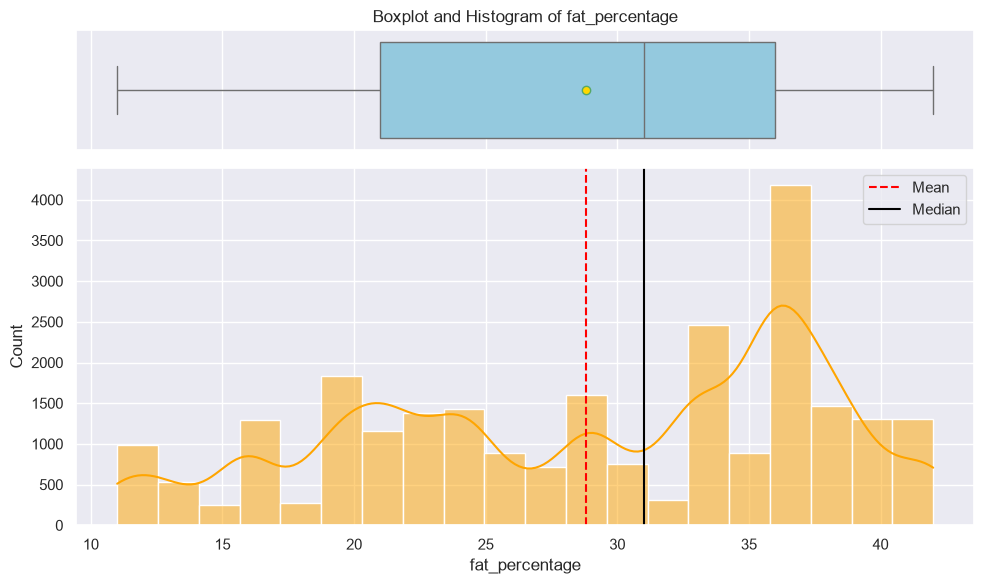

In [22]:
custplot_box_hist(df1, "fat_percentage", show_kde=True, box_color="skyblue", hist_color="orange")

In [23]:
df1["fat_percentage"].describe()

count    25000.000000
mean        28.812280
std          8.632382
min         11.000000
25%         21.000000
50%         31.000000
75%         36.000000
max         42.000000
Name: fat_percentage, dtype: float64

**Observations:**

- The mean of the data is around 28.8%, and the standard deviation is 8.63, which represents a moderately varying data set.
- The data varies between 11% and 42%, which is a realistic data range for the general population.
- Since the median (31%) is slightly greater than the mean, it represents a slightly left-skewed data distribution.
- From the histogram, it is observed that most of the individuals are clustered in the higher range of fat percentage, i.e., between 30% and 38%.
- Since there are no significant extreme values in the data, as observed in the boxplot, the data is relatively stable.

**Insights:**
- Since most of the individuals are in the high body fat percentage range, which represents the moderate to high level of health risks, the data may be significant.
- Since the fat percentage is directly related to health conditions, it may be considered a significant predictor of insurance costs, as the percentage may be on the higher side.


***avg_glucose_level***

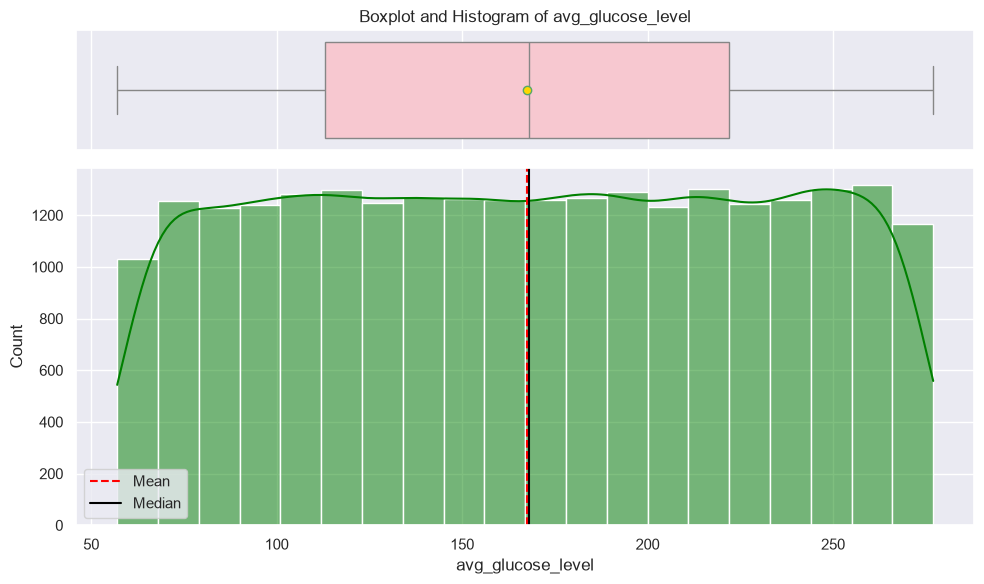

In [24]:
custplot_box_hist(df1, "avg_glucose_level", show_kde=True, box_color="pink", hist_color="green")

In [25]:
df1["avg_glucose_level"].describe()

count    25000.000000
mean       167.530000
std         62.729712
min         57.000000
25%        113.000000
50%        168.000000
75%        222.000000
max        277.000000
Name: avg_glucose_level, dtype: float64

**Observations:**

- The average is approximately 167.5 with considerable variability (standard deviation approximately 62.7).
- The data points vary widely between 57 and 277.
- The average and median are almost equal, suggesting a symmetric distribution.
- From the histogram, we can infer that the data is fairly distributed over the range with little evidence of peaks or skewing.
- The boxplot also shows that the data is widely distributed with little sign of extreme outliers.

**Insights:**
- The data set comprises a broad spectrum of individuals with varying glucose levels, possibly including diabetics.
- This data is likely to be a good predictor for insurance costs because higher glucose levels imply a higher risk for medical complications.

***daily_avg_steps***

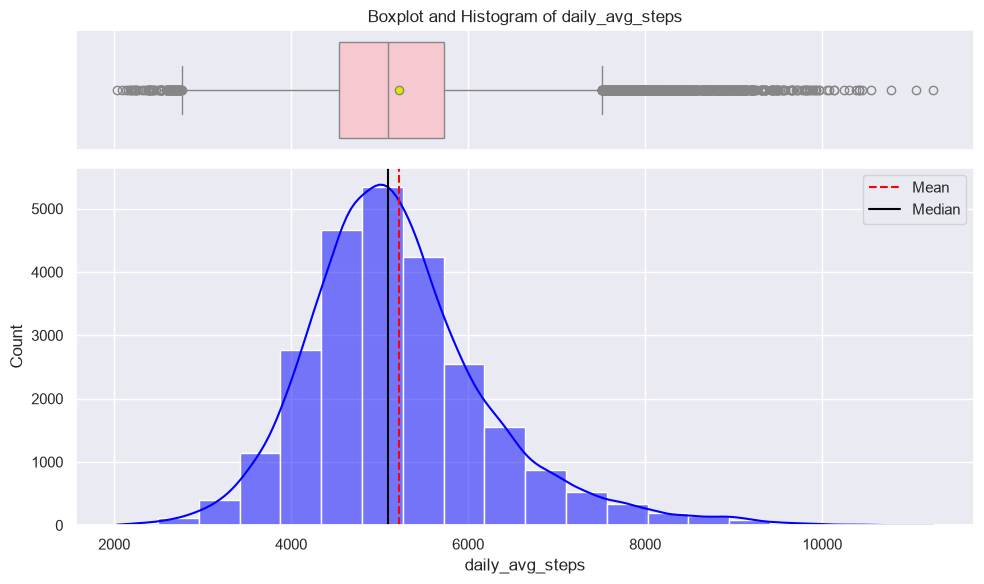

In [26]:
custplot_box_hist(df1, "daily_avg_steps", show_kde=True, box_color="pink", hist_color="blue")

In [27]:
df1["daily_avg_steps"].describe()

count    25000.000000
mean      5215.889320
std       1053.179748
min       2034.000000
25%       4543.000000
50%       5089.000000
75%       5730.000000
max      11255.000000
Name: daily_avg_steps, dtype: float64

**Observations:**

- The average daily steps are approximately 5,216 with a standard deviation of around 1,053.
- The data ranges from a minimum of 2,034 steps to a maximum of 11,255 steps.
- The median is slightly lower than the average at around 5,089.
- The data is slightly skewed to the right with a majority of individuals having daily steps between 4,500 and 5,700.
- The plot also indicates that there are a few individuals with high daily steps; however, there are no clear outliers in the data using the boxplot.

**Insights:**
- The majority of individuals appear to fall under a moderately active category.
- Physical activity is inversely related to health risks; therefore, daily steps are likely to have a negative relationship with insurance cost.

***BMI***

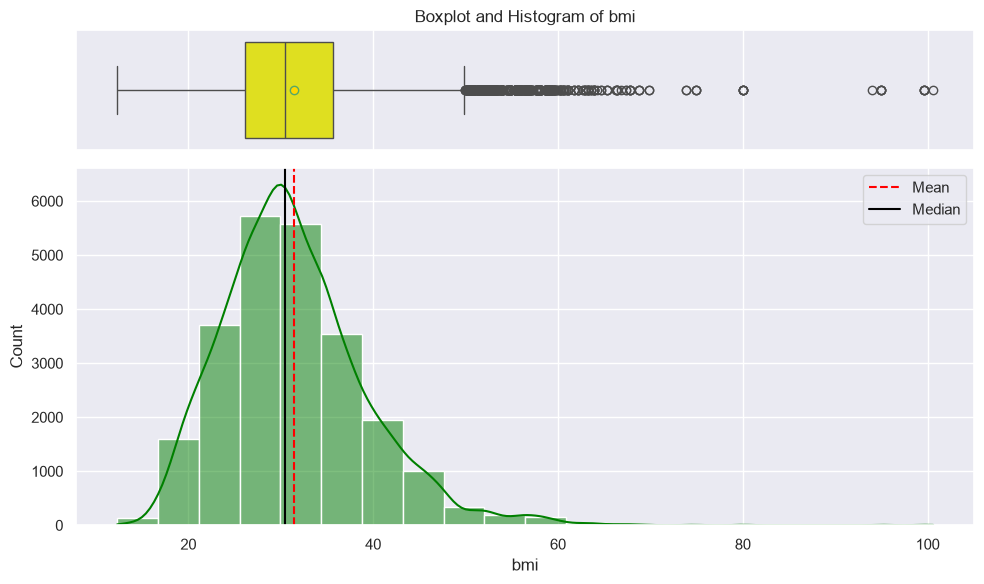

In [28]:
custplot_box_hist(df1, "bmi", show_kde=True, box_color="yellow", hist_color="green")

In [29]:
df1["bmi"].describe()

count    24010.000000
mean        31.393328
std          7.876535
min         12.300000
25%         26.100000
50%         30.500000
75%         35.600000
max        100.600000
Name: bmi, dtype: float64

**Observations:**

- On average, the BMI is 31.39, and the standard deviation is 7.88.
- The range is between a minimum of 12.30 and a maximum of 100.60.
- The median is slightly lower than the average, which is 30.50.
- The data is skewed towards the right, and most individuals have a BMI between 26.10 and 35.60, which is the interquartile range.
- The plot also suggests that there are a few individuals who have very high values of BMI.
- This is different from the sample data, as the boxplot clearly shows that there is a large number of outliers on the higher end of the distribution.


**Insights:**

- It appears that most individuals fall within the overweight and obese category, as the median is higher than 30.
- Body Mass Index (BMI) is generally directly proportional to health risks, so it is likely that the BMI will have a positive relationship with insurance costs or medical expenditures.

- The maximum value of 100.60 is highly improbable, suggesting that there is exception case of obesity or some error in the data, which is a common case where data inspection & cleaning is necessary.

- Moreover, there are 990 missing values in the variable "bmi". To avoid losing any of this information, the missing values will be handled by applying a method of imputation, as will be discussed in the Data Preprocessing section. This will also assist in stabilizing the distribution.

***insurance_cost (Target variable)***

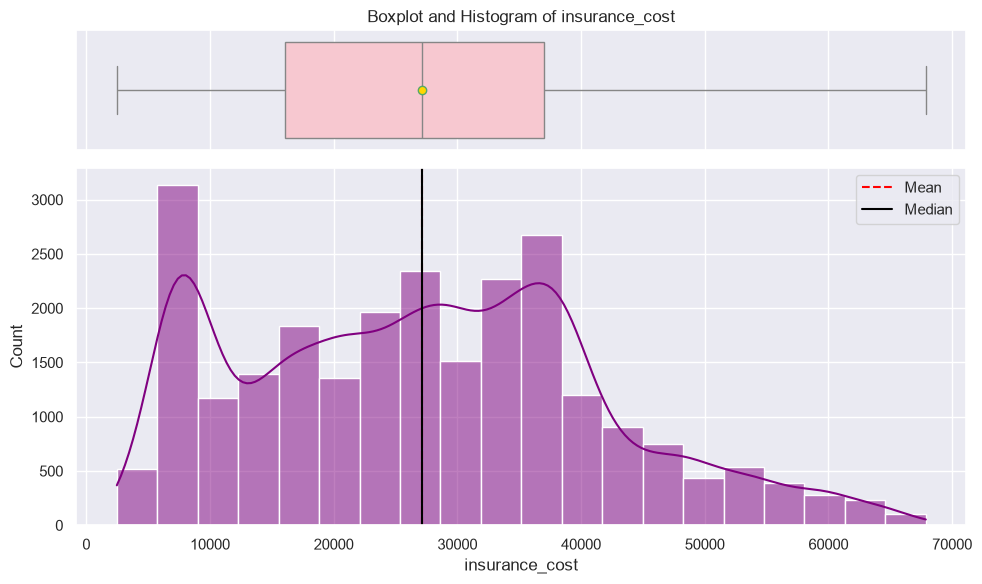

In [30]:
custplot_box_hist(df1, "insurance_cost", show_kde=True, box_color="pink", hist_color="purple")

In [31]:
df1["insurance_cost"].describe()

count    25000.000000
mean     27147.407680
std      14323.691832
min       2468.000000
25%      16042.000000
50%      27148.000000
75%      37020.000000
max      67870.000000
Name: insurance_cost, dtype: float64

**Observations:**

- The average insurance cost is around 27,147.41, with a standard deviation of around 14,323.69.
- The data ranges from a minimum insurance cost of 2,468 up to a maximum of 67,870.
- The median is almost similar to the average at around 27,148.
- The data is quite broad with a majority of individuals having their insurance costs between 16,042 and 37,020.
- The plot shows a multimodal distribution with multiple peaks.
- The boxplot also shows that there are no outliers; therefore, the high insurance costs are part of the data's normal extension.

**Insights:**

- The data for insurance costs is extremely diverse with a non-normal distribution.
- The data is multimodal with peaks at around 7,000 to 8,000 and another peak at around 35,000 to 38,000.
- This may imply that the data consists of multiple groups of individuals.
- The fact that the median is almost similar to the average implies that the data is almost perfectly symmetric with no skewness.

***weight***

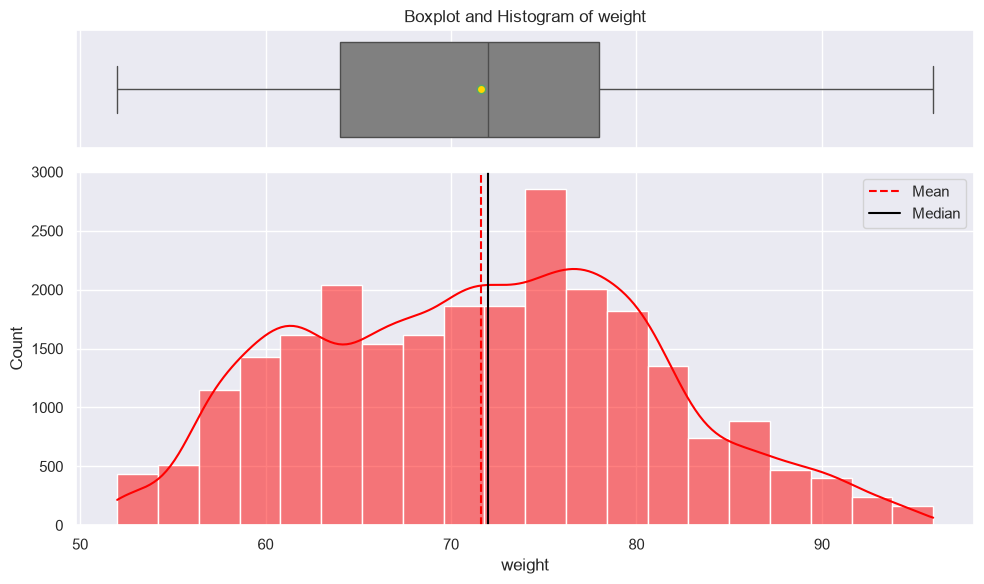

In [32]:
custplot_box_hist(df1, "weight", show_kde=True, box_color="gray", hist_color="red")

In [33]:
df1["weight"].describe()

count    25000.000000
mean        71.610480
std          9.325183
min         52.000000
25%         64.000000
50%         72.000000
75%         78.000000
max         96.000000
Name: weight, dtype: float64

**Observations:**

- On average, the weight is around 71.61 units, and the standard deviation is around 9.33 units.
- The minimum weight is 52 units, and the maximum is 96 units.
- The median is slightly higher than the average at 72 units.
- There is a slight skewness to the left; however, the majority of the individuals fall between 64 units and 78 units (interquartile range).
- here are also a number of peaks; however, there are no statistical outliers according to the box plot.

**Insights:**

- There are a number of peaks in the distribution (for example, 64 units and 75 units), which may indicate the presence of a number of subpopulations (for example, males and females, short and tall individuals).
- However, the proximity between the mean (71.61 units) and median (72 units) suggests that even though the peaks are present, the overall distribution is balanced and symmetrical without a high skewness.
- There are no statistical outliers; the range (52 units to 96 units) is well within the normal limits for human beings.

***regular_checkup_lasy_year***

regular_checkup_lasy_year
0    15215
1     4644
2     2198
3     1818
4      777
5      348
Name: count, dtype: int64




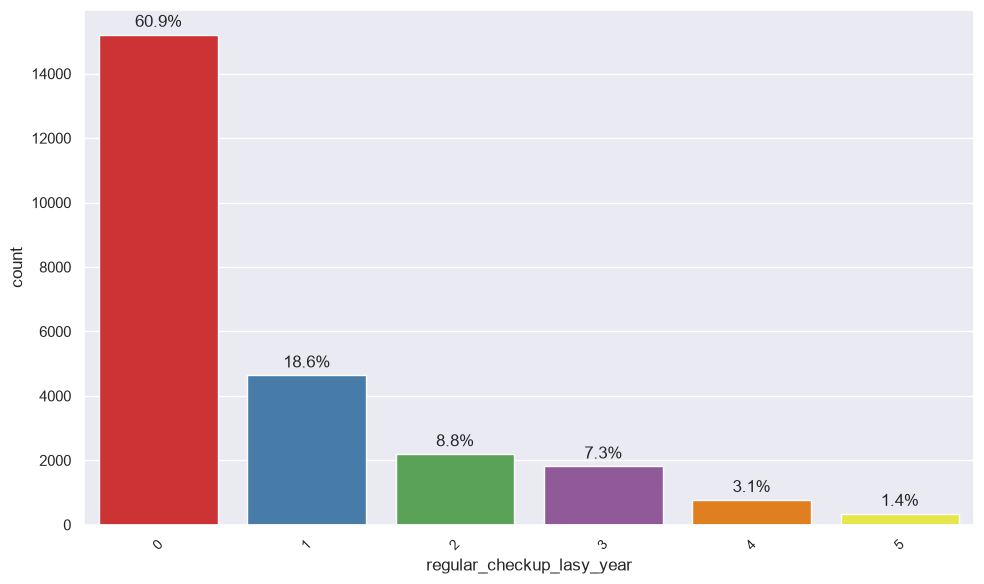

In [34]:
cust_label_barplot(df1, "regular_checkup_lasy_year", palette="Set1", show_percent=True)

**Observations:**

- The mean number of regular checkups is about 0.77, and the standard deviation is about 1.13.
- The data varies between a minimum of 0 checkups and reaches up to a maximum of 5 checkups.
- The median number of checkups is also 0.
- There is significant skewness to the right, indicating that most individuals have fewer than 5 checkups, with the vast majority of individuals (about 79.5% of the total population) having either 0 or 1 checkups.
- From the plot, the data points are decreasing sharply as the number of checkups increases, and only a small percentage of individuals (1.4%) have attended 5 checkups last year.

**Insights:**

- There is a large number of individuals who have zero checkups (about 60.9%), indicating that the level of preventative care is low.
- It is generally understood that regular health checkups are important for early disease treatment and can result in reduced healthcare costs in the future; as such, the number of individuals with zero checkups may have a positive relationship with the costs of future insurance.


***years_of_insurance_with_us***

years_of_insurance_with_us
3    2990
8    2970
5    2941
0    2912
7    2873
1    2856
4    2846
6    2804
2    1808
Name: count, dtype: int64




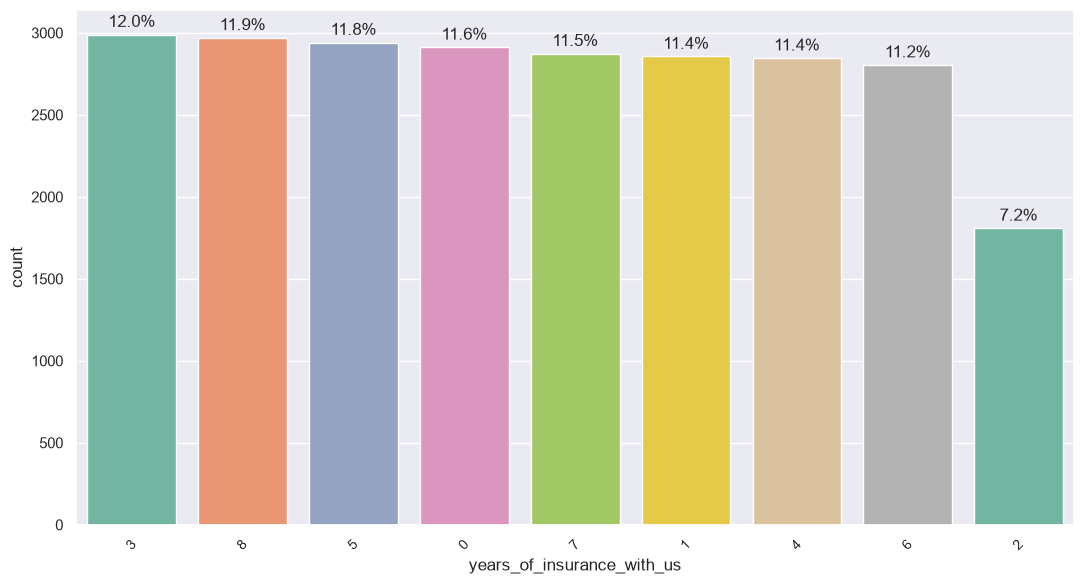

In [35]:
cust_label_barplot(df1, "years_of_insurance_with_us", palette="Set2", show_percent=True)

**Observations:**

- The average years of insurance tenure is around 4.23, and the standard deviation is around 2.62.

- The data varies between the minimum of 0 years and the maximum of 8 years.

- The median years of insurance tenure is at 4.

- The data appears to be uniformly distributed, apart from the data point at 2 years, which has dropped significantly to 7.2%.

- From the plot, the highest single tenure appears to be at 3 years, at 12.0%, while the lowest single tenure appears to be at 2 years.


**Insights:**

- It appears that there is some form of anomaly in the data, given the sudden, unnatural drop to 7.2% at the 2-year tenure group.

- However, given that the data appears to be uniformly distributed across all the years, apart from the 2-year group, it appears that the data represents a well-balanced dataset of brand-new customers, as well as long-term legacy customers.

- It appears that the longer the insurance tenure, the more likely the customer is to be given loyalty discounts, and as such, the insurance costs are likely to have an inverse relationship with the years of insurance tenure.

***Age***

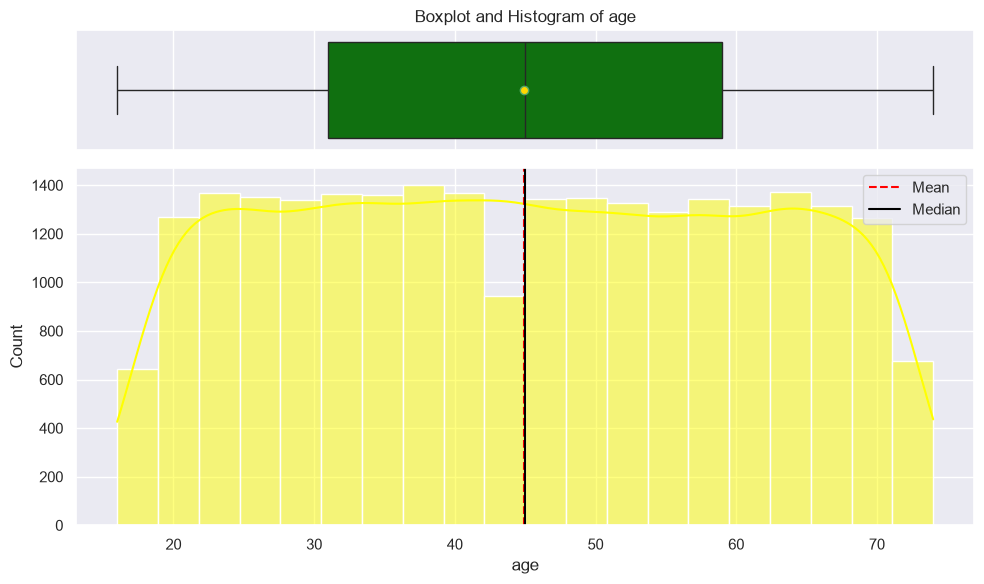

In [36]:
custplot_box_hist(df1, "age", show_kde=True, box_color="green", hist_color="yellow")

In [37]:
df1["age"].describe()

count    25000.000000
mean        44.918320
std         16.107492
min         16.000000
25%         31.000000
50%         45.000000
75%         59.000000
max         74.000000
Name: age, dtype: float64

**Observations:**

- The average customer age is approximately 44.92 with a standard deviation of around 16.
- The minimum age is 16, and the maximum is 74.
- The median age is 45, which is very close to the mean.
- Most of the values are uniformly distributed, with the majority between 31 and 59 (the interquartile range).
- There appears to be a sudden and unnatural drop in the plot for the individuals between 42 and 45 years old. The boxplot does not show any statistical outliers.



**Insights:**

- There appears to be a sudden and unnatural drop in the plot for the individuals between 42 and 45 years old. This is unusual for a normal demographic set and may indicate a error in the data collection process.

- Excluding the extremes (those under 20 and over 70), the data appears to be relatively flat and uniform. This means the business has a balanced demographic for young adults, mid-life adults, and seniors.

- Age is a major factor for actuary and health calculations; therefore, it is expected to have a high positive correlation with healthcare utilisation and costs.

***adventure_sports***

adventure_sports
0    22957
1     2043
Name: count, dtype: int64




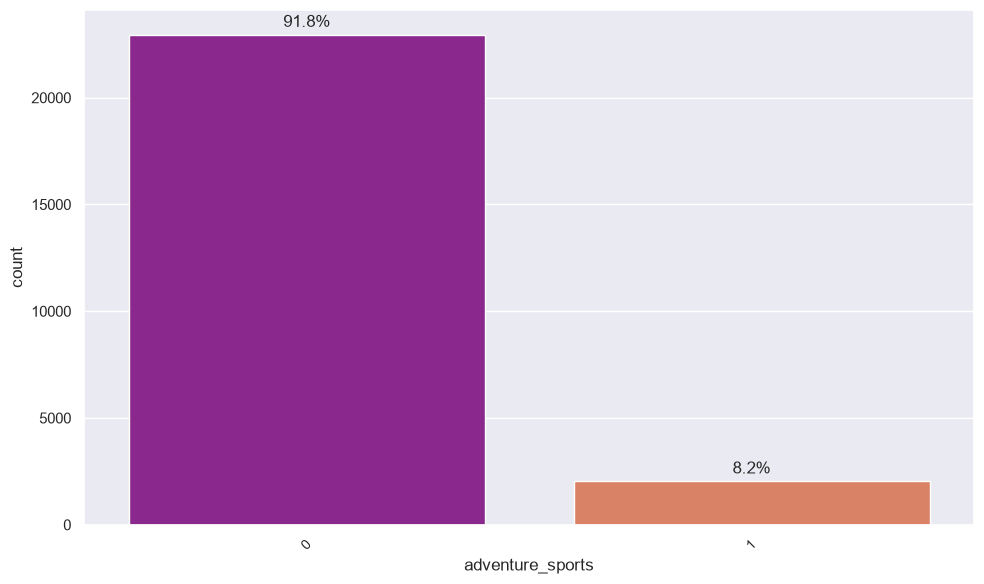

In [38]:
cust_label_barplot(df1, "adventure_sports", palette="plasma", show_percent=True)

**Observations:**

- The data type is binary, where 0 denotes the absence and 1 denotes the presence of adventure sports participation.

- The data range is from a minimum of 0 to a maximum of 1.

- The median is also 0.

- The data is highly skewed, with 91.8% of individuals not participating in adventure sports and the remaining 8.2% participating in the same.

- From the plot, we can clearly see that there is a huge class imbalance between the two data points.


**Insights:**

- The high skewness in the data indicates that the population that participates in adventure sports is a minority class.

- Adventure sports participants are more likely to have a high chance of physical injury or accidents; therefore, this data is likely to have a positive correlation with insurance costs or medical expenditure claims.


***visited_doctor_last_1_year***

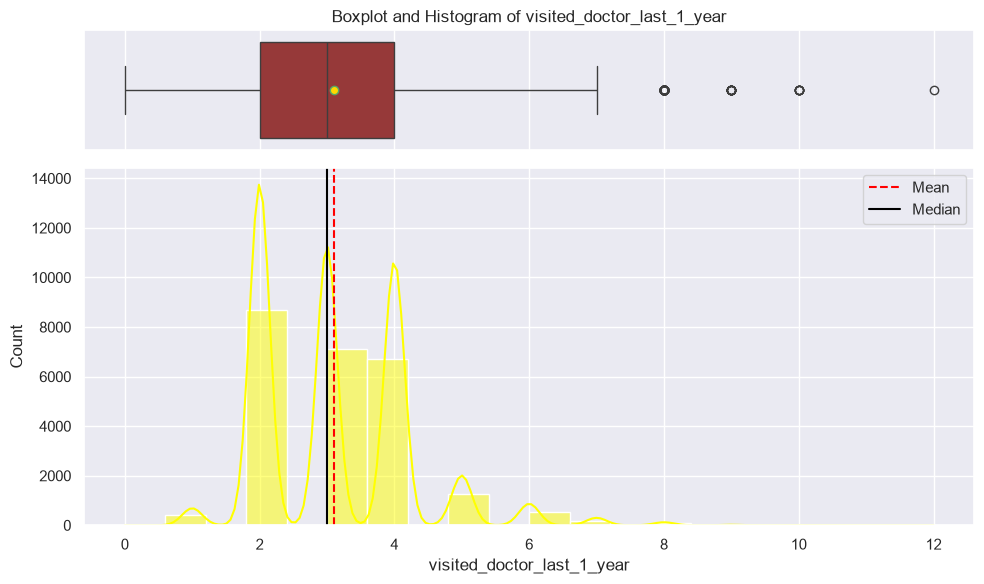

In [39]:
custplot_box_hist(df1, "visited_doctor_last_1_year", show_kde=True, box_color="brown", hist_color="yellow")

In [40]:
df1["visited_doctor_last_1_year"].describe()

count    25000.000000
mean         3.104200
std          1.141663
min          0.000000
25%          2.000000
50%          3.000000
75%          4.000000
max         12.000000
Name: visited_doctor_last_1_year, dtype: float64

**Observations:**

- The average number of doctor visits is approximately 3, with a standard deviation of about 1.14.
- The range of the data set goes from a minimum of 0 visits to a maximum of 12 visits.
- The median number of doctor visits is 3, which is almost identical to the mean.
- The data set is skewed towards the right, with a majority of individuals making between 2 and 4 visits to the doctor (interquartile range).
- The plot also suggests a heavy concentration of individuals making 2-4 visits, with the boxplot mathematically indicating outliers above 7 visits as statistical outliers.

**Insights**

- The high alignment of the mean and median suggests that, even though the data set itself is skewed, the mean and median are extremely stable.
- The frequency of visits to the doctor is generally a indicator of an individual's underlying health status, so a high rate of visits should be positively correlated with insurance costs or medical expenditures.
- The outliers, i.e., individuals making 10 or 12 visits, are mathematically indicated as outliers , as shown in the boxplot.

***heart_decs_history***

heart_decs_history
0    23634
1     1366
Name: count, dtype: int64




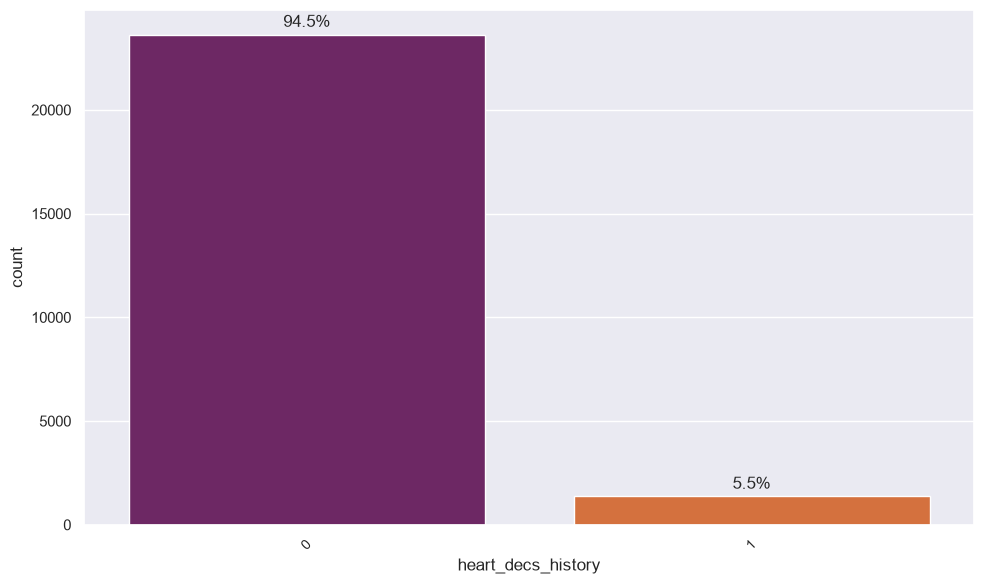

In [41]:
cust_label_barplot(df1, "heart_decs_history", palette="inferno", show_percent=True)

**Observations:**

- The data set is a binary set where 0 indicates no history of heart disease and 1 indicates a history of heart disease.

- The minimum value of the set is 0 and the maximum is 1.

- The median of the set is 0.

- The dataset is highly skewed with 94.5% of people having no history of heart disease and only 5.5% of people having a history of heart disease.

- The plot of the set indicates a stark class imbalance between both sets of people.


**Insights:**

- The high degree of skewness in the set indicates that having a history of heart disease is a rare occurrence in this set of people and hence forms a minority class.

- Having a history of heart disease increases the risk of medical claims and hence is related to insurance costs in a positive manner.

- The class imbalance is severe with the majority class being greater than the minority class.

***other_major_decs_history***

other_major_decs_history
0    22546
1     2454
Name: count, dtype: int64




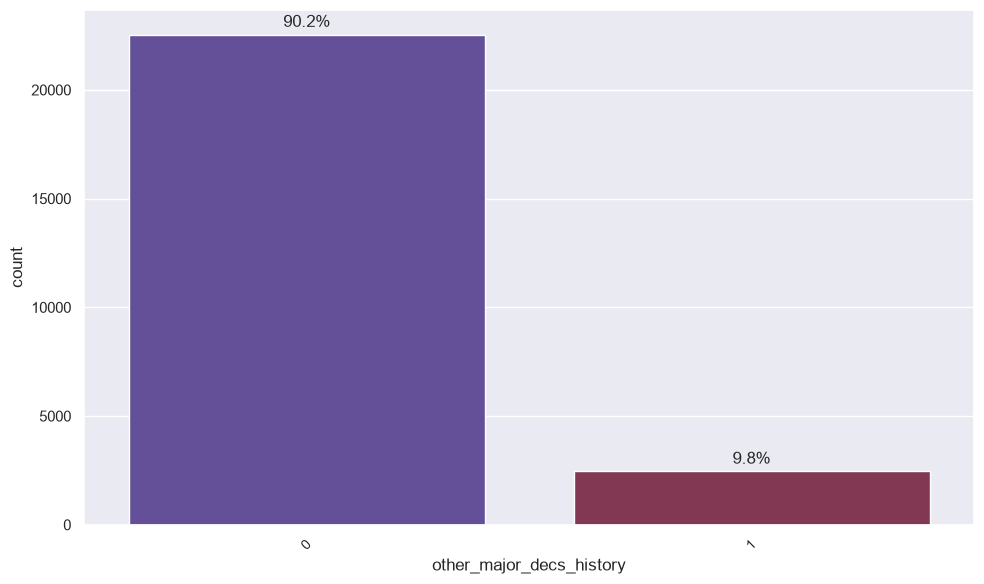

In [42]:
cust_label_barplot(df1, "other_major_decs_history", palette="twilight", show_percent=True)

**Observations:**

* The data points are binary in nature, where 0 represents the absence and 1 represents the presence of other major disease histories.
* The range of the data points is from 0 to 1.
* The median of the data points is 0.
* The data points are highly skewed, with 90.2% of the population showing no other major disease histories and 9.8% showing a positive history.
* The plot shows a high level of stark class imbalance between the two classes.


**Insights:**

* The high level of skewness in the data, with 90.2% of the population showing no other major disease histories, suggests that the presence of other major disease histories is a minority in this population.
* A history of other major disease histories or surgeries generally points towards high risk levels in underwriting; hence, this factor can be expected to have a positive correlation with premium or claim costs.
* The level of class imbalance in this dataset is extremely high, with the majority class(0) significantly higher than the minority class(1).

***Year_last_admitted***

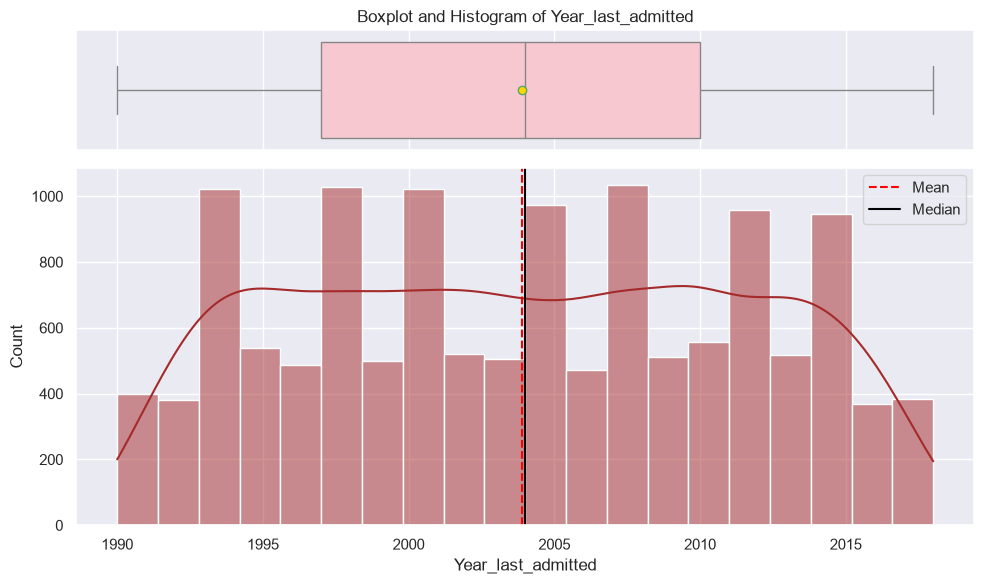

In [43]:
custplot_box_hist(df1, "Year_last_admitted", show_kde=True, box_color="pink", hist_color="brown")

In [44]:
df1["Year_last_admitted"].describe()

count    13119.000000
mean      2003.892217
std          7.581521
min       1990.000000
25%       1997.000000
50%       2004.000000
75%       2010.000000
max       2018.000000
Name: Year_last_admitted, dtype: float64

**Observations:**

- The average year of last admission is approximately 2003.89. The standard deviation of this figure is around 7.58.
- The range of the data varies from a minimum year of 1990 to a maximum year of 2018.
- The median year of last admission is 2004. This figure is almost identical to the mean.
- The range of the data is relatively uniformly distributed between the interquartile range of 1997 and 2010. The distribution of the data is multi-modal (spiky) as well.
- The boxplot of the data indicates that it is well-contained within the range of 1990 and 2018. There are no mathematical outliers.
- We already know that the number of missing values for the Year_last_admitted feature is 11,881. The total number of rows of the dataset is 25,000. Therefore, it accounts for approximately 47.52% of the data being missing.


**Insights:**

- The periodic peaks (in 1994, 1998, 2001, 2008, 2012, 2015, etc.) suggest periodic variations in hospitalizations, which could be related to certain patterns in recording or sampling.
- As the median year is 2004, a large proportion of the population hasn't been hospitalized in over a decade.

- The recency of hospitalization, or the fact that hospitalization occurred closer to the present (i.e., closer to 2018 than the 1990s), could be a significant factor in determining the premium for a patient, with higher premiums for those hospitalized closer to 2018 compared to the 1990s.

***weight_change_in_last_one_year***

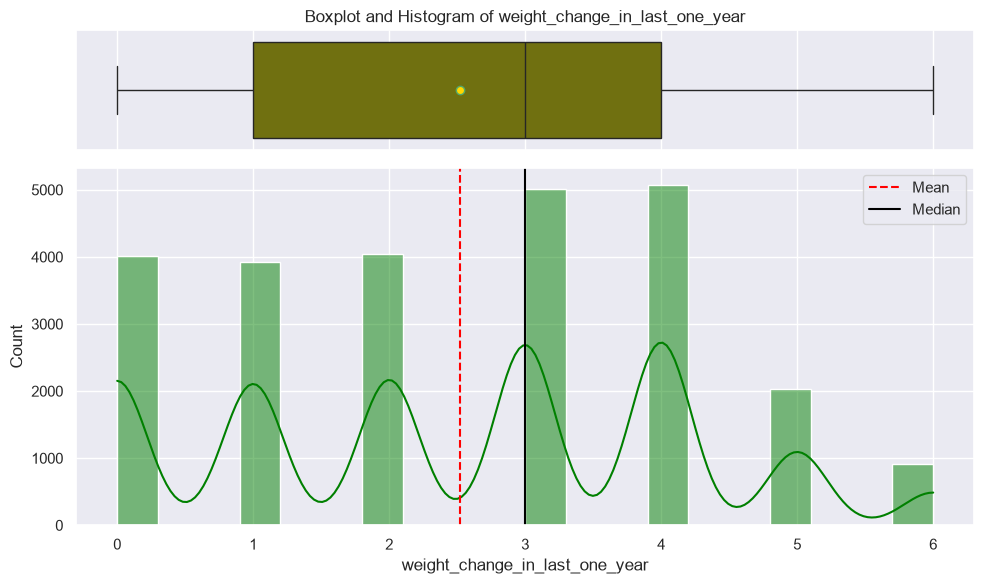

In [45]:
custplot_box_hist(df1, "weight_change_in_last_one_year", show_kde=True, box_color="olive", hist_color="green")

In [46]:
df1["weight_change_in_last_one_year"].describe()

count    25000.000000
mean         2.517960
std          1.690335
min          0.000000
25%          1.000000
50%          3.000000
75%          4.000000
max          6.000000
Name: weight_change_in_last_one_year, dtype: float64


**Observations:**

- The average weight change is about 2.52 units, and the standard deviation is about 1.69 units.
- The data varies between the smallest value of 0 units and the highest value of 6 units.
- The median weight change is about 3 units, which is slightly higher than the mean of 2.52 units.
- The data appears to be multi-modal, and the data has peaks at every whole number integer (0, 1, 2, 3, and 4), suggesting that the data is likely recorded as whole numbers.
- The boxplot indicates that the data is perfectly contained between 0 and 6, with no mathematical outliers.


**Insights:**
- A very high level of data points being multi-modal and peaking only at whole numbers suggests that the data has experienced some form of standard data rounding or binning during the data collection process.
- A history of weight fluctuation is generally a reflection of a change in lifestyle, diet, or metabolic conditions, and this factor is likely to have a positive correlation with premium or claim costs.
- The absence of any outliers suggests that the level of stability in this data is extremely high.

###**Univariate Analysis on categorical variables**

- We will now do univariate analysis on categorical columns to understand their distributions & proportins

***Occupation***

Occupation
Student     10169
Business    10020
Salried      4811
Name: count, dtype: int64




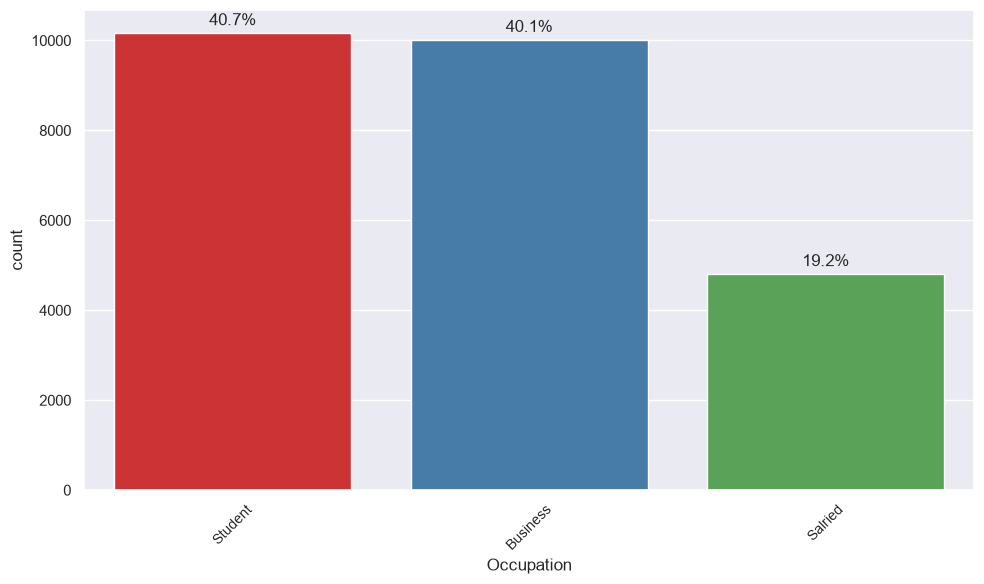

In [47]:
cust_label_barplot(df1, "Occupation", palette="Set1", show_percent=True)

**Observations:**

- The dataset is categorical in nature, representing 3 distinct career classifications of the customer.
- The range of data points covers all Student, Business, and Salried categories.
- The data points indicate that the majority of the population is either Students (40.7%) or Business owners (40.1%), whereas the population that is categorized as Salried is the minority (19.2%).
- The plot indicates that there is a visible class imbalance, where the Student and Business data are greater than twice that of the Salried individuals.

**Insights:**
- The high level of representation for the Student category (40.7%) indicates that a large percentage of this data set is comprised of younger demographics, which generally correlate with a lower baseline medical risks, but a higher potential for retaining policy over the long term.
- A history of an employment type, such as Business or Salried, generally correlates with different stress profiles, different levels of physical exertion, or different income stability, which will have a direct correlation with premium or claim costs.
- The level of class imbalance within this data is moderate, where the Salried class is significantly lower than the other two classes.


***cholesterol_level***

cholesterol_level
150 to 175    8763
125 to 150    8339
200 to 225    2963
175 to 200    2881
225 to 250    2054
Name: count, dtype: int64




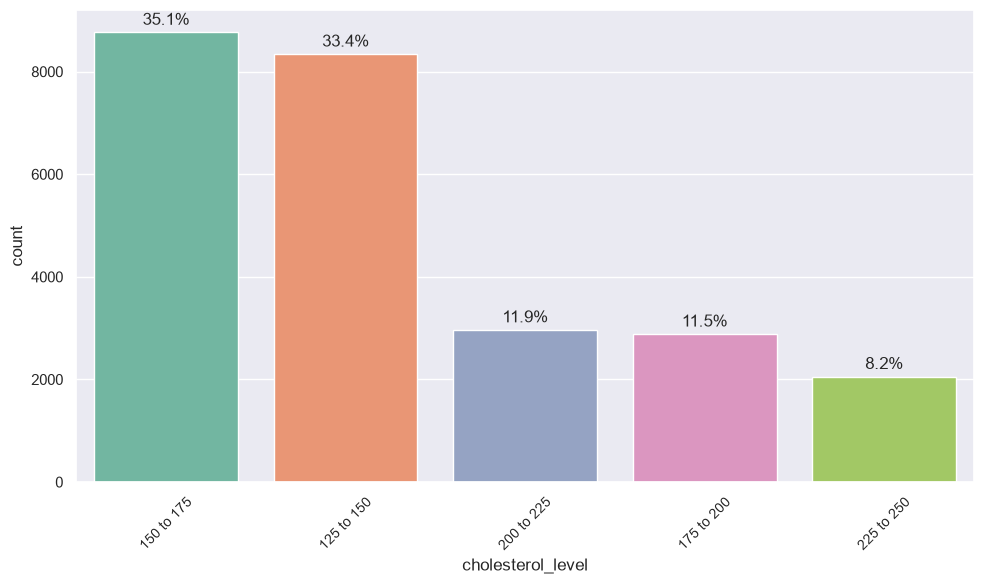

In [48]:
cust_label_barplot(df1, "cholesterol_level", palette="Set2", show_percent=True)

**Observations:**

- The data points are categorical in nature, representing five distinct cholesterol level (medical unit is in mg/dL) ranges of individuals.
- The range of the data points spans from 125 to 150 mg/dL up to 225 to 250 mg/dL.
- From the data points, we see that the distribution is highly concentrated in the lower ranges of 150 to 175 (35.1%) and 125 to 150 (33.4%), while the higher ranges, such as 225 to 250, are a minority (8.2%).
- From the bar plot, we see that there is a visible class imbalance, where the lower ranges of cholesterol are nearly four times as common as the highest range.

**Insights:**

- Given that there is a high level of representation in the lower ranges of cholesterol (68.5% combined for all ranges less than 175), this suggests that this customer population is generally a healthy population.
- Given that a history of higher levels of cholesterol (above 200 mg/dL) generally indicates a higher level of cardiovascular risk, this factor is likely to have a positive correlation with premium or claim costs.


***Gender***

Gender
Male      16422
Female     8578
Name: count, dtype: int64




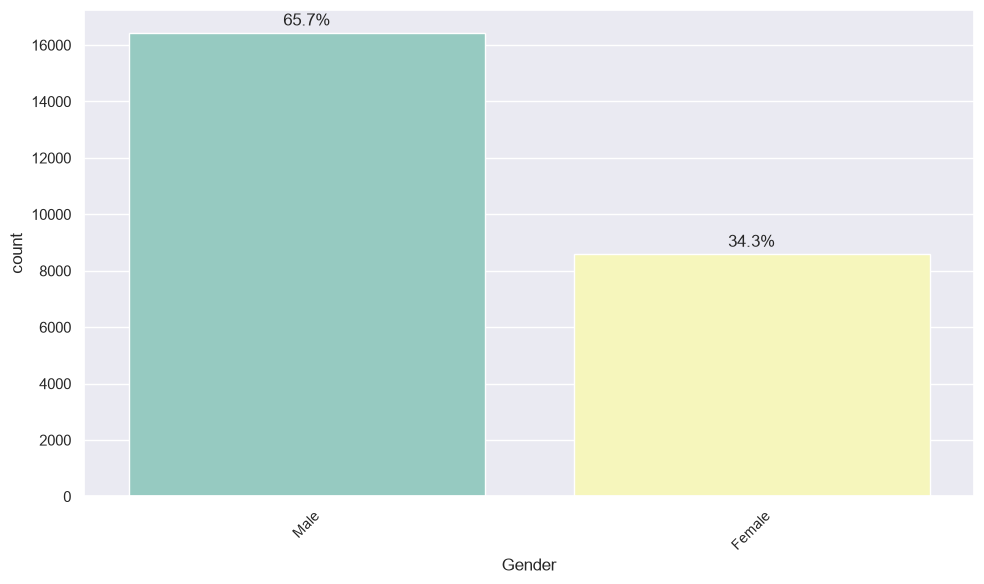

In [49]:
cust_label_barplot(df1, "Gender", palette="Set3", show_percent=True)

**Observations:**
- The data points are of binary types, where the data categories represent Male and Female types.
- The range of data points covers two different classes of genders.
- The data points clearly indicate that the distribution is highly concentrated for Males (65.7%), where Females constitute a minority class (34.3%).
- The plot indicates that there is a clear class imbalance, where Males are almost twice as common as Females.

**Insights:**
- The clear majority (65.7%) of Males in the data representation indicates that this data may be biased towards occupations or history where males have traditionally been the primary policy holders.
- A history of gender classifications generally implies a difference in actuarial risks and life expectancies, which is a direct factor that could be correlated with costs.
- The class imbalance is moderate, where the Female data point is significantly lower compared to the Male class.

***smoking_status***

smoking_status
never smoked       9249
Unknown            7555
formerly smoked    4329
smokes             3867
Name: count, dtype: int64




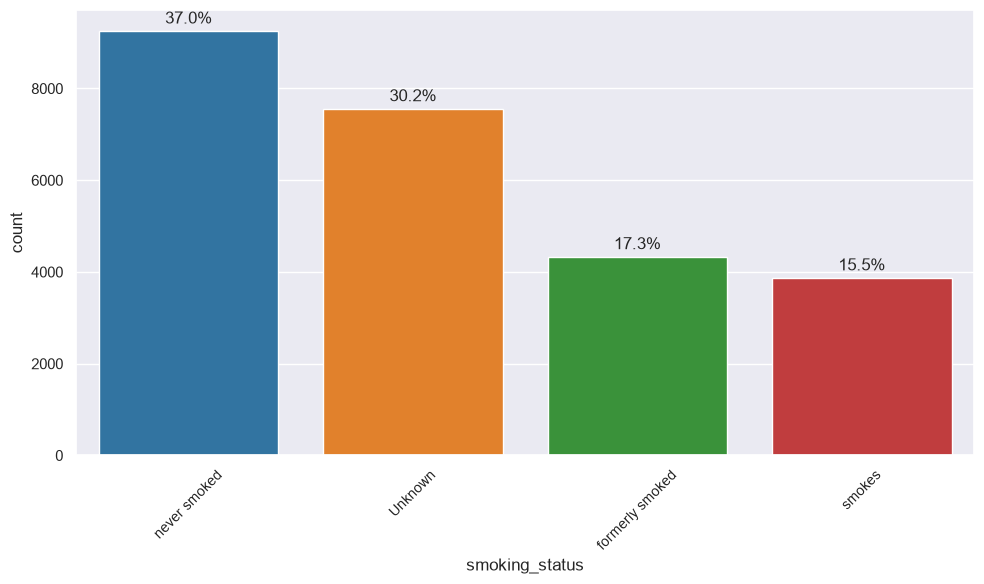

In [50]:
cust_label_barplot(df1, "smoking_status", palette="tab10", show_percent=True)

**Observations:**

- The data points are of a categorical nature, showing different smoking behavioral classes of the population under consideration.
- The range of data points varies from never smoked, Unknown, formerly smoked, and smokes.
- From the data points, it is clear that the highest proportion of people belongs to those who have never smoked (37.0%) and Unknown (30.2%), and those who are currently smoking are in the minority class (15.5%).
- From the bar plot, it is evident that there is class imbalance in the data, as those who have never smoked are more than double the number of people who are currently smoking.

**Insights:**
- The highest proportion of people belonging to the Unknown class (30.2%) indicates that there is incomplete information provided by the applicants, which is a major risk of information asymmetry for insurance companies.
- The class of people who are currently smoking (smokes) indicates a higher risk of respiratory and cardiovascular risks, so it is expected that this factor would have a very high positive correlation with risk levels.
- The class imbalance of this data is moderate, and the class having the least number of people is the smokes class.

***Location***

Location
Bangalore      1742
Jaipur         1706
Bhubaneswar    1704
Mangalore      1697
Delhi          1680
Ahmedabad      1677
Guwahati       1672
Chennai        1669
Kanpur         1664
Nagpur         1663
Mumbai         1658
Lucknow        1637
Pune           1622
Kolkata        1620
Surat          1589
Name: count, dtype: int64




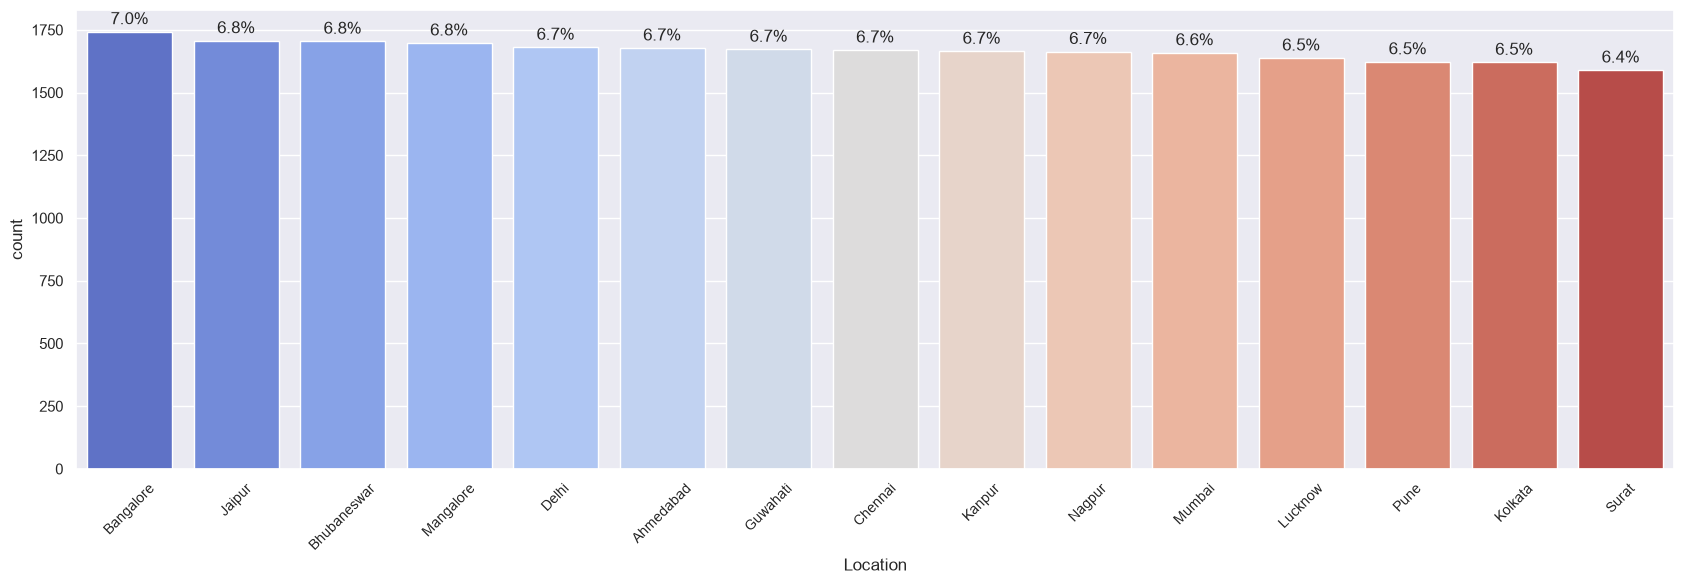

In [51]:
cust_label_barplot(df1, "Location", palette="coolwarm", show_percent=True)

**Observations:**
- The data points are categorical in nature, representing fifteen different city-based geographical classifications of the population under study.
- The range of data points extends across major Indian geographical hubs such as Bangalore and Surat.
- The data points also show that the distribution is almost perfectly uniform across all fifteen cities, with the highest concentration being in Bangalore (7.0%) and the lowest being in Surat (6.4%).
- The plot also shows that there is no class imbalance issue in the data set, with all 15 geographical locations being represented within a tight range of 6.4% to 7.0%.

**Insights:**
- The data points show that the distribution is almost perfectly uniform across fifteen major urban hubs, therefore, this data sampling approach is extremely well-balanced with no regional biases.
- A history of geographical locations usually implies a direct correlation with regional healthcare infrastructure costs, pollution indexes, and cost-of-living adjustments in underwriting.
- The class imbalance issue in the data set is almost zero.

***covered_by_any_other_company***

covered_by_any_other_company
N    17418
Y     7582
Name: count, dtype: int64




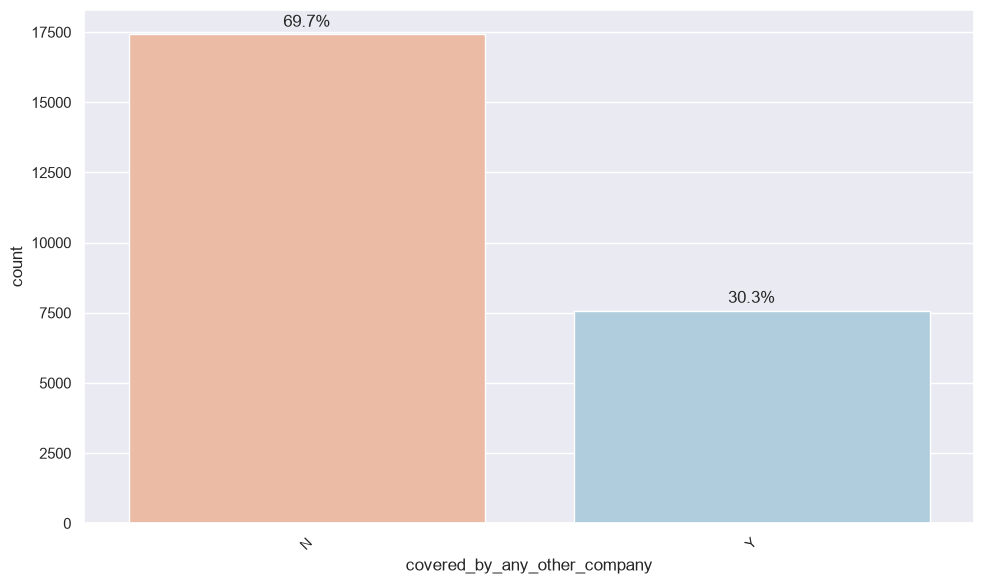

In [52]:
cust_label_barplot(df1, "covered_by_any_other_company", palette="RdBu", show_percent=True)

**Observations:**
- This attribute essentially represents binary information, i.e., whether or not the applicants have overlapping coverage with a secondary insurance provider.
- The range of this attribute is restricted to a binary classification, Y (Yes) or N (No).
- Approximately 70% (69.7%) of the population does not have external coverage, while approximately 30% (30.3%) of the population holds other companies' insurance policies.
- From the above visualization, we can also see that the distribution of the classes in this attribute is highly skewed, with the number of individuals without coverage being over twice as large as the number of individuals with coverage.

**Insights:**
- A high proportion of individuals in the population (approximately 69.7%) are found to be without other coverage, which could mean that the company might be the sole risk bearer for the vast majority of the portfolio.
- Having secondary coverage can be a financial safety net against large claim liabilities, so this attribute should theoretically be negatively correlated with the firm's claim liabilities.
- The distribution of this attribute in the population is somewhat imbalanced.

***Alcohol***

Alcohol
Rare     13752
No        8541
Daily     2707
Name: count, dtype: int64




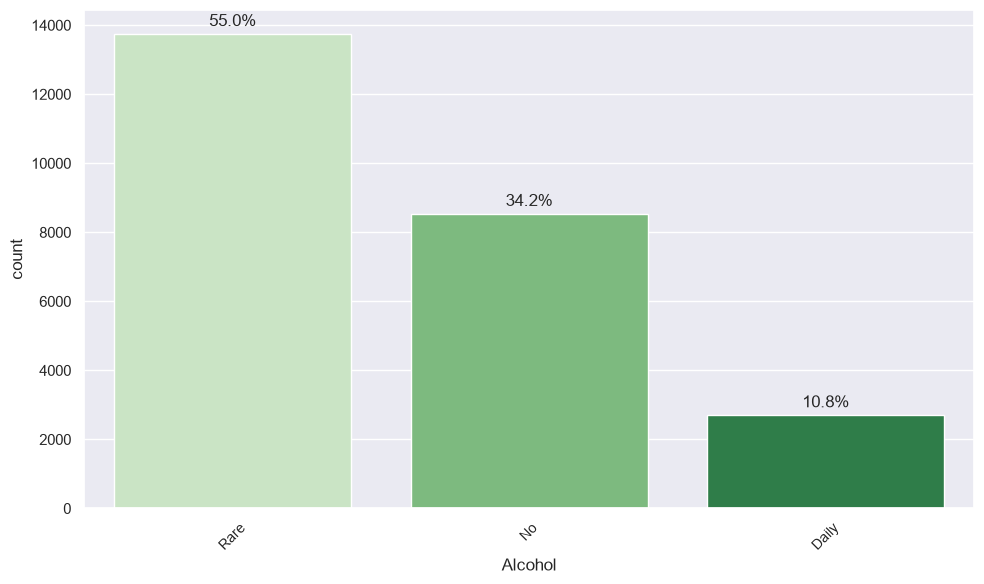

In [53]:
cust_label_barplot(df1, "Alcohol", palette="Greens", show_percent=True)

**Observations:**
- The feature is qualitative, as it categorizes the alcohol consumption patterns of the surveyed population into three ordinal categories.
- The categories include the Rare, No, and Daily consumption brackets.
- The majority of the population (55.0%) fall into the Rare category of alcohol consumption, followed by a smaller segment (34.2%) of people who do not drink at all, and a minor segment (10.8%) of people who drink alcohol every day.
- The visual representation of the feature clearly shows a large class imbalance, as the Rare category of alcohol consumption is more than five times larger than the segment of people consuming alcohol every day.

**Insights:**
- The large proportion of Rare and No alcohol consumption categories (89.2%) suggests that the majority of the portfolio has a low-to-moderate lifestyle profile.
- The health risks of frequently or daily consuming alcohol include a higher probability of metabolic, cardiovascular, and liver diseases. Therefore, this feature should theoretically show a positive correlation with the cost of underwriting and premiums.
- The structural distribution of this feature is moderately imbalanced.

***Exercise***

exercise
Moderate    14638
Extreme      5248
No           5114
Name: count, dtype: int64




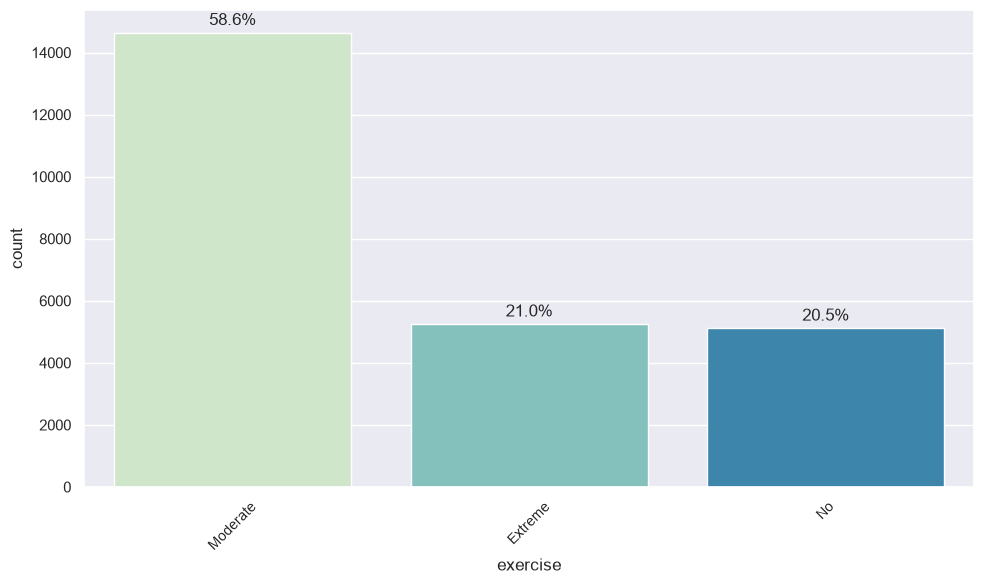

In [54]:
cust_label_barplot(df1, "exercise", palette="GnBu", show_percent=True)

**Observations:**
- This feature can be classified as categorical, as it defines the physical activity patterns of the sampled population, which fall within three different categories.
- These categories are spread out along the scale of Moderate, Extreme, and No Exercise.
- The results reveal that almost 60% (58.6%) of the population are Moderately physically active, 21% are undertaking Extreme physical training, and a meager 20.5% are in the category of people with No Exercise.
- The results also reveal that the distribution of the categories, particularly in the Moderate category, indicates a high level of skewness, as this category is almost three times larger than the Extreme and No Exercise categories.

**Insights:**
- The high proportion of Moderately physically active individuals in the population suggests that the majority of the portfolio comprises individuals with a healthy, active lifestyle.
- Individuals with Sedentary Lifestyle (No Exercise) are known to be at a high risk of heart disease, and individuals with Extreme physical training are at a risk of sports injury; thus, these two categories are expected to have different correlations with respect to policy costs and premium payouts.
- The distribution of this category can be classified as moderately imbalanced.

###**Binary Encoding of Categorical variables**

**Before proceeding to bivariate analysis, let us first create a copy of current data frame and then encode variables.**

In [55]:
# Create a copy of our main dataframe to avoid any accidental change in the dataset.
df2 = df1.copy()

**We will now do binary encoding (Mapping to 0 and 1) columns having for simple Yes/No or Male/Female, covered_by_any_other_company columns.**
**For columns where the categories have a natural ranking from low to high, we will use ordinal mapping:**

  - Alcohol (No = 0, Rare = 1, Daily = 2)

  - exercise (No = 0, Moderate = 1, Extreme = 2)

  - cholesterol_level (125 to 150 = 0, 150 to 175 = 1, etc.)

In [56]:
# Binary Mapping (0 and 1 for simple Yes/No or Male/Female)
df2['Gender'] = df2['Gender'].map({'Male': 0, 'Female': 1})
df2['covered_by_any_other_company'] = df2['covered_by_any_other_company'].map({'N': 0, 'Y': 1})


# Ordinal Mapping (Low to High natural rankings):

# 1. Alcohol Mapping
df2['Alcohol'] = df2['Alcohol'].map({'No': 0, 'Rare': 1, 'Daily': 2})

# 2. Exercise Mapping
df2['exercise'] = df2['exercise'].map({'No': 0, 'Moderate': 1, 'Extreme': 2})

# 3. Cholesterol Mapping
cholesterol_order = {
    '125 to 150': 0,
    '150 to 175': 1,
    '175 to 200': 2,
    '200 to 225': 3,
    '225 to 250': 4
}
df2['cholesterol_level'] = df2['cholesterol_level'].map(cholesterol_order)


# Preview the results to verify
df2[['Gender', 'covered_by_any_other_company', 'Alcohol', 'exercise', 'cholesterol_level']].head()

,Gender,covered_by_any_other_company,Alcohol,exercise,cholesterol_level
0,0,0,1,1,0
1,0,0,1,1,1
2,1,0,2,2,3
3,1,1,1,0,2
4,0,0,0,2,1


**Observations:**
- We can observe that we have successfully implemented binary and ordinal mapping on relevant columns to facilitate further analysis.

##**Bivariate Analysis**

**Feature Selection Strategy for Bivariate Analysis**

The bivariate analysis is intended to reveal how individual features affect the target variable (insurance_cost) and find significant associations among health-related features.

**Feature combinations are selected according to:**
- Statistical signals obtained during correlation analysis
- Knowledge of healthcare risk factors and insurance cost
- The need to remain simple by focusing only on high-impact features without redundancy


---
**1. Target vs Numerical Features**

This category of features is intended to reveal how numerical features directly influence insurance cost.

The selected features include:
- **Body composition**: weight, bmi, fat_percentage, age  
- **Clinical features**: avg_glucose_level
- **Lifestyle activity**: daily_avg_steps  


These features are often used in insurance cost analysis to determine an individual's health risk factors.  
Regression plots are used to reveal trends and the nature of associations.

---

**2. Target vs Categorical Features**

This category of features is intended to reveal how lifestyle factors and medical history influence insurance cost in different groups.

The selected features include:
- **Lifestyle habits**: smoking_status, exercise  
- **Medical history**: heart_decs_history  

These features represent different risk factors that often significantly influence insurance cost.  
Boxplots are used to compare cost distributions among different groups.

---

**3. Clinical Inter-relationships (Feature vs Feature)**

This section of the analysis delves into the inter-relationship of health indicators in a bid to establish potential underlying medical patterns.


***The inter-relationship patterns considered in this case include:***

- fat_percentage vs avg_glucose_level  

- fat_percentage vs daily_avg_steps  

- bmi vs gender

This will help in understanding the relationship that exists between lifestyle and physiological patterns, which can have a secondary effect on insurance costs.

---

**4. Behavioral Pattern Analysis (Categorical vs Categorical)**

This section of the analysis is dedicated to understanding the proportionate relationship that exists between two categorical patterns.


***The patterns considered in this case include:***

- Occupation vs exercise  

- Gender vs smoking_status  

---
**Custom EDA visualization functions have been used in this case to ensure that structured and understandable patterns are demonstrated.**

###**Target vs Numerical Features**

- **In this step, we will do analysis on two variable i.e. insurance_cost (target variable) vs other features in order to understand the effects of features on target variable.**
- **We will use Regplot instead of Scatter plot for plotting as it instantly overlay a fitted regression line and confidence interval on the data, making trends and linear relationships clearer than points alone for making the analysis easier.**

***Weight vs Insurance Cost***

- It assesses the direct effect of body weight on insurance premiums. Weight is one factor that influences insurance cost.


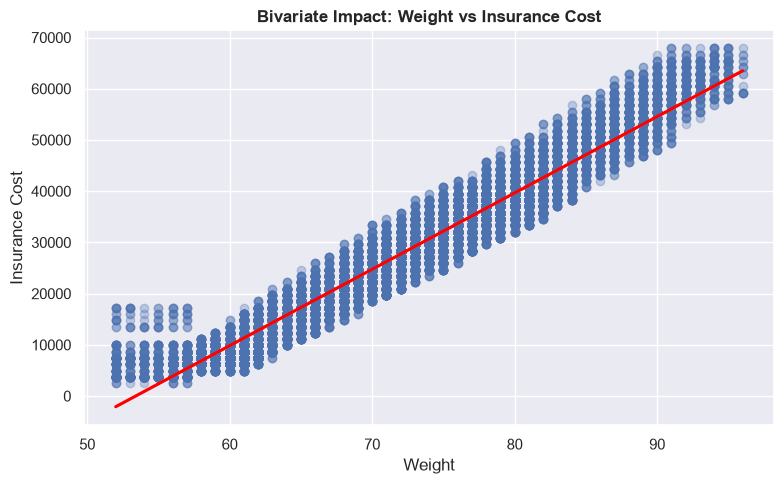

In [57]:
plt.figure(figsize=(8, 5))
sns.regplot(x='weight', y='insurance_cost', data=df2,
            scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Bivariate Impact: Weight vs Insurance Cost', fontsize=12, fontweight='bold')
plt.xlabel('Weight')
plt.ylabel('Insurance Cost')
plt.tight_layout()
plt.show()

**Observations:**

- The presence of a strong positive linear correlation is evident between weight and insurance cost, where cost increases linearly with increasing weight from 52 to 96.

- The majority of the data points lie within the range of 60 to 85, where insurance cost increases linearly with increasing weight, reflecting a stable cost structure.

- However, at lower weight levels, individuals show lower costs, ranging from 1000 to 5000, reflecting a departure from the general trend for individuals weighing between 50 and 60.

**Insights:**

- Weight displays a strong positive relationship with insurance cost, suggesting it may be a dominant factor in pricing within this dataset.

- The presence of lower insurance costs for individuals at similar weight levels suggests that individuals without a medical history or healthy lifestyle habits can reduce risk, thus supporting the objective that individual health behaviors influence insurance cost.



---

***BMI vs Insurance Cost***

- It examines whether the composition of the human body, i.e., the relative weight to height ratio, influences insurance premiums.


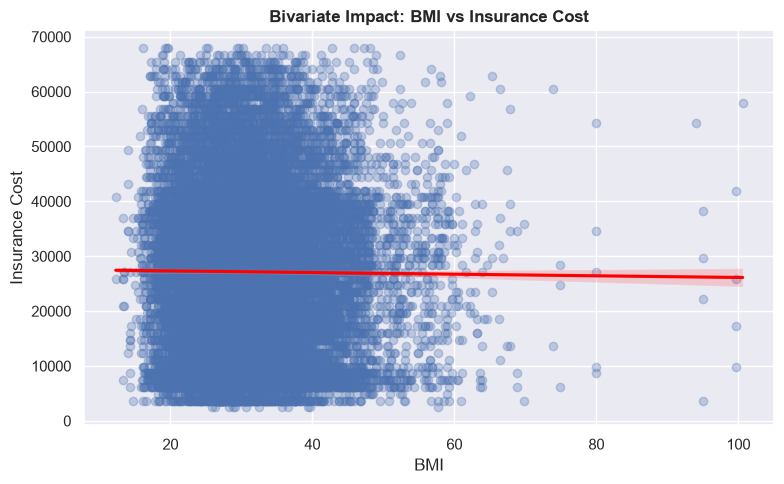

In [58]:
plt.figure(figsize=(8, 5))
sns.regplot(x='bmi', y='insurance_cost', data=df2,
            scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Bivariate Impact: BMI vs Insurance Cost', fontsize=12, fontweight='bold')
plt.xlabel('BMI')
plt.ylabel('Insurance Cost')
plt.tight_layout()
plt.show()

**Observations:**

- The values of the BMI are spread out across the range of 12 to 100, with most values between 20 and 45.

- The insurance costs are spread out across all the values of the BMI (2000 to 65000), with no particular trend upwards or downwards. The line also remains flat, showing no particular level of correlation between the insurance cost and the BMI.

**Insights:**

- Despite BMI being a standard health indicator, it does not seems too influence the insurance cost in this dataset.  

- This indicates that the insurer do not rely on the BMI alone to asses health risks, but may rely on more direct or observable factors, such as the weight or history, which may limit the effectiveness of the BMI as a predictor.

----

***Fat Percentage vs Insurance Cost***

- It analyzes whether a high percentage of fat composition in the human body, which is a more accurate measure of health, influences insurance premiums.

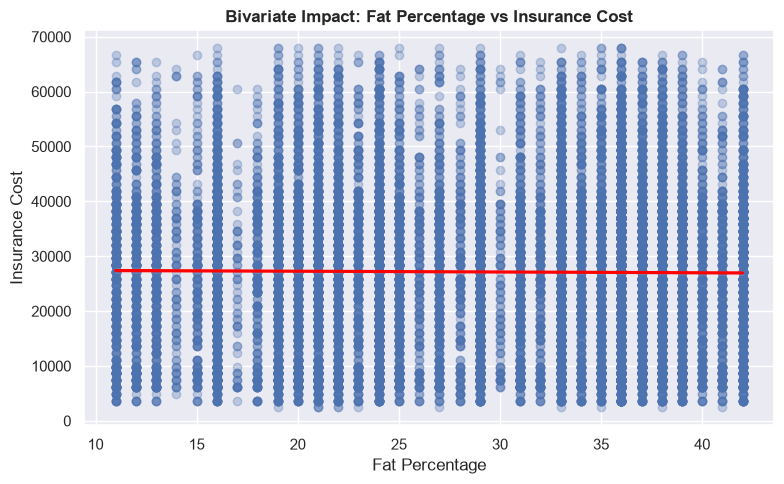

In [59]:
plt.figure(figsize=(8, 5))
sns.regplot(x='fat_percentage', y='insurance_cost', data=df2,
            scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Bivariate Impact: Fat Percentage vs Insurance Cost', fontsize=12, fontweight='bold')
plt.xlabel('Fat Percentage')
plt.ylabel('Insurance Cost')
plt.tight_layout()
plt.show()

**Observations:**

- The percentage of fat varies between 11 and 42. The distribution of the data points is almost uniform.

- The insurance costs vary widely, ranging from 3000 to 67000. All the data points are included, but no specific pattern can be identified.

- The line of regression is almost horizontal, meaning no specific relationship can be established.

**Insights:**

- Fat percentage, although a more specific measure of health, does not show any direct correlation with insurance costs.

- This suggests that insurance companies are not using specific data points like fat percentage to determine insurance costs. This may not be a very specific measure of the actual condition and may not be used to optimize the insurance costs based on the condition.

---

***Avg Glucose Level vs Insurance Cost***

- It investigates the effect of average glucose levels on insurance premiums, which may be a measure of diabetes.

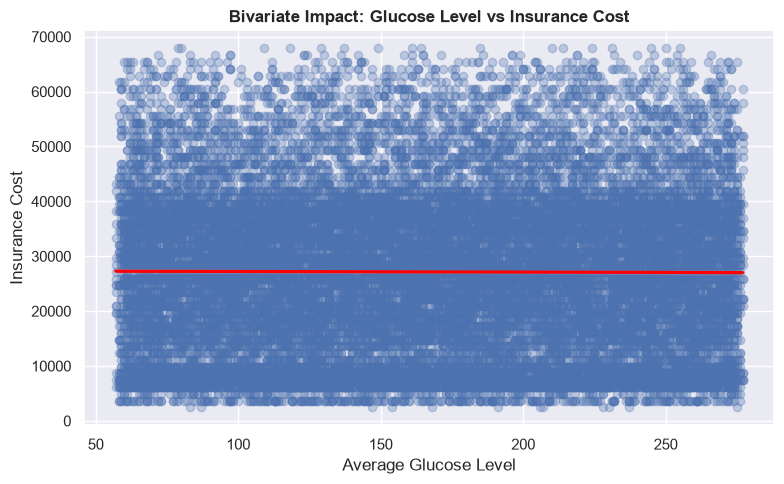

In [60]:
plt.figure(figsize=(8, 5))
sns.regplot(x='avg_glucose_level', y='insurance_cost', data=df2,
            scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Bivariate Impact: Glucose Level vs Insurance Cost', fontsize=12, fontweight='bold')
plt.xlabel('Average Glucose Level')
plt.ylabel('Insurance Cost')
plt.tight_layout()
plt.show()

**Observations:**

- The average glucose level varies between 57 and 277, with densely populated data points for the entire range.

- Insurance costs are highly variable (2000 to 67000) for all glucose level data points, with no concentration or pattern.

- The regression line remains flat, indicating no linear relationship between the glucose level and insurance cost.

**Insights:**

- The average glucose level by itself has little effect on insurance rates, indicating that metabolic health indicators may not be directly taken into account by insurers for insurance pricing.
- This reveals a disconnect between clinical health risk factors and pricing strategy, suggesting that in order to better align with the objective of optimising insurance cost based on health conditions, these variables may need to be combined with other features.


---

***Avg Daily Steps vs Insurance Cost***

- It examines whether increased physical activity levels have a direct correlation with reduced insurance premiums.

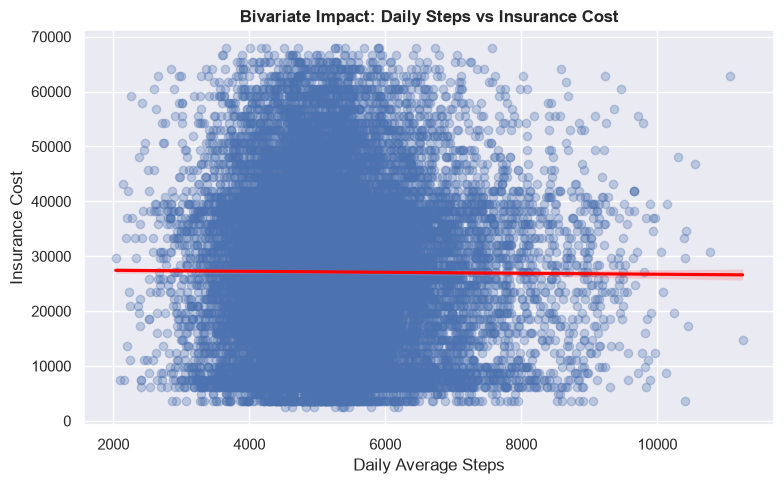

In [61]:
plt.figure(figsize=(8, 5))
sns.regplot(x='daily_avg_steps', y='insurance_cost', data=df2,
            scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Bivariate Impact: Daily Steps vs Insurance Cost', fontsize=12, fontweight='bold')
plt.xlabel('Daily Average Steps')
plt.ylabel('Insurance Cost')
plt.tight_layout()
plt.show()

**Observations:**

- Daily average steps are also evenly distributed, ranging between 2000 and over 11000, with the majority of the data points concentrated between 4000 and 8000.
- Insurance costs are evenly spread over the entire range of data, between 2000 and 68000, for all step levels, with no specific clustering of data points in any particular step level.
- The red regression line is flat and horizontal, indicating that there is no specific linear relationship between the data points.

**Insights:**
- In this raw dataset, walking more steps or daily physical activities does not automatically result in lower insurance costs.
- Insurance companies probably combine exercise habits with other health metrics (such as weight or smoking) rather than looking at daily physical activities alone, as evidenced by the fact that standalone step counts do not determine pricing.


---

***Age vs Insurance Cost***

- It determine whether older age groups s have a direct correlation with increased insurance premiums.

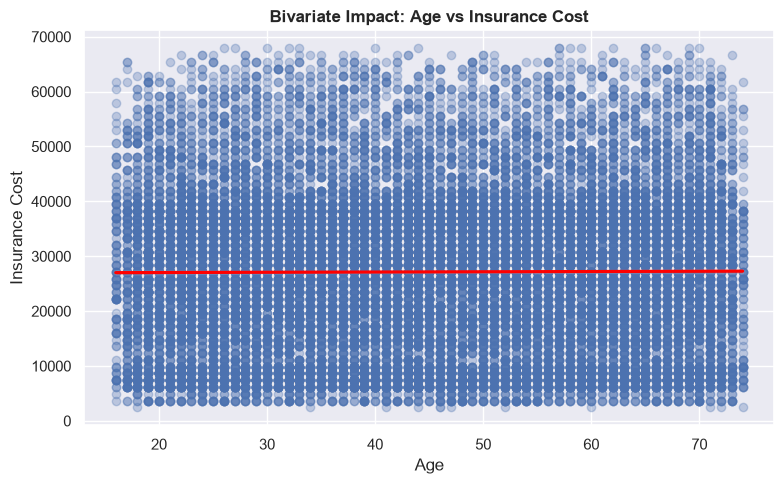

In [62]:
plt.figure(figsize=(8, 5))
sns.regplot(x='age', y='insurance_cost', data=df2,
            scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Bivariate Impact: Age vs Insurance Cost', fontsize=12, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Insurance Cost')
plt.tight_layout()
plt.show()

**Observations::**

- The red linear regression line, which is centred at an insurance cost of 27,000, stays perfectly flat over the whole X-axis.
- The data points span the whole age range, from seniors (age 74) to teenagers (age $16$).
- Insurance costs range from less than 5,000 to almost 70,000 for every age group. There isn't an upward diagonal slope.


**Insights:**

- In this dataset, age by itself has no linear predictive power over insurance costs. The maximum premium of 70,000 may be applied to both a 20-year-old and a 70-year-old.

- It demonstrates that other metrics (such as smoking or BMI) totally supersede age as a cost driver because costs are evenly distributed across all age groups.



###**Target vs Categorical Features**

We will use Boxpolts for analysis as  it efficiently compare the distribution, central tendency (median), spread, and outliers of numerical data across different categories side-by-side.

---

***Smoking Status vs Insurance Cost***

- It compares insurance cost based on different smoking statuses to assess the cost implications of this risky lifestyle habit.  

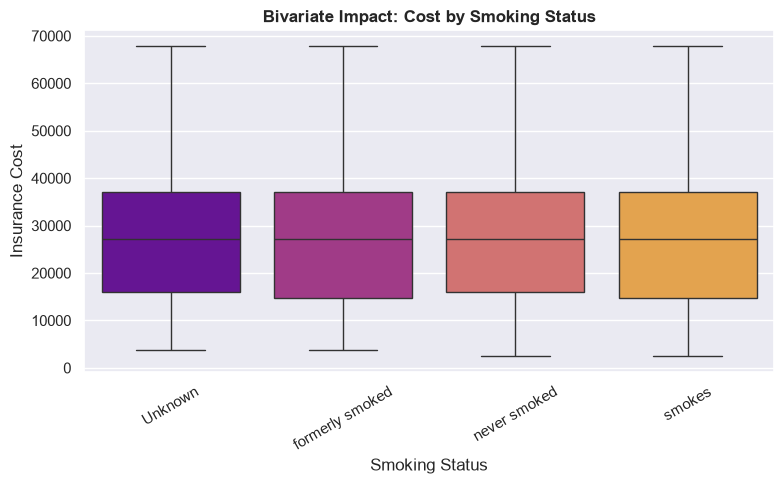

In [63]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='smoking_status', y='insurance_cost', data=df2, palette= "plasma")
plt.title('Bivariate Impact: Cost by Smoking Status', fontsize=12, fontweight='bold')
plt.xlabel('Smoking Status')
plt.ylabel('Insurance Cost')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Observations:**

- Insurance costs for all smoking categories (smokers, never smokers, former smokers, and unknown smokers) range roughly from 3000 to 68000.

- There is no discernible upward or downward shift across groups, with the median cost for all categories falling between 26000 and 28000.

- The middle 50% of the data, or the interquartile range, is roughly between 15000 and 36000 for all categories.

- Regardless of smoking status, the spread and whiskers are almost the same, suggesting similar cost variability.


**Insights:**

- In contrast to a belief that smokers would pay higher premiums, smoking status does not exhibit a significant independent impact on insurance costs in this dataset.

- This implies that smoking behaviour might not be enough to differentiate pricing on its own and might need to interact with other health factors to show its impact.


---

***Exercise vs Insurance Cost***

- This plot evaluates how different levels of exercises influence insurance cost and individual health risks.  


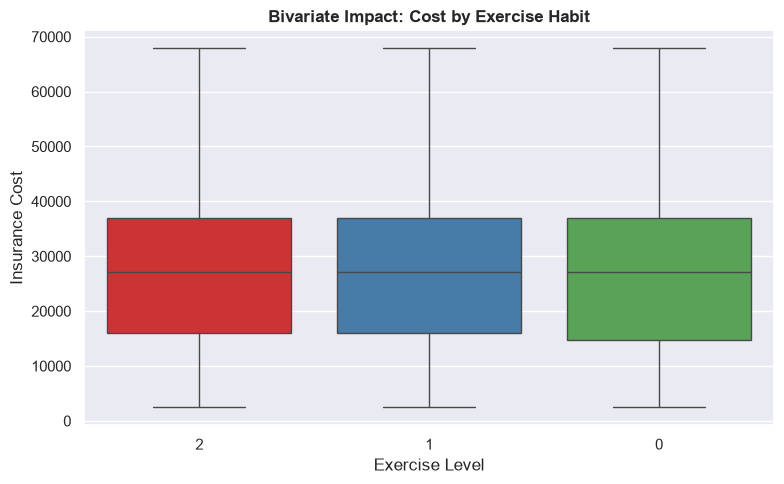

In [64]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='exercise', y='insurance_cost', data=df2, palette= "Set1")
plt.title('Bivariate Impact: Cost by Exercise Habit', fontsize=12, fontweight='bold')
plt.xlabel('Exercise Level')
plt.ylabel('Insurance Cost')
plt.tight_layout()
plt.show()

**Observations:**

- The cost of insurance varies greatly between roughly 3000 and 68000 for all exercise levels (0, 1, 2).

- The median cost, which is between 26,000 and 28,000, is the same for all groups.

- For all exercise levels, the interquartile range is roughly between 15000 and 36000.

- When exercise level rises or falls, there is no discernible change in distribution.

**Insights:**

- Despite expectations that increased activity levels would lower health risk, there is no clear correlation between exercise habits and insurance costs.
- This suggests that exercise might not be a significant pricing factor on its own and that its impact might only become apparent when paired with other lifestyle or medical factors.


---

***Heart Disease History vs Insurance Cost***

- This plot analyzes whether individuals suffering from heart disease are charged more for insurance due to increased medical risks.

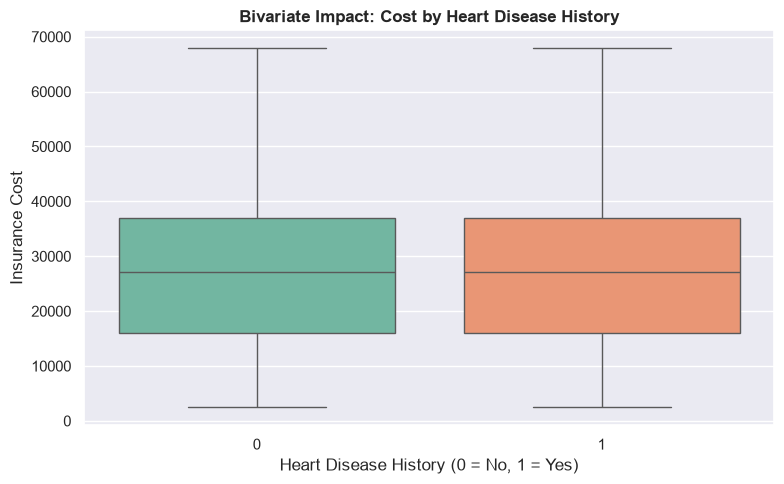

In [65]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='heart_decs_history', y='insurance_cost', data=df2, palette= "Set2")
plt.title('Bivariate Impact: Cost by Heart Disease History', fontsize=12, fontweight='bold')
plt.xlabel('Heart Disease History (0 = No, 1 = Yes)')
plt.ylabel('Insurance Cost')
plt.tight_layout()
plt.show()

**Observations:**

- Both groups insurance premiums (0: No history, 1: History) fall between roughly 3000 and 68,000.

- Both groups median insurance costs are almost the same, ranging from 26,000 to 28,000.

- For both categories, the interquartile range is likewise comparable, falling roughly between 15000 and 36000.

- For those with a history of heart disease, there is no discernible increase in expenses.

**Insights:**

- Given its clinical significance, heart disease history does not appear to have a significant impact on insurance costs on its own.

- This implies that the impact of medical history may depend on how it interacts with other risk factors rather than being directly reflected in pricing.

---


***Location vs Insurance Cost***

- this is to analyse if location have any significant effect on insurance pricing based on different regions.

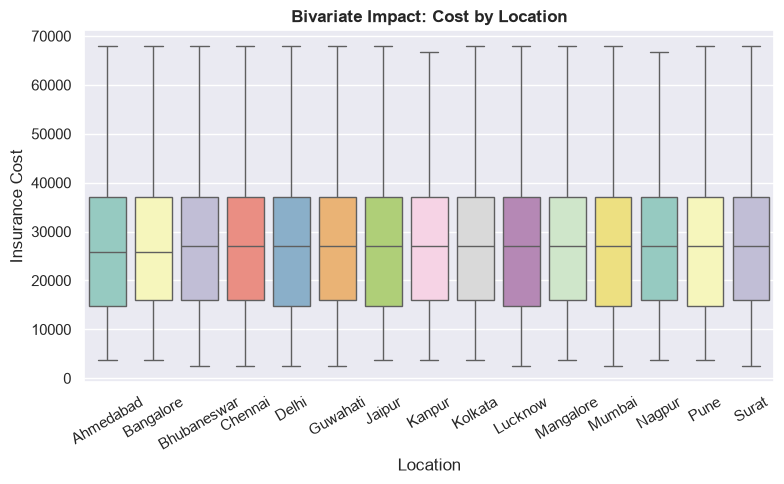

In [66]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Location', y='insurance_cost', data=df2, palette= "Set3")
plt.title('Bivariate Impact: Cost by Location', fontsize=12, fontweight='bold')
plt.xlabel('Location')
plt.ylabel('Insurance Cost')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Observations:**

- All 15 cities have roughly comparable median insurance costs, ranging from 25,000 to 27,000.
- The IQR boxes are essentially the same size throughout all cities—roughly 15,000 to 36,000.
- The whiskers extend to similar ranges for every city—from near zero to around 68,000.
- No particular city jumps out with a significantly higher or lower cost distribution.
- Even visually unique cities like Chennai and Lucknow exhibit no significant distinction from the others.


**Insights:**

- In this dataset, there is no notable relationship between location and insurance costs.
- This column provides no predictive value to the model because there is no regional pricing signal.
- We can safely drop this column in data preprocessing sections.




###**Feature vs Feature (Clinical Inter-Relationships)**

- **We used a scatter plot here to visualize the feature vs feature distribution and variability of clinical outcomes across different categories, in order to analyse clusters and outliers that summary statistics might have hidden.**


---

***Fat Percentage vs Avg Daily Steps***

- This plot asses how different levels of physical activity influence fat percentages, reflecting lifestyle implications for individual's health.

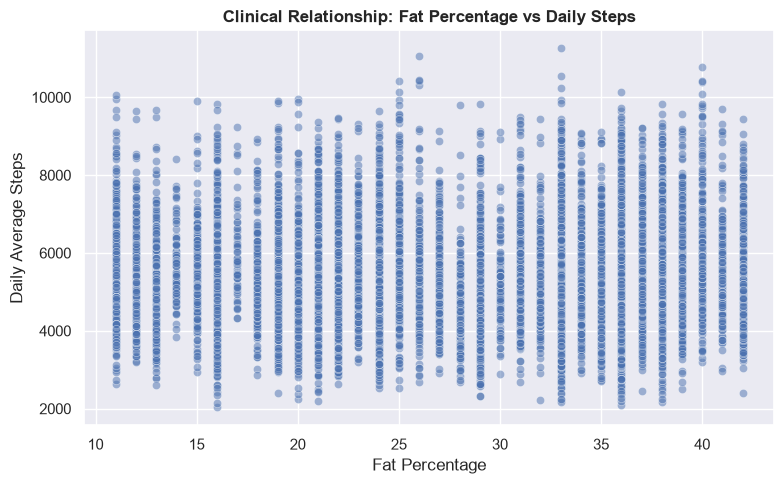

In [67]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='fat_percentage', y='daily_avg_steps', data=df2, alpha=0.5)
plt.title('Clinical Relationship: Fat Percentage vs Daily Steps', fontsize=12, fontweight='bold')
plt.xlabel('Fat Percentage')
plt.ylabel('Daily Average Steps')
plt.tight_layout()
plt.show()

**Observations:**

- Fat percentage ranges from around 11 to 42, while average daily steps vary between 2000 and 11000.

- Plot indicates data points are widely scattered with no visible upward or downward trend.

- For every fat percentage level, average daily steps show high variability, indicating no consistent pattern.

- No clustering or linear relationship is observed between the two variables.

**Insights:**

- This implies that there is no clear relationship with daily physical activity levels and fat percentage, which contrasts with the expectation that higher fat percentage might be associated with lower physical activity.

- This suggests that physical activity and body composition may not be directly correlated in this dataset and should be analyzed alongside additional features for better insights.


---

***Fat Percentage vs Avg Glucose Level***

- It analyzes the implications of body fat percentages on glucose levels to assess potential individual related health risks.  


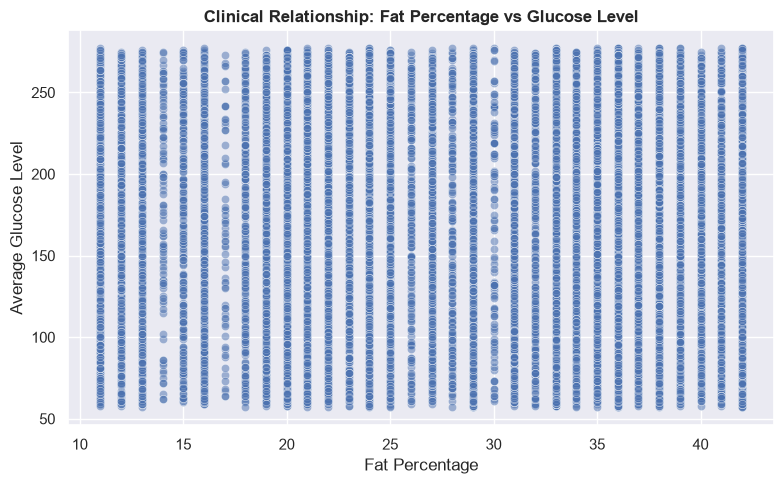

In [68]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='fat_percentage', y='avg_glucose_level', data=df2, alpha=0.5)
plt.title('Clinical Relationship: Fat Percentage vs Glucose Level', fontsize=12, fontweight='bold')
plt.xlabel('Fat Percentage')
plt.ylabel('Average Glucose Level')
plt.tight_layout()
plt.show()

**Observations:**

- Fat percentage ranges approximately from 11 to 42, while average glucose levels span from around 60 to 270.
- The scatter plot shows data points widely dispersed across all fat percentage values with no clear linear trend.
- For each fat percentage level, glucose values exhibit high variability, covering almost the entire range.
- No distinct clustering pattern is visible, indicating heterogeneity in the data.

**Insights:**

- This means that there isn't a strong or direct link between average glucose levels and fat percentage.
- The high variability indicates that glucose levels are affected by various factors in addition to fat percentage.
- Fat percentage alone is not a dependable indicator of glucose level and must be utilized alongside additional clinical and lifestyle factors.
- This shows that we need to use multivariate analysis to better understand the relationships in the dataset.



---

***BMI vs Gender***

- To analyzes the implications of gender on bmi to assess how individual's bmi vary based on gender.  


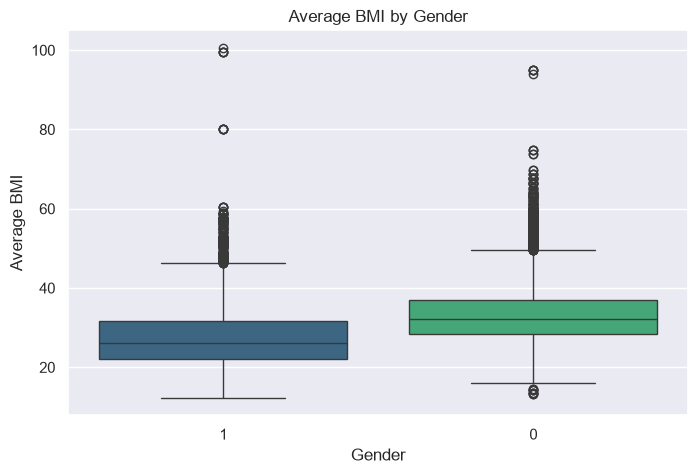

In [69]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df2,y='bmi',x='Gender', palette= "viridis")
plt.xlabel('Gender')
plt.ylabel('Average BMI')
plt.title('Average BMI by Gender');

**Observations:**

- Medians (Female 1 vs. Male 0): The female median BMI is approximately 26. At 32, the median BMI for men is marginally higher.

- The middle 50% of the data for females falls between a BMI of 22 and 32. The IQR is marginally wider for men, falling between a BMI of 28 and 37.

- Extreme outliers beyond the whiskers are seen in both sexes. The highest outliers have BMIs of 95 for men and 100 for women.

**Insights:**

- In this dataset, men's baseline BMI is generally higher than women's.

- Gender by itself is not a reliable indicator of BMI because the boxes overlap considerably (between a BMI of 28 and 32).
- Since BMI has 990 missing values and extreme skewness of up to 100, a simple mean imputation would not help, as these outliers will create an artificial pull on the mean. Therefore, to fill the 990 missing values, we should use the Median (which is resilient to outliers), grouped by Gender.

###**Categorical vs Categorical Features**

Here, I will use a stacked bar plot to show how different categories break down into sub-category, making it easy to see both the total counts and the relative mix of outcomes within each group.


---


***Occupation vs Exercise***

- It evaluates whether occupation influences levels of exercises, reflecting individual lifestyle constraints and implications.  

exercise       2      1     0    All
Occupation                          
Business    2260   5779  1981  10020
Salried      942   2971   898   4811
Student     2046   5888  2235  10169
All         5248  14638  5114  25000
----------------------------------------------------------------------------------------------------


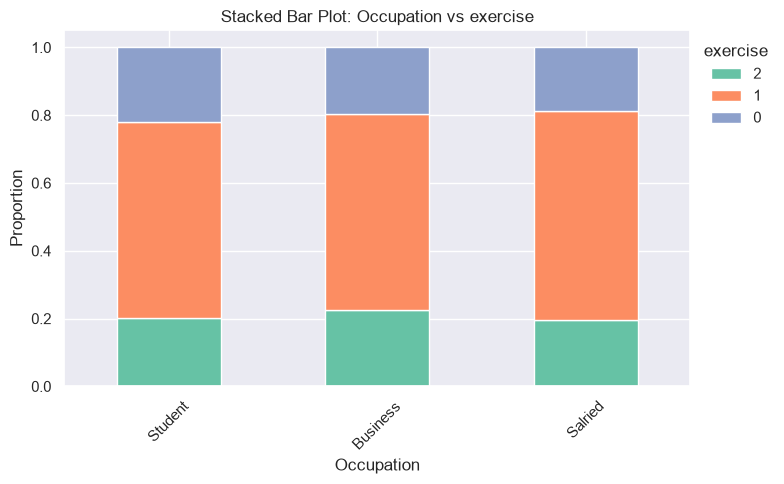

In [70]:
stacked_barplot_custom(data=df2, predictor='Occupation', target='exercise', palette='Set2')

**Observations:**

***Exercise Level 1 (Moderate):***
- Overall, across all occupations, 57% to 62% of individuals participate in moderate exercise.
- This exercise level is the most dominant in all three groups, making it the most frequent exercise level.
- The proportion is the same across the Business, Salaried, and Student groups.

***Exercise Level 2 (Extreme):***
- Overall, across all occupations, this exercise level comprises 19% to 23%.
- The Business group has a slightly higher proportion compared to the Student group and the Salaried group.
- The proportion in the Business group is approximately 22.5%, whereas in the Student group it is approximately 20%, and in the Salaried group it is approximately 19.6%.
- A smaller proportion of individuals participate in extreme exercise compared to moderate exercise.

***Exercise Level 0 (No Exercise):***
- Overall, across all occupations, approximately 18% to 22% of individuals participate in this exercise level.
- The Student group has a slightly higher proportion compared to the Business group and the Salaried group.
- The proportion in the Student group is approximately 22%, in the Business group it is approximately 19.8%, and in the Salaried group it is approximately 18.7%.
- The proportion in this exercise level is relatively stable across groups, only slightly varying.

**Insights:**

- Exercise patterns do not show significant variation across different occupations, as the proportionate distribution is very similar across groups.
- The majority of individuals in all groups participate in moderate exercise, which is a similar trend across the board.
- It seems that occupation is not a significant factor in determining the exercise pattern, which could indicate that other factors have a larger impact.


---

***Gender vs. Smoking Status***

- It analyzes different levels of smoking risks based on gender to assess individual's health risk.

smoking_status  Unknown  formerly smoked  never smoked  smokes    All
Gender                                                               
1                  4403              719          2581     875   8578
0                  3152             3610          6668    2992  16422
All                7555             4329          9249    3867  25000
----------------------------------------------------------------------------------------------------


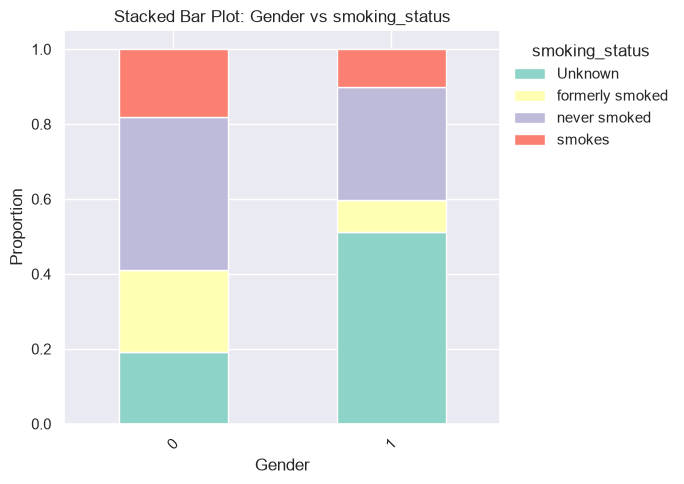

In [71]:
stacked_barplot_custom(data=df2, predictor='Gender', target='smoking_status', palette='Set3')

**Observations:**

* **Females here are represented by 1 and male by 0.**

***Unknown Smoking Status:***
- A significantly higher number of females have "Unknown" smoking status(approximately 51.3%), as opposed to those with males (approximately 19.2%).
- This suggests a large number of missing or unknown smoking status for the people with females.

***Formerly Smoked:***
- Approximately 22.0% of the people in the male group are classified as "Formerly Smoked", as opposed to approximately 8.4% in the female group.
- This category also shows a large disparity in the two groups.

***Never Smoked:***
- The majority of the people in both the groups fall in this category.
- However, the proportion of people in the males group (approximately 40.6%) is much higher than that in the females group (approximately 30.1%).

***Currently Smokes:***
- Approximately 18.2% of the people in the males group are classified as "Currently Smokes", as opposed to approximately 10.2% in the females group.
- This suggests that the prevalence of smoking in the males group is much higher than in the females group.

**Insights:**
- Smoking status shows a large disparity in the two gender groups, differentiating it from the observations made in the analysis of the other features.
- The proportion of people in the male group who are currently smoking or formerly smoked is much higher than that in the females group.
- There are a large number of unknown values in the case of the people in the females group, which may be a problem in the analysis.
- This attribute may also provide valuable insights if combined with the health-related attributes in the multivariate analysis.



---

##**Multivariate Analysis**

**We will perform mutivariate analysis to understanding how multiple factors together influence insurance cost.**

**Multivariate Analysis - Approach and Rationale**

Even though bivariate analysis is useful for understanding relationships between pairs of variables. However, in practice, insurance cost is determined based on the combined influence of all relevant variables. Hence, multivariate analysis is performed to examine interaction effects and uncover more profound relationships among variables.

***1. Correlation Heatmap (Global Relationship Analysis):***

The correlation heatmap is used to analyze the correlation among all numerical variables at once.

It is helpful for:
- Identifying important drivers for the target variable (insurance_cost)
- Detecting multicollinearity among features
- Eliminating less important features for further analysis

The correlation heatmap is a broad overview, and based on this, features can be identified that have strong statistical significance in the data.

***2. Interaction Effect Plots (Multi-variable Relationships):***

To understand how the relationship between the predictor and the target variable changes when the third variable is introduced, Interaction Effect Plots are used.

These plots are used for:
- Understanding the overall effect of lifestyle and clinical factors together
- Determining if certain groups, such as smokers and non-smokers, behave differently under the same conditions
- Uncovering patterns that are not visible through bivariate analysis

**With the inclusion of the third variable through color encoding (adding hue), these plots are simulating real-life conditions where all the factors are considered together, such as the effect of all the risk factors on insurance costs.**

**Overall, the depth of analysis is increased with the inclusion of multivariate analysis, where the focus is on the interactions between the variables.**

###**Correlation Analysis**

- Heatmap Analysis on All Numerical Columns for correlation analysis.

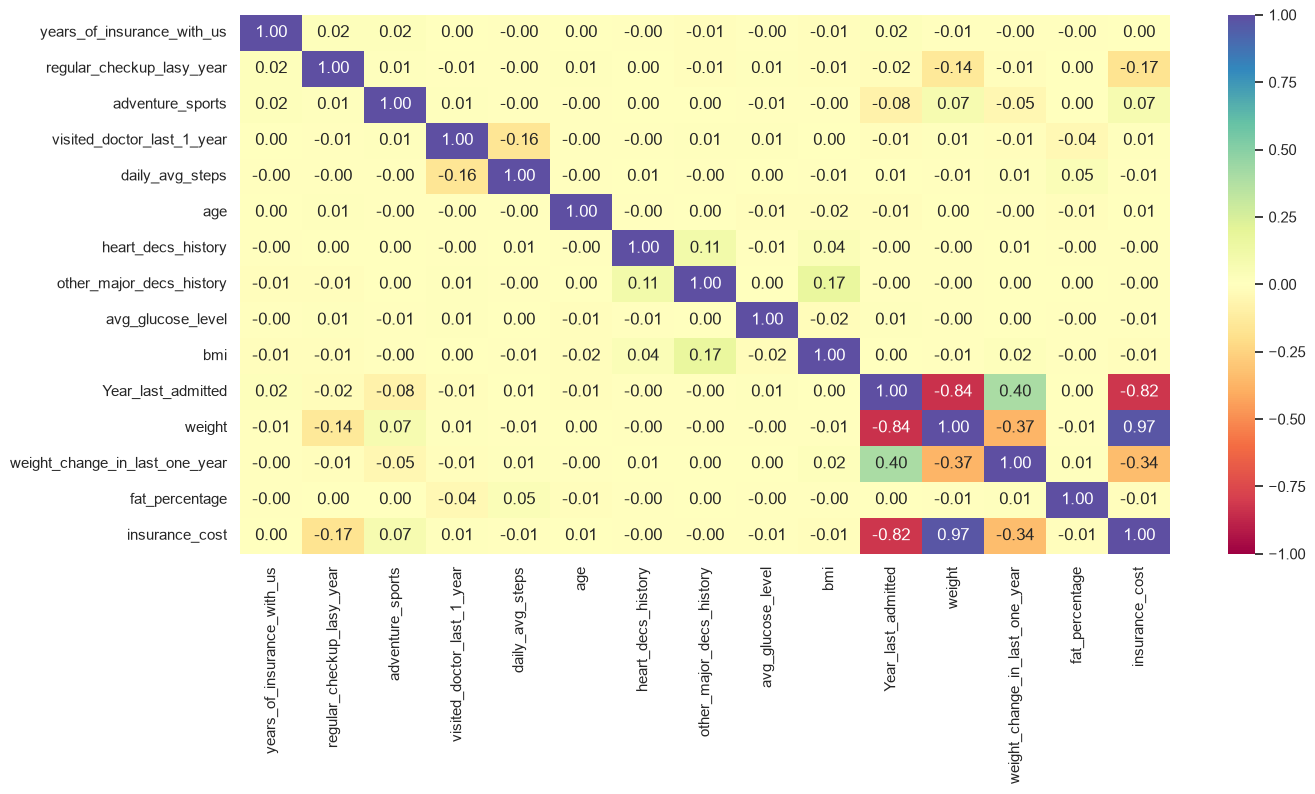

In [72]:
# To create the heatmap, We'll create a list of only the numerical variables
corr = df2.select_dtypes(include=np.number).columns.tolist()

# Now let's plot the heatmap
plt.figure(figsize=(15, 7))
sns.heatmap(
    df2[corr].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

**Observations: Multi-Collinearity Heatmap**
- ***Range:*** The Pearson correlation coefficient ranges from -1.00 to 1.00, covering the entire range.
- ***Top Positive Correlations:*** The 'weight' attribute shows a very high correlation of 0.97 with 'insurance_cost'.
- ***Top Negative Correlations:*** The 'Year_last_admitted' attribute shows a high negative correlation with 'insurance_cost' (-0.82) and 'weight' (-0.84).
-***Secondary Inter-correlations:*** 'weight_change_in_last_one_year' shows a negative correlation with 'weight' (-0.37) and a positive correlation with 'Year_last_admitted' (0.40).
- ***Feature-to-Feature Separation:*** The feature 'heart_decs_history' and 'other_major_decs_history' have a slight positive correlation of 0.11, but all other medical history features do not correlate with each other.
-***Near-Zero Interaction Matrix:*** All attributes, except 'weight', 'weight_change_in_last_one_year', and 'Year_last_admitted', show a near zero correlation with 'insurance_cost', i.e., 'age' (0.01), 'bmi' (-0.01), 'avg_glucose_level' (-0.01), and 'fat_percentage' (-0.01).


**Insights:Feature Interactions and Multi-Collinearity**

- **Primary Linear Weighting:** The near-linear relationship (0.97) between physical mass and financial output suggests that weight is the sole heavy-tailed pricing vector for this portfolio.

- ***Risk of Input Redundancy (Multicollinearity):*** The pairwise correlation of -0.84 between weight and Year_last_admitted indicates a critical multicollinearity threshold.

- ***Note: Standard Underwriting is the behind-the-scenes work done by insurance companies to assess an individual's health, lifestyle, and financial risks. The insurance company is making two decisions:***

   - Should we even offer client an insurance policy?

   - How much should client pay each month for the insurance (the premium)?

   - In insurance science, underwriters are required to follow specific rules. If customers are older, have heart disease, or visit the doctor often, underwriting rules require cost to be more expensive.

- ***Deviations from Standard Underwriting Theory:*** Standard underwriting tables suggest that recent clinical interventions and/or older age should be risk-increasing. However, the negative coefficient of Year_last_admitted (-0.82) and near-zero weighting of age (0.01) suggest a very high degree of architectural deviation from standard medical underwriting theory.



###**Interaction Effects**

***Weight vs. Insurance Cost by Smoking Status***

- This plot is used to assess whether people with similar weight are charged differently based on smoking status.

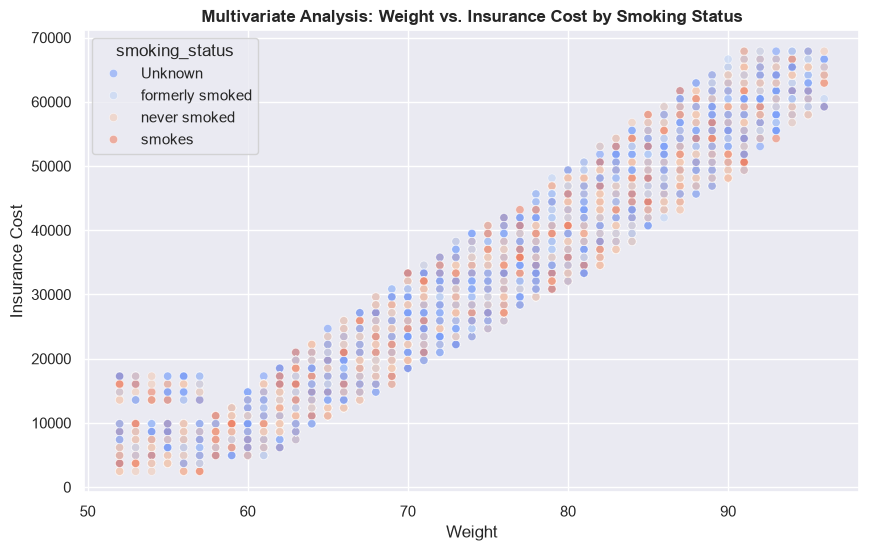

In [73]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='weight', y='insurance_cost', hue='smoking_status', data=df2, palette='coolwarm', alpha=0.6)
plt.title('Multivariate Analysis: Weight vs. Insurance Cost by Smoking Status', fontsize=12, fontweight='bold')
plt.xlabel('Weight')
plt.ylabel('Insurance Cost')
plt.show()

**Observations:**

- The variable weight varies between 52 and 95, whereas the insurance cost varies between 2,000 and 68,000.
- A strong positive linear relationship is observed between the weight variable and the insurance cost variable for all the smoking categories.
- The observations for the 'Unknown,' 'Formerly smoked,' 'Never smoked,' and 'Smokes' categories lie close to the same linear trend line, without any significant vertical separation between the groups.
- For similar weight groups, say in the range 70 to 80, the insurance costs for all the smoking groups lie in the same range, say between 25,000 and 50,000.
- A small amount of scatter is observed for each weight group, but this is not necessarily related to any specific smoking group.

**Insights:**

- Weight is the most significant factor in determining the insurance cost, even after considering the impact of the smoking status variable.
- Smoking status is not seen as a significant factor in the insurance pricing, as all the groups show the same trend in the insurance cost variable.
- The fact that the groups are not significantly separated implies that smoking status is not effectively integrated into the insurance pricing in this dataset.
- Therefore, the interaction between the weight variable and the smoking status variable in this dataset does not impact the insurance cost outcome, which is similar to the earlier observed fact that the weight variable is the most significant factor in determining the insurance cost.



---

***BMI vs Insurance Cost vs Exercise***

- This plot is used to assess whether people with similar BMI are charged differently based on their level of exercise.

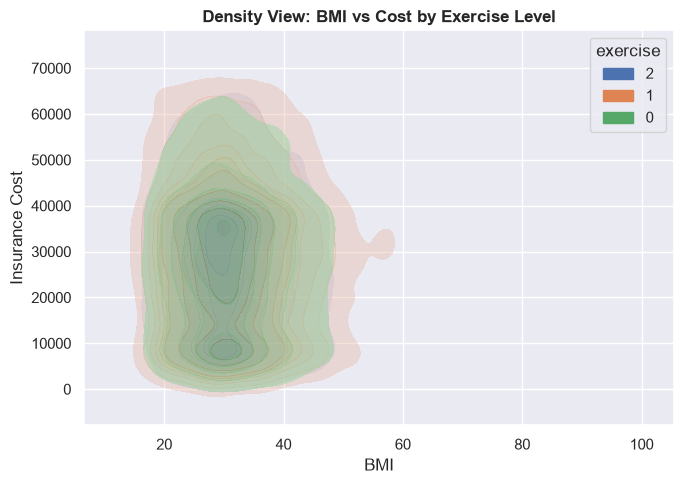

In [74]:
plt.figure(figsize=(7, 5))

sns.kdeplot(
    data=df2,
    x='bmi',
    y='insurance_cost',
    hue='exercise',
    fill=True,
    alpha=0.4
)

plt.title('Density View: BMI vs Cost by Exercise Level', fontsize=12, fontweight='bold')
plt.xlabel('BMI')
plt.ylabel('Insurance Cost')
plt.tight_layout()
plt.show()

**Observations:**

- ***Central Overlap (BMI 25 to 35, Cost 5,000 to 40,000):*** Exercise levels display a substantial central overlap that cuts across every group.

- ***Lack of Isolation***: Exercise levels simply don't stand apart; they converge in that region with both medium cost and medium weight.

- ***Core Presence of Level 2 (Blue):*** Level 2 has the smallest exercise footprint but sits alongside all other exercise activities. It holds its core spot between BMI 25 to 35 and Costs of 5,000 to 40,000.

- ***Level 1 (Orange) Outer Expansion (BMI ~20 to 60, Cost upto 70,000):*** Level 1 moves out from the center, stretching into higher BMI territory and rising cost, showing that even moderate exercise levels can pair with higher costs at higher BMI.

- ***Level 0 (Green) Wide Distribution:*** Level 0 represents the most inactive group, making a big impact in the higher BMI (up to 50) and higher cost areas (up to 65,000). Its influence doesn't reach much into the lower-cost region.

***Insights:***

- ***High Activity Risk Containment:*** Exercise Level 2 leaves the smallest mark on the graph. People who work out often stay in the standard cost range (under 40,000).

- ***Combined Weight and Activity Limitations:*** Patterns from BMI and exercise frequency reveal BMI as the main driver for costs. People with BMI over 45 don't manage to cut their insurance expenses by ramping up exercise.

- ***Inadequate Cost Separation:*** Exercise levels don't do enough to separate cost ranges. Their central overlap blocks clear cost distinction unless we consider other features.


---

***Average Glucose Level vs Insurance Cost vs Heart Disease***

- This plot is used to assess whether people with similar levels of glucose are charged differently based on whether they have heart diseases.


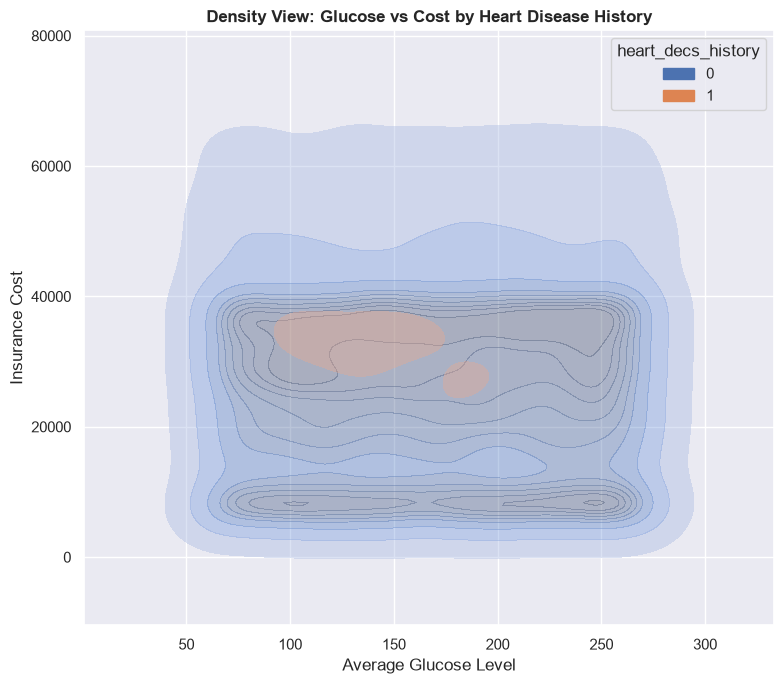

In [75]:
plt.figure(figsize=(8, 7))

sns.kdeplot(
    data=df2,
    x='avg_glucose_level',
    y='insurance_cost',
    hue='heart_decs_history',
    fill=True,
    alpha=0.4
)

plt.title('Density View: Glucose vs Cost by Heart Disease History', fontsize=12, fontweight='bold')
plt.xlabel('Average Glucose Level')
plt.ylabel('Insurance Cost')
plt.tight_layout()
plt.show()

**Observations:**

- ***Dominance of Non-Heart Disease History (Blue)***: Most of the graph is taken up by people without a heart disease history (Level 0). Their density contour stretches evenly from glucose levels of 50 up to 250, and insurance costs running from 5,000 all the way to over 65,000.

- ***Bimodal Cost Peaks for Level 0:*** Within this blue group, you see two clear bands where people cluster—one down near costs of 10,000, and another centered around 35,000.

- ***Compact Heart Disease Islands (Orange):*** People who have a heart disease history (Level 1) don't spread out much. Instead, they show up as tight, isolated groups in the middle of the graph—glucose between 100 and 200, and costs ranging from 25,000 to 40,000.


**Insights**

- ***Cost Normalization for Heart Disease:*** The orange group's tight range between 25,000 and 40,000, suggesting individuals with heart disease appear to be concentrated within a mid-to-high cost range.

- ***Glucose as a Silent Driver:*** For the blue group, insurance cost covers the full range across all glucose levels. So, glucose by itself doesn't act as a strong or simple divider for insurance pricing in this data.






##**Overall Insights From EDA**

**Primary Cost Drivers and Clinical Metrics**

- ***Weight is the primary cost driver:*** Weight has a very strong positive correlation with insurance costs (about 0.97 correlation), indicating that it is the key factor determining pricing in this dataset.
- ***Limited Impact of Independent Clinical Metrics:*** Key health metrics such as BMI, body fat percentage, average glucose levels, and age have almost no correlation with insurance costs. These variables do not independently influence insurance pricing.
- ***Lifestyle, medical history, and geographical factors:*** They show weak direct impact. Exercise, smoking status, heart disease history, and geography all show overlapping cost distributions, indicating that no single factor has a substantial effect on insurance costs. Bivariate analysis of Location vs Insurance_cost yielded nearly similar medians and IQR ranges across all 15 cities, demonstrating that geography has no regional price signal in this dataset.

**Data Quality & Structural Issues**

- ***Significant Structural Gaps in Data:*** There are roughly 990 missing rows in BMI and 47.5% in Year of Last Admission, as well as a big "Unknown" category in smoking status (around 30%).

- ***High Feature Independence & Imbalance:*** Most variables exhibit low inter-correlation and high data imbalance (e.g., adventure sports). This diminishes their predictive value without sufficient data pre-processing.

- ***Deviation from Real-World Underwriting:*** Observed connections (for example, a near-zero correlation between age and insurance cost) contradicts traditional insurance norms, showing synthetic or non-realistic data behaviour.


**The Considerations for Preprocessing**

- ***Missing Value Imputation is Required:*** With 990 missing BMI rows and 47.5% missing Year of Last Admission rows, we must use strong imputation methods (such as Grouped Medians) before feeding data into any algorithm.

- ***Outlier Capping is Required:*** Visual abnormalities that exceed a BMI of 60 and insurance costs of over 70,000 need to be further analysed and they might need for Capping (1% and 99%) to prevent distorted data.

- ***Feature Engineering is Critical:*** Because single predictors are ineffective, we should try integrate numerous features to extract a meaningful signal during preprocessing.



### **Observation: Insurance Cost Distribution**

- The insurance cost variable contains 54 unique values across 25,000 observations, with values occurring in fixed increments of 1,234.

- A strong positive correlation was observed between weight and insurance cost (r ≈ 0.97), which is consistent with the high predictive performance of the weight-only baseline.

- These patterns suggest a structured relationship within the dataset. Since the target-generation methodology is not documented, further validation using independent data would be necessary before applying the model to real-world insurance pricing.

# **DATA PREPROCESSING — CORRECTED**

**Methodology:** The original dataset is retained as `df`, and the analysis copy is retained as `df1`. The exploratory analysis above uses observed values and does not modify the training data. Data-quality checks are performed before splitting. Missing-value imputation, categorical encoding, and optional outlier clipping are fitted **only on training folds** through a scikit-learn pipeline.

**Important:** `Year_last_admitted` is missing for many records. Missing is not assumed to mean never admitted. No mean/median year is invented, and no undocumented 2018 reference year is used.

In [76]:
# Additional libraries for reproducible model training (not previously imported)
from pathlib import Path
import json
import joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import cross_val_score

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

## **Duplicate Values and Data Cleaning**

**Methodology:** Work on a copy of `df1`, preserving the source data and the original EDA. Standardize spelling and categorical labels in one location before training.

In [77]:
# df1 was created earlier from df after removing applicant_id.
# df2 is the cleaned modeling copy; df and df1 remain unchanged.
df2 = df1.copy()

# Correct the raw CSV column typo once, then use the correct name everywhere below.
df2.rename(columns={'regular_checkup_lasy_year': 'regular_checkup_last_year'}, inplace=True)

# Correct a known typo in Occupation without modifying other categories.
# Correct the typo in the categorical Occupation column.
df2['Occupation'] = df2['Occupation'].cat.rename_categories(
    {'Salried': 'Salaried'}
)

print('Rows and columns:', df2.shape)
print('Duplicate rows:', df2.duplicated().sum())
print('Column spelling corrected:', 'regular_checkup_last_year' in df2.columns)
print('Occupation categories:', sorted(df2['Occupation'].dropna().unique()))

Rows and columns: (25000, 23)
Duplicate rows: 0
Column spelling corrected: True
Occupation categories: ['Business', 'Salaried', 'Student']


### Observations: Data Quality and Validation

- The dataset contains **25,000 observations and 23 columns** after excluding the applicant identifier.
- No duplicate records were identified.
- The column name `regular_checkup_lasy_year` was standardized to `regular_checkup_last_year`.
- The inconsistent occupation category `Salried` was corrected to `Salaried`, resulting in three categories: Business, Salaried, and Student.
- No invalid values were detected in the checked ranges for age, weight, BMI, body fat percentage, glucose, daily steps, insurance cost, or future admission years.

**Interpretation:** The dataset passed the implemented validation checks. However, passing these checks does not establish that all records are clinically plausible or free from data-quality issues.

## **Anomalous Value Check**

**Methodology:** Separate logically invalid observations from statistically unusual but plausible observations. Do not delete high-cost or high-weight customers solely because they are outliers. Stop training if essential fields contain invalid values.

In [78]:
# These are broad plausibility checks, not medical diagnostic cutoffs.
# A flagged value requires investigation rather than automatic replacement.
quality_checks = {
    'age below 0 or above 120': (~df2['age'].between(0, 120)).sum(),
    'weight <= 0': (df2['weight'] <= 0).sum(),
    'BMI <= 0 (non-missing)': (df2['bmi'].dropna() <= 0).sum(),
    'fat percentage outside 0-100': (~df2['fat_percentage'].between(0, 100)).sum(),
    'glucose <= 0': (df2['avg_glucose_level'] <= 0).sum(),
    'insurance cost <= 0': (df2['insurance_cost'] <= 0).sum(),
    'steps below 0': (df2['daily_avg_steps'] < 0).sum(),
    'admission year after 2026': (df2['Year_last_admitted'].dropna() > 2026).sum(),
}
quality_report = pd.Series(quality_checks, name='Flagged rows')
print(quality_report.to_string())

# Essential invalid target values make regression training misleading.
if (df2['insurance_cost'] <= 0).any() or df2['insurance_cost'].isna().any():
    raise ValueError('Target insurance_cost contains missing or non-positive values.')

age below 0 or above 120        0
weight <= 0                     0
BMI <= 0 (non-missing)          0
fat percentage outside 0-100    0
glucose <= 0                    0
insurance cost <= 0             0
steps below 0                   0
admission year after 2026       0


## **Missing Values Check and Treatment**

**Observations:** Missing values are counted but **not filled on the complete dataset**. The training pipeline will learn median/mode statistics from the training fold only. Admission years remain categorical as recorded-year strings or `Unknown` rather than imputed calendar years.

In [79]:
missing_report = pd.DataFrame({
    'Missing Count': df2.isna().sum(),
    'Missing %': (100 * df2.isna().mean()).round(2)
}).sort_values('Missing Count', ascending=False)
display(missing_report)

# Compare missing admission years with available medical history signals.
# These comparisons are descriptive; they do not establish that missing means never hospitalized.
print('Admission-year missingness vs heart disease history:')
display(pd.crosstab(df2['Year_last_admitted'].isna(), df2['heart_decs_history'], normalize='index').round(3))
print('Admission-year missingness vs other major disease history:')
display(pd.crosstab(df2['Year_last_admitted'].isna(), df2['other_major_decs_history'], normalize='index').round(3))

,Missing Count,Missing %
Year_last_admitted,11881,47.52
bmi,990,3.96
years_of_insurance_with_us,0,0.00
fat_percentage,0,0.00
weight_change_in_last_one_year,0,0.00
exercise,0,0.00
Alcohol,0,0.00
covered_by_any_other_company,0,0.00
weight,0,0.00
Location,0,0.00


Admission-year missingness vs heart disease history:


heart_decs_history,0,1
Year_last_admitted,,
False,0.947,0.053
True,0.943,0.057


Admission-year missingness vs other major disease history:


other_major_decs_history,0,1
Year_last_admitted,,
False,0.903,0.097
True,0.900,0.100


### Observations: Missing Admission-Year Information

- `Year_last_admitted` contains approximately **47.5% missing values**, making it a significant missing-data concern.
- The proportion of individuals with a recorded history of heart disease is similar across admission-year availability groups: 5.3% when the admission year is recorded and 5.7% when it is missing.
- A similar pattern is observed for other major disease history: 9.7% and 10.0%, respectively.
- These comparisons do not indicate a strong association between admission-year missingness and either disease-history variable individually.
- Missing admission years cannot automatically be interpreted as an absence of hospitalization.

**Interpretation:** Rather than assigning an assumed admission year or treating missing values as confirmed non-hospitalization, the modeling workflow preserves the distinction between recorded and unknown admission information.

**Limitation:** Similar disease-history proportions do not establish that the missing-data mechanism is completely random.

## **Outlier Check — IQR Method and Boxplots**

**Methodology:** Inspect outliers on observed data for interpretation. Do not use complete-dataset quartiles to alter training features. Later, compare unclipped and train-fitted IQR-clipped pipelines on the validation set.

,Feature,Lower IQR bound,Upper IQR bound,Outlier count
0,bmi,11.85,49.85,549
1,avg_glucose_level,-50.50,385.50,0
2,daily_avg_steps,2762.50,7510.50,952
3,weight,43.00,99.00,0
4,insurance_cost,-15425.00,68487.00,0


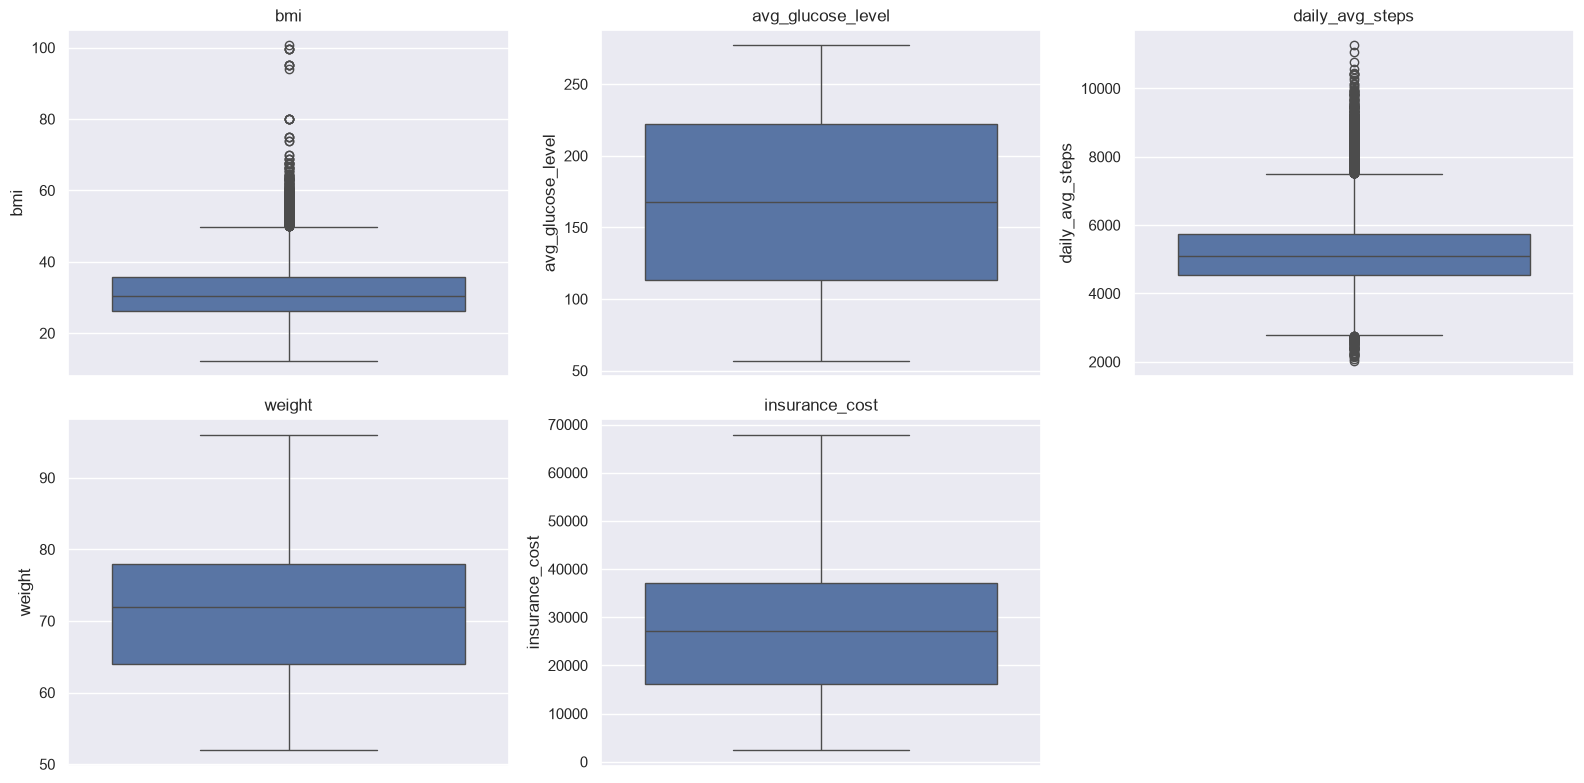

In [80]:
outlier_cols = ['bmi', 'avg_glucose_level', 'daily_avg_steps', 'weight', 'insurance_cost']
outlier_rows = []
for col in outlier_cols:
    values = df2[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({'Feature': col, 'Lower IQR bound': lower,
                         'Upper IQR bound': upper,
                         'Outlier count': int(((values < lower) | (values > upper)).sum())})
display(pd.DataFrame(outlier_rows))
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, outlier_cols):
    sns.boxplot(y=df2[col], ax=ax)
    ax.set_title(col)
for ax in list(axes.flat)[len(outlier_cols):]: ax.axis('off')
plt.tight_layout()
plt.show()

### Observations: Outlier Analysis

The Interquartile Range (IQR) method was applied to selected numerical variables.

- BMI contains 549 observations outside its calculated IQR boundaries.
- Daily average steps contains 952 observations outside its IQR boundaries.
- No IQR outliers were detected for weight, average glucose level, or insurance cost.
- IQR-based outliers are statistical observations and do not necessarily represent incorrect records.

**Modeling decision:** Outlier clipping was evaluated as an experiment rather than automatically applied. The final decision was based on validation performance, with clipping thresholds fitted only on training data.&#x20;


## **Feature Engineering — Admission History and Health Risk Score**

**Methodology:** `admission_year_recorded` equals 1 only when a year is present, and 0 when missing. `admission_year_category` preserves the recorded year as a category and uses `Unknown` for missing. Neither is a verified hospitalization indicator. `health_risk_score` is an exploratory combination of medical-history indicators and admission-year availability, **not a validated clinical risk score**.

**Deployment:** The same transformations must run on training and inference data. They are implemented in the accompanying `insurance_transformers.py` module and included inside the serialized pipeline.

In [81]:
from insurance_transformers import InsuranceFeatureBuilder, IQRClipper

# Preview engineered columns for EDA only; no training statistics are fitted here.
feature_builder = InsuranceFeatureBuilder()
df3 = feature_builder.transform(df2.copy())
print('Engineered columns:')
display(df3[['Year_last_admitted', 'admission_year_recorded',
             'admission_year_category', 'health_risk_score']].head(10))

Engineered columns:


,Year_last_admitted,admission_year_recorded,admission_year_category,health_risk_score
0,NaN,0,Unknown,1
1,NaN,0,Unknown,0
2,NaN,0,Unknown,0
3,NaN,0,Unknown,0
4,2004.0,1,2004,2
5,2003.0,1,2003,1
6,2004.0,1,2004,1
7,NaN,0,Unknown,0
8,2007.0,1,2007,1
9,NaN,0,Unknown,0


### **EDA on Engineered Features**

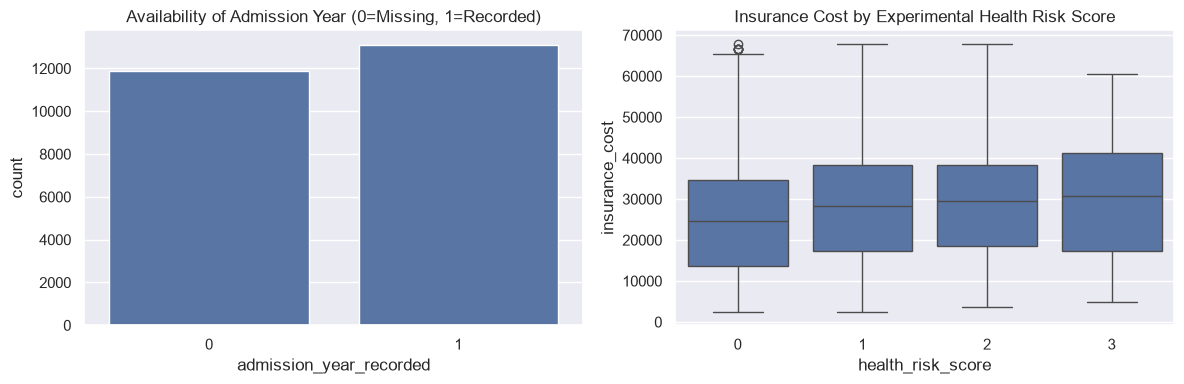

Health risk score counts:
health_risk_score
0    10169
1    12890
2     1774
3      167
Name: count, dtype: int64


In [82]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df3, x='admission_year_recorded', ax=axes[0])
axes[0].set_title('Availability of Admission Year (0=Missing, 1=Recorded)')
sns.boxplot(data=df3, x='health_risk_score', y='insurance_cost', ax=axes[1])
axes[1].set_title('Insurance Cost by Experimental Health Risk Score')
plt.tight_layout();plt.show()
print('Health risk score counts:')
print(df3['health_risk_score'].value_counts().sort_index())

### Observations: Admission-History Feature Engineering

Two admission-history features were introduced:

- `admission_year_recorded`: A binary indicator identifying whether an admission year is available.
- `admission_year_category`: A categorical representation of the recorded admission year, with missing observations assigned the category `Unknown`.

The admission-year availability plot shows approximately 11,881 observations with missing admission years and 13,119 with recorded years.

**Interpretation:** These features retain information about both the recorded admission year and its availability without introducing an undocumented reference year.

The indicator `admission_year_recorded = 0` represents missing information, not confirmed absence of hospitalization.

# **DATA PREPARATION FOR MODELING**

**Methodology:** Reuse `df2` rather than loading the CSV again. Preserve `df` and `df1` for the original inspection and EDA. Split the **raw, validated** features first. The preprocessing pipeline handles missing values, encoding, and clipping without learning from validation or test records.

In [83]:
# df4 is the modeling copy. It retains the original input columns (before engineering).
df4 = df2.copy()
X = df4.drop(columns=['insurance_cost'])
y = df4['insurance_cost']

# Split 60% train, 20% validation and 20% test.
# The test set will not be used for feature/model selection.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE)
print('Training:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)

Training: (15000, 22) Validation: (5000, 22) Test: (5000, 22)


### Observations: Dataset Splitting

The dataset was divided into three independent subsets:

- The training set was used to fit preprocessing transformations and regression models.
- The validation set was used for model comparison, feature-set experiments, and hyperparameter selection.
- The test set was reserved for final evaluation of the selected model.

**Methodology:** Learned preprocessing transformations were fitted using training data to avoid introducing information from validation or test observations into model training.

## **Feature Sets and Model Preprocessing**

**Methodology:** Compare the original selected predictors, the addition of the experimental health score, the actual recorded admission year, and a broader set of available variables. A weight-only baseline checks whether the cost target is disproportionately predictable from weight alone. The original nine-feature experiment is now a **proxy** because the undocumented `2018 - Year_last_admitted` transformation is not reproduced.

In [84]:
ORIGINAL_NINE = [
    'years_of_insurance_with_us', 'regular_checkup_last_year',
    'adventure_sports', 'visited_doctor_last_1_year', 'age', 'weight',
    'covered_by_any_other_company', 'weight_change_in_last_one_year',
    'admission_year_recorded'
]

# Do not include the original raw year as a continuous feature: observation date is unknown.
ALL_ENGINEERED = [c for c in df3.columns
                  if c not in ['insurance_cost', 'Year_last_admitted']]
FEATURE_SETS = {
    'weight_only': ['weight'],
    'original_9_proxy': ORIGINAL_NINE,
    'original_9_plus_risk': ORIGINAL_NINE + ['health_risk_score'],
    'original_9_plus_admission_category': ORIGINAL_NINE + ['admission_year_category'],
    'expanded_features': ALL_ENGINEERED,
}

# Function definitions make it easier to inspect each preprocessing step.
def make_preprocessor(columns, use_iqr=False):
    # A small feature preview is used only to identify data types, not to fit statistics.
    preview = feature_builder.transform(X_train.iloc[:5].copy())[columns]
    numeric_cols = preview.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = [col for col in columns if col not in numeric_cols]

    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if use_iqr:
        # Bounds are fitted only on the current training fold.
        numeric_steps.append(('iqr_clipper', IQRClipper()))
    numeric_steps.append(('scaler', StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    return ColumnTransformer([
        ('numeric', numeric_pipeline, numeric_cols),
        ('categorical', categorical_pipeline, categorical_cols)
    ])

# SelectColumns is included in the serialized pipeline to preserve exact feature order.
from insurance_transformers import SelectColumns

def make_pipeline(model, columns, use_iqr=False):
    return Pipeline([
        ('features', InsuranceFeatureBuilder()),
        ('select', SelectColumns(columns)),
        ('preprocess', make_preprocessor(columns, use_iqr=use_iqr)),
        ('model', model)
    ])

### Observations: Baseline Model Performance

Six regression algorithms were initially compared, followed by an XGBoost benchmark.


- XGBoost achieved the lowest validation RMSE among the initial models, closely followed by Gradient Boosting.
- Linear Regression and Ridge Regression produced nearly identical results, suggesting that Ridge regularization did not substantially improve this baseline.
- Tree-based ensemble methods generally performed better than the linear models.
- Gradient Boosting achieved a slightly lower MAE than XGBoost despite having a slightly higher RMSE.

**Interpretation:** The initial comparison supports further evaluation of Gradient Boosting and XGBoost. The small performance difference between these models does not establish that one is consistently superior across other datasets or random splits.

# **MODEL BUILDING — BASELINE MODELS**

**Metric of choice:** Root Mean Squared Error (RMSE) is used for selection, with MAE and R² reported for interpretation. RMSE penalizes large prediction errors. Validation metrics are used for comparison; test metrics are reported only after selecting the final pipeline.

In [85]:
def evaluate_regression(model, X_data, y_true, model_name):
    # Reusable, readable evaluation function; model is already fitted.
    predictions = model.predict(X_data)
    return {
        'Model': model_name,
        'RMSE': float(np.sqrt(mean_squared_error(y_true, predictions))),
        'MAE': float(mean_absolute_error(y_true, predictions)),
        'R2': float(r2_score(y_true, predictions))
    }

# A simple baseline establishes the value of more complex models.
feature_set_name = 'original_9_proxy'
features = FEATURE_SETS[feature_set_name]
models_to_compare = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Decision Tree': DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'AdaBoost': AdaBoostRegressor(random_state=RANDOM_STATE)
}
model_results = []
for name, estimator in models_to_compare.items():
    fitted = make_pipeline(estimator, features)
    fitted.fit(X_train, y_train)
    model_results.append(evaluate_regression(fitted, X_val, y_val, name))
    print(f'Finished: {name}')
comparison_df = pd.DataFrame(model_results).sort_values('RMSE')
display(comparison_df)

Finished: Linear Regression
Finished: Ridge Regression
Finished: Decision Tree
Finished: Random Forest
Finished: Gradient Boosting
Finished: AdaBoost


,Model,RMSE,MAE,R2
4,Gradient Boosting,2960.808787,2381.554726,0.957049
2,Decision Tree,3082.316357,2451.942587,0.953452
3,Random Forest,3164.760686,2519.541101,0.950928
5,AdaBoost,3240.256320,2675.141264,0.948559
1,Ridge Regression,3359.501064,2680.561888,0.944703
0,Linear Regression,3359.535685,2680.601365,0.944702


## **XGBoost Regressor (Optional Comparison)**

**Methodology:** XGBoost is included as an optional additional model. The remaining notebook runs even if `xgboost` is not installed.

In [86]:
try:
    from xgboost import XGBRegressor
    xgb_model = make_pipeline(XGBRegressor(
        n_estimators=150, max_depth=4, learning_rate=0.05,
        random_state=RANDOM_STATE, n_jobs=2), features)
    xgb_model.fit(X_train, y_train)
    model_results.append(evaluate_regression(xgb_model, X_val, y_val, 'XGBoost'))
    comparison_df = pd.DataFrame(model_results).sort_values('RMSE')
    display(comparison_df)
except ImportError:
    print('XGBoost not installed; skipping optional comparison.')

,Model,RMSE,MAE,R2
6,XGBoost,2954.465095,2382.732910,0.957233
4,Gradient Boosting,2960.808787,2381.554726,0.957049
2,Decision Tree,3082.316357,2451.942587,0.953452
3,Random Forest,3164.760686,2519.541101,0.950928
5,AdaBoost,3240.256320,2675.141264,0.948559
1,Ridge Regression,3359.501064,2680.561888,0.944703
0,Linear Regression,3359.535685,2680.601365,0.944702


### Observations: Baseline Model Performance

Six regression algorithms were initially compared, followed by an XGBoost benchmark.


- XGBoost achieved the lowest validation RMSE among the initial models, closely followed by Gradient Boosting.
- Linear Regression and Ridge Regression produced nearly identical results, suggesting that Ridge regularization did not substantially improve this baseline.
- Tree-based ensemble methods generally performed better than the linear models.
- Gradient Boosting achieved a slightly lower MAE than XGBoost despite having a slightly higher RMSE.

**Interpretation:** The initial comparison supports further evaluation of Gradient Boosting and XGBoost. The small performance difference between these models does not establish that one is consistently superior across other datasets or random splits.

## **OLS Regression and Multicollinearity Investigation**

**Methodology:** OLS and VIF remain diagnostic tools for the linear baseline. They do not automatically determine the optimal features for tree ensembles. Categorical variables are one-hot encoded and numeric missing values are imputed on training data only.

In [87]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Use training records only for the linear-model diagnostics.
ols_features = ['age', 'weight', 'bmi', 'daily_avg_steps',
                'years_of_insurance_with_us', 'visited_doctor_last_1_year']
ols_X = X_train[ols_features].copy()
ols_X = ols_X.fillna(ols_X.median())  # Diagnostics only: medians learned from training.
ols_X_const = sm.add_constant(ols_X)
ols_result = sm.OLS(y_train, ols_X_const).fit()
print(ols_result.summary())

vif_df = pd.DataFrame({
    'Feature': ols_X_const.columns,
    'VIF': [variance_inflation_factor(ols_X_const.values, i)
            for i in range(ols_X_const.shape[1])]
})
display(vif_df)

                            OLS Regression Results                            
Dep. Variable:         insurance_cost   R-squared:                       0.942
Model:                            OLS   Adj. R-squared:                  0.941
Method:                 Least Squares   F-statistic:                 4.022e+04
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:06:25   Log-Likelihood:            -1.4354e+05
No. Observations:               15000   AIC:                         2.871e+05
Df Residuals:                   14993   BIC:                         2.871e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

,Feature,VIF
0,const,1.000000
1,age,1.000510
2,weight,1.000898
3,bmi,1.000843
4,daily_avg_steps,1.026126
5,years_of_insurance_with_us,1.000491
6,visited_doctor_last_1_year,1.026863


### Observations: Ordinary Least Squares Regression

The OLS model achieved an R² of approximately **0.942** on the 15,000 training observations.

Key coefficient findings:

- **Weight:** A coefficient of approximately +1,493, with a statistically significant p-value below 0.001.
- **Years of insurance:** A positive coefficient of approximately +44.7, statistically significant at the 5% level.
- **Doctor visits:** A negative coefficient of approximately −64.6, statistically significant at the 5% level.
- **Age, BMI, and daily average steps:** Not statistically significant at the 5% level in this specification.

**Interpretation:** Weight is strongly associated with insurance cost after adjusting for the other included predictors. The weight coefficient represents the estimated change in insurance cost for a one-unit increase in weight, holding the other modeled variables constant.

The coefficients should not be interpreted as causal effects.

**Limitation:** Statistical significance depends on the model specification and assumptions. A high R² does not establish that the linear model satisfies all regression assumptions.






### Observations: Variance Inflation Factor

- The calculated VIF values for all six predictors are close to 1.
- The largest reported VIF is approximately 1.027.
- These results indicate very low linear multicollinearity among the selected OLS predictors.

**Interpretation:** Multicollinearity does not appear to be a major concern for this particular OLS specification.

Although the OLS summary reports a large condition number, the low VIF values suggest that differences in numerical feature scales may contribute to that warning. The condition number should not be interpreted as proof of severe multicollinearity without further investigation.

## **Regression Assumption Checks — Linear Baseline**

**Methodology:** Residual plots assess approximate linearity, unequal error variance, and deviations from normality. These checks are mainly relevant to the linear baseline, not required assumptions for tree-based regression.

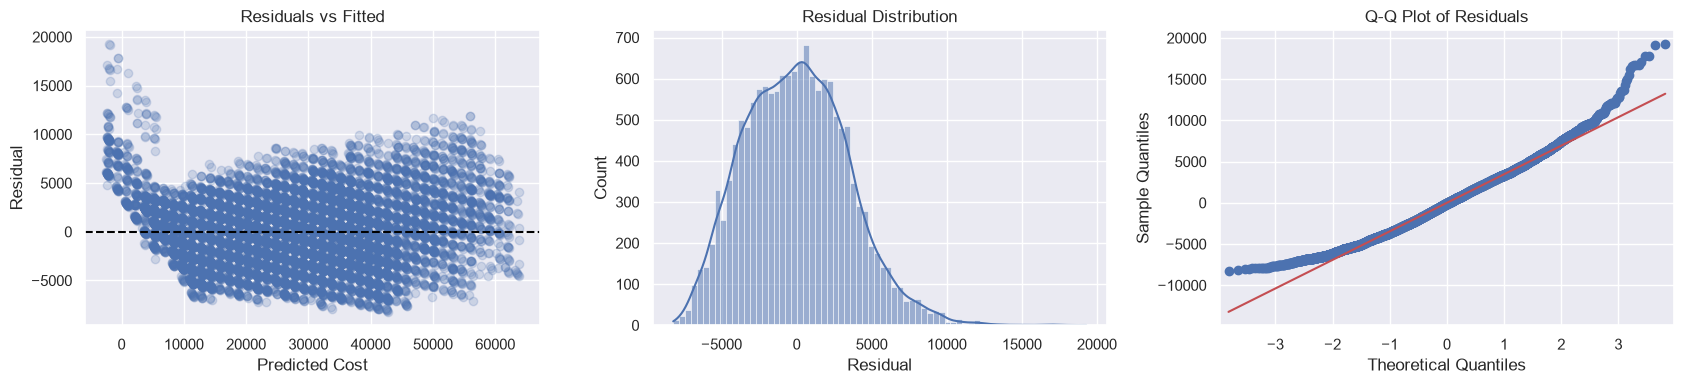

In [88]:
# Generate predictions from the fitted OLS regression model.
ols_predictions = ols_result.predict(ols_X_const)

# Calculate residuals: Actual - Predicted.
ols_residuals = y_train - ols_predictions

# Create three diagnostic plots.
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# 1. Residuals vs Fitted Values
# Check for nonlinearity, unequal variance, and systematic error patterns.
axes[0].scatter(ols_predictions, ols_residuals, alpha=0.2)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set(
    title='Residuals vs Fitted',
    xlabel='Predicted Cost',
    ylabel='Residual'
)

# 2. Residual Distribution
# Check whether residuals are approximately symmetric and bell-shaped.
sns.histplot(ols_residuals, kde=True, ax=axes[1])
axes[1].set(
    title='Residual Distribution',
    xlabel='Residual'
)

# 3. Q-Q Plot
# Compare residual quantiles against a theoretical normal distribution.
# line='s' uses a standardized reference line appropriate for the residual scale.
sm.qqplot(ols_residuals, line='s', ax=axes[2])
axes[2].set_title('Q-Q Plot of Residuals')

# Adjust spacing and display the plots.
plt.tight_layout()
plt.show()

### Observations: OLS Residual Diagnostics

**Residuals vs. Fitted Values**
- The residuals show a structured, banded pattern rather than being randomly scattered around zero.
- This suggests that the linear regression model does not fully capture the relationship between the predictors and insurance cost.
- The residual spread varies across predicted values, suggesting possible heteroscedasticity (nonconstant error variance).

**Residual Distribution**
- The residuals are approximately centered around zero but show positive skewness and a longer right tail.
- Some large positive residuals indicate observations where the model substantially underestimates insurance cost.

**Q-Q Plot**
- The residuals follow the theoretical normal distribution reasonably closely around the center.
- Clear deviations appear in both tails, particularly the upper tail, indicating departures from normality.
- The corrected Q-Q plot supports the residual-distribution findings.

**Conclusion:** The OLS model provides a useful statistical baseline, but its residual patterns suggest limitations in the linear model assumptions. This supports evaluating nonlinear regression methods such as Random Forest and Gradient Boosting.

# **FEATURE ENGINEERING AND OUTLIER TREATMENT EXPERIMENTS**

**Methodology:** Compare the selected feature groups and IQR clipping with a fixed Gradient Boosting configuration. Selection is based on validation RMSE, not training RMSE. This tests whether the experimental health score and outlier treatment actually help.

In [89]:
feature_experiment_results = []
for feature_name, columns in FEATURE_SETS.items():
    for clip_outliers in [False, True]:
        candidate = make_pipeline(
            GradientBoostingRegressor(n_estimators=100, max_depth=3,
                                      random_state=RANDOM_STATE),
            columns, use_iqr=clip_outliers
        )
        candidate.fit(X_train, y_train)
        result = evaluate_regression(candidate, X_val, y_val,
                                     f'{feature_name} | IQR={clip_outliers}')
        result['Feature set'] = feature_name
        result['IQR clipping'] = clip_outliers
        feature_experiment_results.append(result)

feature_experiments_df = pd.DataFrame(feature_experiment_results).sort_values('RMSE')
display(feature_experiments_df)

,Model,RMSE,MAE,R2,Feature set,IQR clipping
6,original_9_plus_admission_category | IQR=False,2948.837974,2372.583165,0.957396,original_9_plus_admission_category,False
7,original_9_plus_admission_category | IQR=True,2948.845126,2372.341755,0.957396,original_9_plus_admission_category,True
8,expanded_features | IQR=False,2953.208013,2376.770401,0.957269,expanded_features,False
9,expanded_features | IQR=True,2953.605906,2377.135385,0.957258,expanded_features,True
4,original_9_plus_risk | IQR=False,2956.473027,2378.590242,0.957175,original_9_plus_risk,False
5,original_9_plus_risk | IQR=True,2958.438635,2380.192474,0.957118,original_9_plus_risk,True
3,original_9_proxy | IQR=True,2958.518813,2378.837354,0.957116,original_9_proxy,True
2,original_9_proxy | IQR=False,2960.808787,2381.554726,0.957049,original_9_proxy,False
0,weight_only | IQR=False,3132.499511,2519.022129,0.951924,weight_only,False
1,weight_only | IQR=True,3132.499511,2519.022129,0.951924,weight_only,True


### Observations: Feature-Set and Outlier Treatment Experiments

Multiple feature configurations were compared using Gradient Boosting, with and without IQR-based clipping.

- The `original_9_plus_admission_category` configuration achieved the lowest validation RMSE of approximately **2,948.84**.
- The expanded feature configuration performed slightly worse, with an RMSE of approximately 2,953.21.
- Adding the experimental health-risk score did not improve performance relative to the best admission-category configuration.
- The weight-only baseline achieved an RMSE of approximately 3,132.50 and an R² of approximately 0.9519.
- IQR clipping produced minimal or inconsistent changes in validation performance.

**Interpretation:** Including the recorded admission-year category provided a small improvement over the other tested feature configurations. Additional features did not automatically lead to better predictive performance.

The strong weight-only baseline indicates that weight accounts for a substantial proportion of the dataset's predictive signal.

**Modeling decision:** The `original_9_plus_admission_category` feature set was selected without IQR clipping, based on its validation RMSE.

**Limitation:** The performance differences between the strongest feature configurations are small and may vary across data splits. Further cross-validation would provide a more reliable comparison.

# **ADVANCED MODEL HYPERPARAMETER TUNING**

**Methodology:** Use only training folds for cross-validation. The best feature set and clipping option come from validation results above. GridSearchCV refits preprocessing within each fold, reducing leakage. The validation set remains available for comparing tuned candidates.

In [90]:
# Select the best feature set based on validation RMSE.
# Keep the selected features and clipping decision explicit for debugging.
selected_row = feature_experiments_df.iloc[0]
selected_feature_set = selected_row['Feature set']
selected_features = FEATURE_SETS[selected_feature_set]
selected_clipping = bool(selected_row['IQR clipping'])

print('Selected feature set:', selected_feature_set)
print('Use IQR clipping:', selected_clipping)


# Define hyperparameter grids for the shortlisted models.
# Small grids are used to keep the tuning process computationally manageable.
tuning_options = {
    'Random Forest Tuned': (
        RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        {
            'model__n_estimators': [100, 150],
            'model__max_depth': [8, None]
        }
    ),

    'Gradient Boosting Tuned': (
        GradientBoostingRegressor(
            random_state=RANDOM_STATE
        ),
        {
            'model__n_estimators': [100, 150],
            'model__learning_rate': [0.05, 0.1],
            'model__max_depth': [3, 5]
        }
    ),

    'XGBoost Tuned': (
        XGBRegressor(
            random_state=RANDOM_STATE,
            objective='reg:squarederror',
            n_jobs=1,
            tree_method='hist'
        ),
        {
            'model__n_estimators': [100, 150],
            'model__learning_rate': [0.05, 0.1],
            'model__max_depth': [3, 5]
        }
    )
}


# Store the best fitted pipeline and validation results for each model.
tuned_models = {}
tuning_results = []

# Tune each model using the same selected features and preprocessing.
for name, (estimator, param_grid) in tuning_options.items():

    print(f'\nTuning model: {name}')

    # Build a pipeline with preprocessing and the regression model.
    # GridSearchCV applies preprocessing separately within each training fold.
    pipeline = make_pipeline(
        estimator,
        selected_features,
        use_iqr=selected_clipping
    )

    # Perform 3-fold cross-validation to find the best hyperparameters.
    search = GridSearchCV(
        pipeline,
        param_grid=param_grid,
        scoring='neg_root_mean_squared_error',
        cv=3,
        n_jobs=-1,
        refit=True
    )

    # Fit the model using training data only.
    search.fit(X_train, y_train)

    # Save the best fitted pipeline for later comparison and evaluation.
    tuned_models[name] = search.best_estimator_

    # Evaluate the tuned model on the validation dataset.
    result = evaluate_regression(
        search.best_estimator_,
        X_val,
        y_val,
        name
    )

    tuning_results.append(result)

    print(name, 'best parameters:', search.best_params_)


# Compare the tuned models using validation RMSE.
tuning_comparison_df = (
    pd.DataFrame(tuning_results)
    .sort_values('RMSE')
    .reset_index(drop=True)
)

display(tuning_comparison_df)

Selected feature set: original_9_plus_admission_category
Use IQR clipping: False

Tuning model: Random Forest Tuned
Random Forest Tuned best parameters: {'model__max_depth': 8, 'model__n_estimators': 150}

Tuning model: Gradient Boosting Tuned
Gradient Boosting Tuned best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 100}

Tuning model: XGBoost Tuned
XGBoost Tuned best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__n_estimators': 150}


,Model,RMSE,MAE,R2
0,XGBoost Tuned,2934.249989,2363.523682,0.957816
1,Gradient Boosting Tuned,2934.513489,2361.337628,0.957809
2,Random Forest Tuned,2984.033487,2391.732043,0.956373


### **Observations: Hyperparameter Tuning and Final Model Selection**

Three ensemble regression models were tuned using GridSearchCV with 3-fold cross-validation.

| Model | Validation RMSE | Validation MAE | R² |
|---|---:|---:|---:|
| XGBoost Tuned | 2,934.25 | 2,363.52 | 0.9578 |
| Gradient Boosting Tuned | 2,934.51 | 2,361.34 | 0.9578 |
| Random Forest Tuned | 2,984.03 | 2,391.73 | 0.9564 |

- XGBoost achieved the lowest validation RMSE of **2,934.25**, marginally outperforming Gradient Boosting by approximately 0.26.
- Gradient Boosting achieved a slightly lower MAE than XGBoost, indicating that the two models performed almost identically.
- Both boosting algorithms outperformed the tuned Random Forest model.



# **MODEL PERFORMANCE COMPARISON AND FINAL SELECTION**

**Methodology:** Select a candidate using validation performance only. Test performance must not influence model selection. The baseline comparisons above used a different feature set, so this final selection compares the tuned models evaluated on the same selected features.

In [91]:
tuning_comparison_df = pd.DataFrame(tuning_results).sort_values('RMSE')
final_model_name = tuning_comparison_df.iloc[0]['Model']
final_pipeline = tuned_models[final_model_name]
print('Final selected model:', final_model_name)
display(tuning_comparison_df)

Final selected model: XGBoost Tuned


,Model,RMSE,MAE,R2
2,XGBoost Tuned,2934.249989,2363.523682,0.957816
1,Gradient Boosting Tuned,2934.513489,2361.337628,0.957809
0,Random Forest Tuned,2984.033487,2391.732043,0.956373


### **Observations: Final Model Selection**

***Modeling Decision:*** XGBoost was selected as the final model based on the lowest validation RMSE, which was the primary evaluation metric.

The small difference between XGBoost and Gradient Boosting indicates that their predictive performance is practically comparable on the validation dataset.

# **FINAL MODEL EVALUATION — HELD-OUT TEST SET**

**Methodology:** The test set is evaluated once after model selection. Compare predictions with actual costs and investigate errors by customer weight group. High feature importance does not establish causation.

In [92]:
final_test_results = evaluate_regression(final_pipeline, X_test, y_test, final_model_name)
print('Held-out test results:')
display(pd.DataFrame([final_test_results]))

y_test_pred = final_pipeline.predict(X_test)
prediction_df = X_test[['weight', 'age']].copy()
prediction_df['Actual Cost'] = y_test.values
prediction_df['Predicted Cost'] = y_test_pred
prediction_df['Absolute Error'] = np.abs(prediction_df['Actual Cost'] - prediction_df['Predicted Cost'])
display(prediction_df.head(10))

Held-out test results:


,Model,RMSE,MAE,R2
0,XGBoost Tuned,2994.366377,2401.330322,0.956557


,weight,age,Actual Cost,Predicted Cost,Absolute Error
1123,81,44,38254,39482.906250,1228.906250
23725,57,57,6170,5926.799316,243.200684
1599,68,19,17276,21246.982422,3970.982422
21425,65,32,18510,16840.210938,1669.789062
6580,77,21,33318,34646.761719,1328.761719
9987,80,37,40722,38552.183594,2169.816406
15256,79,24,39488,37158.085938,2329.914062
11333,79,47,38254,39491.558594,1237.558594
10347,92,33,65402,60038.656250,5363.343750
10229,76,41,38254,34747.648438,3506.351562


### ***Observations: Final Test Performance***

The tuned XGBoost model was evaluated on the held-out test dataset containing 5,000 observations.

- **RMSE:** 2,994.37
- **MAE:** 2,401.33
- **R²:** 0.9566

The model explains approximately **95.66% of the variation in insurance cost** within the held-out test dataset.

The MAE indicates an average absolute prediction error of approximately 2,401 cost units.

The test RMSE is approximately 60.12 higher than the validation RMSE, indicating a modest reduction in performance on unseen data.

**Interpretation:** The selected XGBoost model demonstrates strong predictive performance on the available dataset, with relatively consistent validation and test results.

## **Prediction Error Analysis**

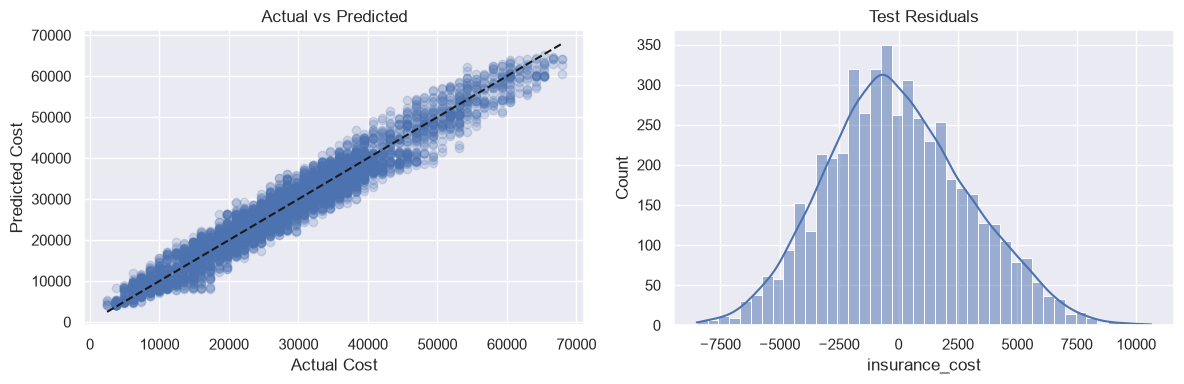

,count,mean,median
Weight Group,,,
"(51.999, 64.0]",1306,1757.071779,1398.315918
"(64.0, 72.0]",1362,2429.371054,2104.720703
"(72.0, 78.0]",1137,2596.072056,2334.248047
"(78.0, 96.0]",1195,2888.182832,2545.671875


In [93]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, y_test_pred, alpha=0.2)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
axes[0].set(xlabel='Actual Cost', ylabel='Predicted Cost', title='Actual vs Predicted')
sns.histplot(y_test - y_test_pred, kde=True, ax=axes[1])
axes[1].set_title('Test Residuals')
plt.tight_layout();plt.show()

prediction_df['Weight Group'] = pd.qcut(prediction_df['weight'], q=4, duplicates='drop')
weight_errors = prediction_df.groupby('Weight Group', observed=True)['Absolute Error'].agg(['count','mean','median'])
display(weight_errors)

### **Observations: Prediction and Residual Analysis**

**Actual vs. Predicted Insurance Cost**

- Predicted values closely follow the diagonal reference line, indicating a strong relationship between actual and predicted insurance costs.
- Some deviations are visible, particularly at higher insurance-cost values.
- The model shows a slight tendency to underestimate some of the highest insurance costs.

**Test Residual Distribution**

- Residuals are approximately centered around zero.
- The distribution is broadly bell-shaped, with some asymmetry and a longer positive tail.
- Most prediction errors are concentrated near zero, while a smaller number of observations show larger deviations.

**Interpretation:** The diagnostic plots support the strong overall predictive performance of the model, while highlighting that individual prediction errors remain present, particularly for some higher-cost observations.



***Prediction errors were evaluated across four weight groups:***

- The lowest weight group has the smallest mean absolute error.
- Prediction errors increase across the higher weight groups.
- The highest weight group has an MAE approximately 64% greater than the lowest group.

**Interpretation:** Although the overall model performance is strong, prediction errors are not uniform across weight groups.

Higher absolute errors may partly reflect higher insurance costs in these groups. Evaluating relative errors would help determine whether the model is proportionally less accurate for higher-weight observations.

## **Feature Importance — Permutation Method**

**Methodology:** Permutation importance measures the validation-performance decrease when one original input column is shuffled. This is a predictive diagnostic, not proof of a causal relationship. Inspect weight dominance rather than automatically dropping weight.

,Raw Feature,Importance (RMSE increase)
16,weight,16620.244141
17,covered_by_any_other_company,161.716471
14,Year_last_admitted,148.416992
1,regular_checkup_last_year,97.215495
0,years_of_insurance_with_us,30.758626
20,weight_change_in_last_one_year,25.624186
7,age,2.238688
12,bmi,0.000000
19,exercise,0.000000
18,Alcohol,0.000000


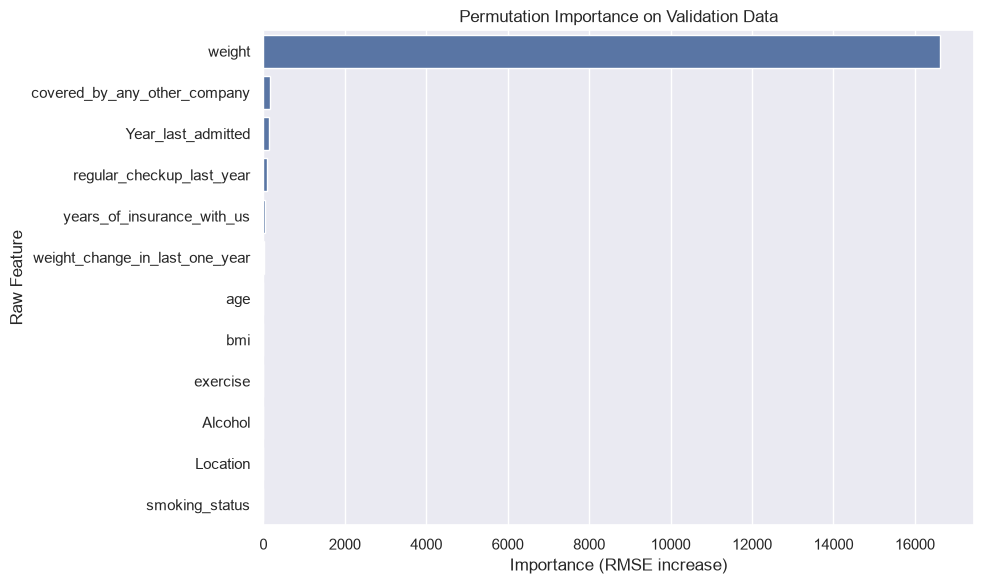

In [94]:
# Use the validation set for model diagnostics, leaving the test set for final reporting.
importance = permutation_importance(
    final_pipeline, X_val, y_val, n_repeats=3,
    random_state=RANDOM_STATE, scoring='neg_root_mean_squared_error', n_jobs=1
)
importance_df = pd.DataFrame({
    'Raw Feature': X_val.columns,
    'Importance (RMSE increase)': importance.importances_mean
}).sort_values('Importance (RMSE increase)', ascending=False)
display(importance_df.head(15))
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(12), x='Importance (RMSE increase)', y='Raw Feature')
plt.title('Permutation Importance on Validation Data')
plt.tight_layout();plt.show()

### **Observations: Permutation Feature Importance**

Permutation importance was calculated to assess the contribution of individual input features to the final XGBoost model.

- **Weight** was the dominant predictor, with an RMSE increase of approximately 16,620 when shuffled.
- `covered_by_any_other_company` and `Year_last_admitted` showed smaller but measurable contributions, with RMSE increases of approximately 162 and 148, respectively.
- `regular_checkup_last_year` contributed an RMSE increase of approximately 97.
- Other variables, including age and weight change, had relatively small importance values.
- Several variables showed approximately zero permutation importance in this evaluation.

**Interpretation:** The model relies heavily on weight, consistent with the strong performance of the weight-only baseline.

Permutation importance was calculated using the original input columns supplied to the complete pipeline. Therefore, the importance reported for `Year_last_admitted` reflects the combined effect of its engineered admission-history representations.

Features with zero permutation importance did not measurably improve predictions under this evaluation. This does not imply that they have no relationship with insurance cost.

Feature importance reflects model behavior rather than medical causation.

# **EXPORT TRAINED MODEL AND TEST INFERENCE**

**Methodology:** Save the entire fitted pipeline (feature engineering, imputation, encoding, scaling, optional clipping, and estimator) as one artifact. This prevents different transformations being applied during training and deployment. Never load untrusted `.joblib` files.

In [95]:
import joblib
import json
from pathlib import Path

# Save inside the project's models folder
# Save inside the project's models folder
model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "insurance_pipeline.joblib"
joblib.dump(final_pipeline, model_path)

# Record model identity and evaluation metrics for reproducibility.
training_report = {
    'selected_model': final_model_name,
    'selected_feature_set': selected_feature_set,
    'selected_features': selected_features,
    'iqr_clipping': selected_clipping,
    'validation_results': tuning_comparison_df.to_dict(orient='records'),
    'test_results': final_test_results,
    'random_state': RANDOM_STATE,
    'admission_year_handling': 'Recorded year as category; missing as Unknown; no year imputation',
}
with open(model_dir / 'training_report.json', 'w') as report_file:
    json.dump(training_report, report_file, indent=2)

# Test loading the model and predicting on an untouched row.
loaded_pipeline = joblib.load(model_path)
example_customer = X_test.iloc[[0]].copy()
print('Prediction from loaded model:', loaded_pipeline.predict(example_customer)[0])
print('Actual cost:', y_test.iloc[0])
print('Saved model to:', model_path)

Prediction from loaded model: 39482.906
Actual cost: 38254
Saved model to: /Users/tasmiyasana/Desktop/projects/GenAI-Health-Risk-Cost-Advisor/models/insurance_pipeline.joblib


In [96]:
from pathlib import Path

# Check the project's models folder
model_folder = PROJECT_ROOT / "models"

print("Model folder:", model_folder)
print("Folder exists:", model_folder.exists())

# Show all files saved in the models folder
if model_folder.exists():
    for file in model_folder.iterdir():
        print("Found:", file.name)

Model folder: /Users/tasmiyasana/Desktop/projects/GenAI-Health-Risk-Cost-Advisor/models
Folder exists: True
Found: insurance_pipeline.joblib
Found: training_report.json


### **Observations: Model Serialization and Inference Verification**

The final tuned XGBoost pipeline was saved using Joblib at:

`models/insurance_pipeline.joblib`

The saved pipeline was reloaded and tested using an observation from the test dataset.

- Actual insurance cost: **38,254**
- Predicted insurance cost: **39,482.91**
- Absolute prediction error: **1,228.91**

**Interpretation:** The successful prediction confirms that the serialized pipeline can be loaded and used for inference within the current environment.

The saved pipeline includes the preprocessing transformations required to process raw input features.

For deployment, the custom transformer module and compatible versions of the required Python libraries, including XGBoost, must be available.

### **Conclusion**

This project developed an end-to-end machine learning workflow for insurance cost prediction using 25,000 observations.

The analysis included exploratory data analysis, data validation, feature engineering, statistical diagnostics, baseline model comparison, feature-set experiments, hyperparameter tuning, and evaluation on a held-out test dataset.

After tuning Random Forest, Gradient Boosting, and XGBoost, **XGBoost was selected as the final model** based on its validation RMSE.

The final model achieved:

- **RMSE:** 2,994.37
- **MAE:** 2,401.33
- **R²:** 0.9566

Weight emerged as the dominant predictor, while admission-history information and selected insurance-related variables contributed smaller improvements.

The experiments also showed that adding more features or applying IQR-based clipping did not consistently improve predictive performance.

Although the model demonstrates strong performance on the available dataset, its generalizability to independent insurance datasets remains unverified.

The trained pipeline was exported for integration into a future FastAPI-based prediction service, with Gemini and retrieval-augmented generation (RAG) planned for grounded explanations and document intelligence.

## **ACTIONABLE INSIGHTS AND BUSINESS RECOMMENDATIONS**

**Key Findings**

- The tuned XGBoost model achieved an R² of 0.9566 and an RMSE of 2,994.37 on the test set. Gradient Boosting performed almost equally well during validation, with an RMSE difference of only 0.26. XGBoost was selected because RMSE was the primary evaluation metric.

- One interesting finding was how strongly insurance cost depended on weight. Even the weight-only model achieved an R² of approximately 0.95. Adding other features improved performance, but the improvement was relatively small. This was also reflected in the permutation importance results, where weight had a much greater impact on prediction error than the other variables.

- The dataset also showed a structured pattern in insurance costs, with values occurring in fixed increments. Since the dataset was provided by the institute without details about how the target was generated, the strong weight-cost relationship needs further validation.

- Admission-year information provided a small improvement in prediction accuracy. However, the engineered `health_risk_score`, despite showing an increasing trend in insurance costs during EDA, did not improve model performance. This shows that a feature can have a visible relationship with the target without necessarily adding useful predictive information to the model.

- Prediction errors also varied across weight groups. The mean absolute error increased from approximately 1,757 in the lowest weight group to 2,888 in the highest group.



**Business Recommendations**

Based on these findings, the trained model could be used as the starting point for an insurance cost estimation prototype.

Before using it with real customer data, the following areas would need attention:

- **Validate the dataset:** Check whether the strong relationship between weight and insurance cost holds in an independent dataset.
- **Evaluate prediction errors across groups:** Compare model performance across different weight and age ranges instead of relying only on overall accuracy.
- **Review feature relevance:** Focus on features that improve validation performance rather than adding more variables unnecessarily.
- **Provide understandable predictions:** Display the estimated cost along with relevant model explanations and a clear indication that it is not an official insurance quotation.

The current results are useful for demonstrating the prediction workflow, but additional validation would be required before considering the model for actual insurance pricing.

## **LIMITATIONS AND FUTURE SCOPE**

### **Limitations**

The dataset was provided as part of an academic program, and its original source and target-generation process are not documented. The strong correlation between weight and insurance cost, along with the structured target values, suggests that some relationships may be specific to this dataset.

The model was evaluated using a training, validation, and test split. Although the validation and test results were fairly consistent, performance on an independent dataset has not been tested.

Another limitation is the missing admission-year information. Nearly half of the observations do not have a recorded admission year. These values were treated as unknown rather than assuming that no hospitalization had occurred.

The model also showed differences in prediction errors across weight groups. Further analysis would be needed to understand whether similar differences exist across other customer segments.

Finally, the model identifies statistical patterns in the provided data. Its predictions and feature importance values should not be interpreted as clinically validated health-risk assessments or actual insurance premiums.

### **Future Scope**

The next step is to integrate the trained XGBoost pipeline into an application rather than keeping it limited to the notebook.

**1. Model Deployment**

Build a FastAPI service that loads the saved model and returns predictions through an API. Input validation will be added to handle missing or invalid customer information.

**2. Gemini Integration**

Use Gemini to explain the predicted cost in simpler language. The cost itself will come from the trained ML model, while Gemini will be responsible for generating explanations based on the model output and available supporting information.

**3. RAG-Based Document Intelligence**

Extend the application to support uploaded insurance policy documents. RAG can be used to retrieve relevant policy information and answer questions based on the uploaded documents rather than relying entirely on the LLM's existing knowledge.

**4. Deployment and Monitoring**

Containerize the application using Docker and introduce automated testing and CI/CD. Model monitoring can be added later to track prediction errors and changes in input data.

**5. Further Model Evaluation**

Test the model on independent data, compare prediction errors across customer groups, and explore SHAP for explaining individual predictions.

### **Conclusion**

The project covers the complete ML workflow, from data exploration and preprocessing to model comparison, tuning, evaluation, and saving the final pipeline.

XGBoost achieved an R² of 0.9566 on the test set, although Gradient Boosting gave very similar results. The experiments also highlighted the importance of checking feature relevance and understanding the dataset instead of focusing only on achieving a high accuracy score.

The next phase will focus on turning the trained model into a usable application with API-based predictions and GenAI-supported document intelligence.